# Proyecto #1: Exploratory Data Analysis (EDA) - Predict Future Sales

**Dataset:** [Predict Future Sales (Kaggle)](https://www.kaggle.com/competitions/competitive-data-science-predict-future-sales/data)

## Descripción del proyecto

El dataset contiene las ventas diarias de una cadena de tiendas rusas (1C Company). El objetivo final de la competencia es predecir las ventas **mensuales** de cada par tienda-producto para noviembre de 2015. Este EDA prepara el terreno para esa etapa de *forecasting*.

Archivos del dataset (ubicados en `data/raw/`, no versionados):

| Archivo | Contenido |
|---|---|
| `sales_train.csv` | Ventas diarias históricas (train) |
| `items.csv` | Catálogo de productos |
| `item_categories.csv` | Catálogo de categorías |
| `shops.csv` | Catálogo de tiendas (sucursales) |
| `test.csv` | Pares tienda-producto a predecir (nov 2015) |

## Índice

1. Estructura del proyecto y repositorio
0. Configuración del entorno
2. Comprensión inicial del dataset
3. Validación de la estructura de los datos
4. Análisis de valores faltantes y duplicados
5. Análisis descriptivo general
6. Exploración temporal
7. Análisis comparativo entre sucursales y productos
8. Visualizaciones clave (obligatorias)
9. Autocorrelación (ACF) y autocorrelación parcial (PACF)
10. Insights y conclusiones del EDA

## 1. Estructura del proyecto y repositorio

Esta sección se cumple a nivel de repositorio, no dentro del notebook:
- **a.** La estructura del proyecto se generó con la plantilla oficial **Cookiecutter Data Science** (`ccds` v2.3.0).
- **b.** Este notebook se encuentra en `notebooks/01_exploratory_data_analysis.ipynb`.
- **c.** El proyecto es un repositorio local de **git**.
- **d.** El `.gitignore` excluye los datos de Kaggle (CSV y ZIP, unos 100 MB), el entorno virtual y las credenciales.
- **e.** El repositorio está publicado en GitHub: <https://github.com/SaulD-sys/predict-future-sales-eda>.
- **f.** Los *screenshots* del *pull* de cada integrante se entregan por separado.

Los archivos de Kaggle deben colocarse en `data/raw/` para ejecutar el notebook (ver `README.md`).

## 0. Configuración del entorno

Librerías, rutas relativas al proyecto (estructura Cookiecutter Data Science) y opciones de visualización de tablas. Los CSV originales se **leen** desde `data/raw/` y nunca se modifican: toda transformación se hace sobre copias en memoria.

In [1]:
import re
import sys
from pathlib import Path

import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.float_format", "{:,.2f}".format)

# Raíz del proyecto: el notebook vive en notebooks/
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_DIR = PROJECT_ROOT / "data" / "raw"

print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | numpy {np.__version__}")
print(f"Directorio de datos: {RAW_DIR.relative_to(PROJECT_ROOT).as_posix()} (existe: {RAW_DIR.exists()})")

Python 3.12.13 | pandas 3.1.1 | numpy 2.5.4
Directorio de datos: data/raw (existe: True)


## 2. Comprensión inicial del dataset

### 2a. Carga de los archivos y primeras filas
Se cargan los cinco archivos obligatorios indicados en las instrucciones.

In [2]:
ARCHIVOS = {
    "sales_train": "sales_train.csv",
    "items": "items.csv",
    "item_categories": "item_categories.csv",
    "shops": "shops.csv",
    "test": "test.csv",
}

datos = {nombre: pd.read_csv(RAW_DIR / archivo) for nombre, archivo in ARCHIVOS.items()}

sales = datos["sales_train"]
items = datos["items"]
item_categories = datos["item_categories"]
shops = datos["shops"]
test = datos["test"]

In [3]:
for nombre, df in datos.items():
    print(f"\n=== {ARCHIVOS[nombre]} ===")
    display(df.head())


=== sales_train.csv ===


,date,date_block_num,shop_id,item_id,item_price,item_cnt_day
0,02.01.2013,0,59,22154,999.00,1.00
1,03.01.2013,0,25,2552,899.00,1.00
2,05.01.2013,0,25,2552,899.00,-1.00
3,06.01.2013,0,25,2554,"1,709.05",1.00
4,15.01.2013,0,25,2555,"1,099.00",1.00



=== items.csv ===


,item_name,item_id,item_category_id
0,! ВО ВЛАСТИ НАВАЖДЕНИЯ (ПЛАСТ.) D,0,40
1,"!ABBYY FineReader 12 Professional Edition Full [PC, Цифровая версия]",1,76
2,***В ЛУЧАХ СЛАВЫ (UNV) D,2,40
3,***ГОЛУБАЯ ВОЛНА (Univ) D,3,40
4,***КОРОБКА (СТЕКЛО) D,4,40



=== item_categories.csv ===


,item_category_name,item_category_id
0,PC - Гарнитуры/Наушники,0
1,Аксессуары - PS2,1
2,Аксессуары - PS3,2
3,Аксессуары - PS4,3
4,Аксессуары - PSP,4



=== shops.csv ===


,shop_name,shop_id
0,"!Якутск Орджоникидзе, 56 фран",0
1,"!Якутск ТЦ ""Центральный"" фран",1
2,"Адыгея ТЦ ""Мега""",2
3,"Балашиха ТРК ""Октябрь-Киномир""",3
4,"Волжский ТЦ ""Волга Молл""",4



=== test.csv ===


,ID,shop_id,item_id
0,0,5,5037
1,1,5,5320
2,2,5,5233
3,3,5,5232
4,4,5,5268


### 2b. Tamaño de cada tabla

In [4]:
dimensiones = pd.DataFrame(
    {
        "archivo": [ARCHIVOS[n] for n in datos],
        "filas": [df.shape[0] for df in datos.values()],
        "columnas": [df.shape[1] for df in datos.values()],
        "memoria_MB": [df.memory_usage(deep=True).sum() / 2**20 for df in datos.values()],
    }
).set_index("archivo")
dimensiones.style.format({"filas": "{:,}", "memoria_MB": "{:,.2f}"})

,filas,columnas,memoria_MB
archivo,,,
sales_train.csv,"2,935,849",6,277.18
items.csv,"22,170",3,3.34
item_categories.csv,84,2,0.01
shops.csv,60,2,0.01
test.csv,"214,200",3,4.90


**Interpretación.** `sales_train.csv` es la tabla de hechos (2,935,849 transacciones diarias); `items`, `item_categories` y `shops` son catálogos que se unen por sus identificadores, y `test.csv` contiene 214,200 pares tienda-producto a predecir. El volumen total cabe holgadamente en memoria, por lo que no es necesario procesar por lotes.

### 2c. Diccionario de datos y variable objetivo

| Columna | Archivo(s) | Descripción |
|---|---|---|
| `date` | sales_train | Fecha de la transacción (texto con formato `dd.mm.aaaa` en el archivo original). |
| `date_block_num` | sales_train | Número de mes consecutivo: 0 = enero 2013, …, 33 = octubre 2015. |
| `shop_id` | sales_train, shops, test | Identificador único de la tienda (sucursal). |
| `item_id` | sales_train, items, test | Identificador único del producto. |
| `item_price` | sales_train | Precio unitario del producto en esa transacción. El dataset no indica la moneda; por tratarse de una cadena rusa, en este notebook se asumen **rublos**. |
| `item_cnt_day` | sales_train | Unidades vendidas en el día; los valores negativos representan devoluciones. |
| `item_name` | items | Nombre del producto (en ruso). |
| `item_category_id` | items, item_categories | Identificador de la categoría del producto. |
| `item_category_name` | item_categories | Nombre de la categoría (en ruso). |
| `shop_name` | shops | Nombre de la tienda, que incluye ciudad y centro comercial (en ruso). |

Columna adicional de `test.csv`: `ID`, identificador de cada par tienda-producto a predecir.

**Variable objetivo.** La competencia pide predecir las **ventas mensuales en unidades** de cada par tienda-producto para noviembre de 2015 (`date_block_num = 34`). Esa variable (`item_cnt_month`) no existe directamente en los datos: se construye **sumando `item_cnt_day` por mes, tienda y producto**. Por eso, en este EDA la métrica principal son las unidades vendidas (`item_cnt_day`) y los ingresos (`item_price × item_cnt_day`) se usan como métrica complementaria.

In [5]:
# Verificación: las diez columnas del diccionario existen en los archivos cargados
columnas_pdf = ["date", "date_block_num", "shop_id", "item_id", "item_price", "item_cnt_day",
                "item_name", "item_category_id", "item_category_name", "shop_name"]
presentes = {c: [n for n, df in datos.items() if c in df.columns] for c in columnas_pdf}
pd.Series(presentes, name="presente_en").to_frame()

,presente_en
date,[sales_train]
date_block_num,[sales_train]
shop_id,"[sales_train, shops, test]"
item_id,"[sales_train, items, test]"
item_price,[sales_train]
item_cnt_day,[sales_train]
item_name,[items]
item_category_id,"[items, item_categories]"
item_category_name,[item_categories]
shop_name,[shops]


### 2d. Rango temporal
La columna `date` se interpreta aquí con su formato explícito para obtener el rango; la conversión definitiva del tipo se valida en la sección 3b.

In [6]:
fechas = pd.to_datetime(sales["date"], format="%d.%m.%Y")

rango = pd.Series(
    {
        "fecha_minima": fechas.min().date(),
        "fecha_maxima": fechas.max().date(),
        "dias_calendario": (fechas.max() - fechas.min()).days + 1,
        "meses_calendario": fechas.dt.to_period("M").nunique(),
        "date_block_num_min": sales["date_block_num"].min(),
        "date_block_num_max": sales["date_block_num"].max(),
        "date_block_num_distintos": sales["date_block_num"].nunique(),
    },
    name="valor",
)
rango.to_frame()

,valor
fecha_minima,2013-01-01
fecha_maxima,2015-10-31
dias_calendario,1034
meses_calendario,34
date_block_num_min,0
date_block_num_max,33
date_block_num_distintos,34


**Interpretación.** El histórico va del **1 de enero de 2013 al 31 de octubre de 2015**: 1,034 días calendario y **34 meses** completos (`date_block_num` de 0 a 33, sin huecos). El mes a predecir (noviembre 2015) es el inmediatamente posterior al último mes observado.

## 3. Validación de la estructura de los datos

### 3a. Tipos de datos y clasificación de variables

In [7]:
tipo_conceptual = {
    "date": "Fecha (texto en el archivo original)",
    "date_block_num": "Numérica discreta: índice temporal mensual",
    "shop_id": "Categórica nominal (identificador)",
    "item_id": "Categórica nominal (identificador)",
    "item_category_id": "Categórica nominal (identificador)",
    "ID": "Identificador de fila (test)",
    "item_price": "Numérica continua",
    "item_cnt_day": "Numérica discreta (conteo; admite negativos)",
    "item_name": "Categórica / texto",
    "item_category_name": "Categórica / texto",
    "shop_name": "Categórica / texto",
}

tipos = pd.DataFrame(
    [
        {
            "tabla": nombre,
            "columna": col,
            "dtype_pandas": str(df[col].dtype),
            "valores_unicos": df[col].nunique(),
            "tipo_conceptual": tipo_conceptual[col],
        }
        for nombre, df in datos.items()
        for col in df.columns
    ]
)
tipos

,tabla,columna,dtype_pandas,valores_unicos,tipo_conceptual
0,sales_train,date,str,1034,Fecha (texto en el archivo original)
1,sales_train,date_block_num,int64,34,Numérica discreta: índice temporal mensual
2,sales_train,shop_id,int64,60,Categórica nominal (identificador)
3,sales_train,item_id,int64,21807,Categórica nominal (identificador)
4,sales_train,item_price,float64,19993,Numérica continua
5,sales_train,item_cnt_day,float64,198,Numérica discreta (conteo; admite negativos)
6,items,item_name,str,22170,Categórica / texto
7,items,item_id,int64,22170,Categórica nominal (identificador)
8,items,item_category_id,int64,84,Categórica nominal (identificador)
9,item_categories,item_category_name,str,84,Categórica / texto


In [8]:
# item_cnt_day se lee como float64: ¿contiene valores no enteros?
no_enteros = (sales["item_cnt_day"] % 1 != 0).sum()
print(f"Valores no enteros en item_cnt_day: {no_enteros:,}")

Valores no enteros en item_cnt_day: 0


**Interpretación.**
- `date` se lee como texto (`str`), no como fecha: requiere conversión (3b).
- Los identificadores (`shop_id`, `item_id`, `item_category_id`) se leen como enteros, pero conceptualmente son **categóricos**: no tiene sentido sumarlos ni promediarlos.
- `item_cnt_day` se lee como `float64` aunque todos sus valores son enteros (es un conteo).
- `item_price` es la única variable continua.

### 3b. Conversión de `date` a datetime
Se convierte con el formato explícito `%d.%m.%Y` y `errors="coerce"`, de modo que cualquier valor que no cumpla el formato quede como `NaT` y sea detectable. La conversión se hace **en memoria**; el CSV original no se modifica.

In [9]:
fecha_texto = sales["date"].copy()
fecha_dt = pd.to_datetime(fecha_texto, format="%d.%m.%Y", errors="coerce")

validacion_fecha = pd.Series(
    {
        "registros": len(fecha_dt),
        "fechas_no_convertibles (NaT)": int(fecha_dt.isna().sum()),
        "ida_y_vuelta_identica": bool((fecha_dt.dt.strftime("%d.%m.%Y") == fecha_texto).all()),
    },
    name="resultado",
)
display(validacion_fecha.to_frame())

sales["date"] = fecha_dt
print(f"dtype de date tras la conversión: {sales['date'].dtype}")

,resultado
registros,2935849
fechas_no_convertibles (NaT),0
ida_y_vuelta_identica,True


dtype de date tras la conversión: datetime64[us]


**Interpretación.** Las 2,935,849 fechas se convirtieron sin ningún `NaT`, y al volver a formatearlas como `dd.mm.aaaa` se obtiene exactamente el texto original. El formato es consistente en todo el archivo y no hubo inversión de día y mes.

### 3c. Frecuencia temporal

#### Días sin registros vs. días con ventas cero
Se distinguen dos situaciones:
- **Día sin registros:** no aparece ninguna fila en esa fecha.
- **Día con ventas cero:** aparece en los datos pero sus unidades suman 0 (o hay filas con `item_cnt_day = 0`).

In [10]:
calendario = pd.date_range(sales["date"].min(), sales["date"].max(), freq="D")
dias_con_registros = pd.DatetimeIndex(sales["date"].unique())
dias_sin_registros = calendario.difference(dias_con_registros)

unidades_dia = sales.groupby("date")["item_cnt_day"].sum()
filas_dia = sales.groupby("date").size()

frecuencia = pd.Series(
    {
        "dias_calendario": len(calendario),
        "dias_con_registros": len(dias_con_registros),
        "dias_sin_registros": len(dias_sin_registros),
        "dias_con_unidades_netas_<=_0": int((unidades_dia <= 0).sum()),
        "filas_con_item_cnt_day_=_0": int((sales["item_cnt_day"] == 0).sum()),
        "filas_por_dia_min": int(filas_dia.min()),
        "filas_por_dia_mediana": int(filas_dia.median()),
        "filas_por_dia_max": int(filas_dia.max()),
    },
    name="valor",
)
frecuencia.to_frame()

,valor
dias_calendario,1034
dias_con_registros,1034
dias_sin_registros,0
dias_con_unidades_netas_<=_0,0
filas_con_item_cnt_day_=_0,0
filas_por_dia_min,1123
filas_por_dia_mediana,2590
filas_por_dia_max,9434


A nivel de toda la cadena no faltan días. Pero el forecasting se hace por tienda y producto, así que también se revisa la cobertura diaria **por tienda**, dentro de su propio periodo de actividad (de su primera a su última fecha con registros).

In [11]:
cobertura = sales.groupby("shop_id")["date"].agg(
    primera_fecha="min", ultima_fecha="max", dias_con_registros="nunique"
)
cobertura["dias_en_su_rango"] = (cobertura["ultima_fecha"] - cobertura["primera_fecha"]).dt.days + 1
cobertura["dias_sin_registros"] = cobertura["dias_en_su_rango"] - cobertura["dias_con_registros"]
cobertura["pct_dias_sin_registros"] = 100 * cobertura["dias_sin_registros"] / cobertura["dias_en_su_rango"]
cobertura = cobertura.join(shops.set_index("shop_id")["shop_name"])

print(f"Tiendas con registros: {len(cobertura)}")
print(f"Tiendas sin ningún día faltante en su rango: {(cobertura['dias_sin_registros'] == 0).sum()}")
print(f"Tiendas activas en todo el histórico (01.01.2013–31.10.2015): "
      f"{((cobertura['primera_fecha'] == sales['date'].min()) & (cobertura['ultima_fecha'] == sales['date'].max())).sum()}")
cobertura.sort_values("pct_dias_sin_registros", ascending=False).head(10)

Tiendas con registros: 60
Tiendas sin ningún día faltante en su rango: 11
Tiendas activas en todo el histórico (01.01.2013–31.10.2015): 12


,primera_fecha,ultima_fecha,dias_con_registros,dias_en_su_rango,dias_sin_registros,pct_dias_sin_registros,shop_name
shop_id,,,,,,,
9,2013-10-03,2015-10-14,14,742,728,98.11,Выездная Торговля
20,2014-10-02,2015-10-04,9,368,359,97.55,"Москва ""Распродажа"""
12,2013-01-03,2015-10-30,826,1031,205,19.88,Интернет-магазин ЧС
33,2014-08-29,2015-04-24,201,239,38,15.90,"Мытищи ТРК ""XL-3"""
27,2013-01-01,2015-09-30,899,1003,104,10.37,"Москва ТЦ ""МЕГА Белая Дача II"""
8,2013-01-01,2013-04-01,84,91,7,7.69,"Воронеж ТРЦ Сити-Парк ""Град"""
10,2013-01-02,2015-10-31,1001,1033,32,3.10,Жуковский ул. Чкалова 39м?
4,2013-01-02,2015-10-31,1010,1033,23,2.23,"Волжский ТЦ ""Волга Молл"""
24,2013-01-02,2015-10-31,1012,1033,21,2.03,"Москва ТК ""Буденовский"" (пав.К7)"


In [12]:
# A nivel tienda-producto los datos son dispersos: proporción de combinaciones tienda-producto-mes con ventas
pares = sales[["shop_id", "item_id"]].drop_duplicates()
celdas_con_venta = sales[["shop_id", "item_id", "date_block_num"]].drop_duplicates()
pct_llenas = 100 * len(celdas_con_venta) / (len(pares) * sales["date_block_num"].nunique())
print(f"Pares tienda-producto con al menos una venta: {len(pares):,}")
print(f"Celdas tienda-producto-mes con registros: {len(celdas_con_venta):,} "
      f"({pct_llenas:.2f}% de {len(pares):,} pares × 34 meses)")

Pares tienda-producto con al menos una venta: 424,124
Celdas tienda-producto-mes con registros: 1,609,124 (11.16% de 424,124 pares × 34 meses)


**Interpretación.**
- **No hay días sin registros a nivel cadena:** los 1,034 días del calendario tienen transacciones (mínimo 1,123 filas en un día), y ningún día tiene unidades netas ≤ 0.
- **No existen filas con `item_cnt_day = 0`.** El archivo solo registra movimientos (ventas o devoluciones): cuando una tienda no vende un producto en un día, **no hay fila**. Las ventas cero son implícitas, y al construir series por tienda-producto habrá que **completar con 0** los periodos sin registro.
- **A nivel tienda sí hay huecos:** solo 11 de las 60 tiendas (IDs originales) tienen registros todos los días de su rango de actividad, y solo 12 tienen registros desde el primer día del histórico (01.01.2013) hasta el último (31.10.2015). Destacan:
  - `Выездная Торговля` (shop 9, "venta itinerante") y `Москва "Распродажа"` (shop 20, "liquidación"): registran ventas en muy pocos días (14 y 9), es decir, operan de forma esporádica.
  - Tiendas que abren o cierran dentro del periodo (por ejemplo, la shop 8 solo opera de enero a abril de 2013).
- **A nivel tienda-producto los datos son muy dispersos:** de los 424,124 pares con alguna venta, solo el 11.16 % de sus combinaciones par × mes tiene registros.

#### Consistencia de `date_block_num` con el mes calendario
Se recalcula el bloque esperado como `(año − 2013) × 12 + (mes − 1)` y se compara con `date_block_num`.

In [13]:
bloque_calculado = (sales["date"].dt.year - 2013) * 12 + sales["date"].dt.month - 1
inconsistencias = int((bloque_calculado != sales["date_block_num"]).sum())
print(f"Registros con date_block_num inconsistente: {inconsistencias:,}")

bloques = sales.groupby("date_block_num")["date"].agg(fecha_min="min", fecha_max="max", dias_con_registros="nunique")
bloques["mes_calendario"] = bloques["fecha_min"].dt.strftime("%Y-%m")
bloques["dias_del_mes"] = bloques["fecha_min"].dt.days_in_month
bloques["mes_completo"] = bloques["dias_con_registros"] == bloques["dias_del_mes"]
print(f"Bloques que cubren su mes calendario completo: {bloques['mes_completo'].sum()} de {len(bloques)}")
bloques

Registros con date_block_num inconsistente: 0


Bloques que cubren su mes calendario completo: 34 de 34


,fecha_min,fecha_max,dias_con_registros,mes_calendario,dias_del_mes,mes_completo
date_block_num,,,,,,
0,2013-01-01,2013-01-31,31,2013-01,31,True
1,2013-02-01,2013-02-28,28,2013-02,28,True
2,2013-03-01,2013-03-31,31,2013-03,31,True
3,2013-04-01,2013-04-30,30,2013-04,30,True
4,2013-05-01,2013-05-31,31,2013-05,31,True
5,2013-06-01,2013-06-30,30,2013-06,30,True
6,2013-07-01,2013-07-31,31,2013-07,31,True
7,2013-08-01,2013-08-31,31,2013-08,31,True
8,2013-09-01,2013-09-30,30,2013-09,30,True


**Interpretación.** Los 2,935,849 registros tienen un `date_block_num` consistente con su mes calendario (0 inconsistencias), y cada uno de los 34 bloques cubre exactamente su mes completo, sin días faltantes. `date_block_num` puede usarse con confianza como índice mensual.

#### Conclusión sobre la frecuencia de agregación
- **Mensual (frecuencia principal).** La variable objetivo de la competencia es mensual (`item_cnt_month`), `test.csv` pide un único mes y `date_block_num` es un índice mensual completo y consistente. Además, a nivel tienda-producto los datos diarios son extremadamente dispersos: la mayoría de los días no tiene registro. Agregar por mes reduce ese ruido y alinea el análisis con el objetivo de forecasting.
- **Diaria (complementaria, solo para la serie total).** La serie total no tiene huecos, así que sirve para estudiar patrones de día de la semana (sección 6) y la ACF/PACF diaria que piden las instrucciones (sección 9).
- **Semanal:** se usará solo como vista descriptiva (sección 5b). No conviene para el modelo, porque las semanas no coinciden con los límites de los meses a predecir.

## 4. Análisis de valores faltantes y duplicados

### 4a. Valores nulos
Además de los `NaN`, se revisan los textos vacíos o compuestos solo por espacios, que no cuentan como nulos pero equivalen a un faltante.

In [14]:
nulos = []
for nombre, df in datos.items():
    for col in df.columns:
        es_texto = df[col].dtype == object or pd.api.types.is_string_dtype(df[col])
        nulos.append(
            {
                "tabla": nombre,
                "columna": col,
                "nulos": int(df[col].isna().sum()),
                "pct_nulos": 100 * df[col].isna().mean(),
                "textos_vacios": int(df[col].astype(str).str.strip().eq("").sum()) if es_texto else 0,
            }
        )
nulos = pd.DataFrame(nulos)
print(f"Total de valores nulos en los cinco archivos: {nulos['nulos'].sum()}")
print(f"Total de textos vacíos: {nulos['textos_vacios'].sum()}")
nulos

Total de valores nulos en los cinco archivos: 0
Total de textos vacíos: 0


,tabla,columna,nulos,pct_nulos,textos_vacios
0,sales_train,date,0,0.00,0
1,sales_train,date_block_num,0,0.00,0
2,sales_train,shop_id,0,0.00,0
3,sales_train,item_id,0,0.00,0
4,sales_train,item_price,0,0.00,0
5,sales_train,item_cnt_day,0,0.00,0
6,items,item_name,0,0.00,0
7,items,item_id,0,0.00,0
8,items,item_category_id,0,0.00,0
9,item_categories,item_category_name,0,0.00,0


**Interpretación.** Ninguna de las 16 columnas de los cinco archivos tiene valores nulos (0 %) ni textos vacíos.

**Estrategia de tratamiento de faltantes.**
- **Faltantes explícitos:** no se requiere eliminación ni imputación, porque no los hay.
- **Faltantes implícitos:** son los periodos tienda-producto sin fila, identificados en 3c. No son datos perdidos sino **ausencia de ventas**, y se tratarán como **0 unidades** al construir series mensuales por tienda o tienda-producto.
- **Precio en meses sin venta:** no se imputa, porque sin transacción no existe precio.

### 4b. Estrategia de tratamiento y valores inválidos

#### Precios menores o iguales a cero
Se separan los dos casos: precio negativo (`< 0`) y precio cero (`= 0`).

In [15]:
precio_negativo = sales[sales["item_price"] < 0]
precio_cero = sales[sales["item_price"] == 0]

pd.DataFrame(
    {
        "registros": [len(precio_negativo), len(precio_cero)],
        "pct_registros": [100 * len(precio_negativo) / len(sales), 100 * len(precio_cero) / len(sales)],
    },
    index=["item_price < 0", "item_price = 0"],
).style.format({"pct_registros": "{:.5f}%"})

,registros,pct_registros
item_price < 0,1,0.00003%
item_price = 0,0,0.00000%


In [16]:
display(precio_negativo.merge(items, on="item_id", how="left"))

# Contexto: precios válidos del mismo producto
fila = precio_negativo.iloc[0]
validos = sales[(sales["item_id"] == fila["item_id"]) & (sales["item_price"] > 0)]
mismo_contexto = validos[(validos["shop_id"] == fila["shop_id"]) & (validos["date_block_num"] == fila["date_block_num"])]

pd.Series(
    {
        "registros_validos_del_producto": len(validos),
        "precio_mediano_del_producto": validos["item_price"].median(),
        "registros_misma_tienda_y_mes": len(mismo_contexto),
        "precio_mediano_misma_tienda_y_mes": mismo_contexto["item_price"].median(),
        "precios_distintos_misma_tienda_y_mes": sorted(mismo_contexto["item_price"].unique().tolist()),
    },
    name="valor",
).to_frame()

,date,date_block_num,shop_id,item_id,item_price,item_cnt_day,item_name,item_category_id
0,2013-05-15,4,32,2973,-1.00,1.00,"DmC Devil May Cry [PS3, русские субтитры]",19


,valor
registros_validos_del_producto,779
precio_mediano_del_producto,"2,499.00"
registros_misma_tienda_y_mes,2
precio_mediano_misma_tienda_y_mes,"1,874.00"
precios_distintos_misma_tienda_y_mes,"[1249.0, 2499.0]"


**Interpretación.**
- **Precio cero:** no hay registros con `item_price = 0`.
- **Precio negativo:** hay **1 registro** con `item_price = -1` (15.05.2013, shop 32, `DmC Devil May Cry [PS3]`, 1 unidad). Un precio negativo no tiene sentido comercial; con un valor exacto de −1, lo más probable es que sea un marcador de error de captura.
- **Contexto del producto:** tiene 779 registros válidos con precio mediano de 2,499. En la misma tienda y el mismo mes se vendió a 1,249 y 2,499 (mediana 1,874).
- **Impacto:** la cantidad (1 unidad) es válida y no afecta la métrica principal; el precio solo afecta los ingresos.

#### Cantidades negativas (devoluciones)

In [17]:
negativos = sales[sales["item_cnt_day"] < 0]
unidades_positivas = sales.loc[sales["item_cnt_day"] > 0, "item_cnt_day"].sum()
unidades_devueltas = negativos["item_cnt_day"].sum()

pd.Series(
    {
        "registros_con_item_cnt_day_<_0": len(negativos),
        "pct_de_registros": 100 * len(negativos) / len(sales),
        "unidades_devueltas": unidades_devueltas,
        "unidades_vendidas_(positivas)": unidades_positivas,
        "pct_devuelto_sobre_vendido": 100 * -unidades_devueltas / unidades_positivas,
        "registros_con_item_cnt_day_=_0": int((sales["item_cnt_day"] == 0).sum()),
        "tiendas_con_devoluciones": negativos["shop_id"].nunique(),
        "productos_con_devoluciones": negativos["item_id"].nunique(),
    },
    name="valor",
).to_frame()

,valor
registros_con_item_cnt_day_<_0,"7,356.00"
pct_de_registros,0.25
unidades_devueltas,"-7,541.00"
unidades_vendidas_(positivas),"3,655,747.00"
pct_devuelto_sobre_vendido,0.21
registros_con_item_cnt_day_=_0,0.00
tiendas_con_devoluciones,54.00
productos_con_devoluciones,"3,511.00"


In [18]:
negativos["item_cnt_day"].value_counts().sort_index().rename("registros").to_frame()

,registros
item_cnt_day,
-22.00,1
-16.00,1
-9.00,1
-6.00,2
-5.00,4
-4.00,3
-3.00,14
-2.00,78
-1.00,7252


**Interpretación.**
- **Volumen de devoluciones:** 7,356 registros (0.25 % del total) tienen cantidad negativa, que suman 7,541 unidades devueltas frente a 3,655,747 vendidas (0.21 %).
- **Patrón:** el 98.6 % de esos registros son de −1 unidad (7,252), lo que coincide con la descripción del catedrático de que los valores negativos son **devoluciones**.
- **Alcance:** aparecen en 54 tiendas y 3,511 productos, así que son parte normal de la operación y no un error concentrado.
- **Valores extremos:** los casos de −22 y −16 son aislados (1 registro cada uno); se revisarán junto con los outliers en la sección 7c.
- **Cantidad cero:** no hay registros con `item_cnt_day = 0`.

Las devoluciones **no se eliminan**: representan movimientos reales y, al sumarse, dan las **ventas netas** del mes, que es lo que mide `item_cnt_month`.

### 4c. Registros duplicados

#### Duplicados completos (todas las columnas iguales)

In [19]:
duplicados = pd.Series({n: int(df.duplicated().sum()) for n, df in datos.items()}, name="copias_adicionales")
display(duplicados.to_frame())

dup_sales = sales[sales.duplicated(keep=False)].sort_values(list(sales.columns))
print(f"sales_train: {len(dup_sales)} filas involucradas -> {sales.duplicated().sum()} copias adicionales")
dup_sales.merge(items[["item_id", "item_name"]], on="item_id", how="left")

,copias_adicionales
sales_train,6
items,0
item_categories,0
shops,0
test,0


sales_train: 12 filas involucradas -> 6 copias adicionales


,date,date_block_num,shop_id,item_id,item_price,item_cnt_day,item_name
0,2013-01-05,0,54,20130,149.00,1.00,УЧЕНИК ЧАРОДЕЯ (регион)
1,2013-01-05,0,54,20130,149.00,1.00,УЧЕНИК ЧАРОДЕЯ (регион)
2,2014-02-23,13,50,3423,999.00,1.00,"Far Cry 3 (Classics) [Xbox 360, русская версия]"
3,2014-02-23,13,50,3423,999.00,1.00,"Far Cry 3 (Classics) [Xbox 360, русская версия]"
4,2014-03-23,14,21,3423,999.00,1.00,"Far Cry 3 (Classics) [Xbox 360, русская версия]"
5,2014-03-23,14,21,3423,999.00,1.00,"Far Cry 3 (Classics) [Xbox 360, русская версия]"
6,2014-05-01,16,50,3423,999.00,1.00,"Far Cry 3 (Classics) [Xbox 360, русская версия]"
7,2014-05-01,16,50,3423,999.00,1.00,"Far Cry 3 (Classics) [Xbox 360, русская версия]"
8,2014-07-12,18,25,3423,999.00,1.00,"Far Cry 3 (Classics) [Xbox 360, русская версия]"
9,2014-07-12,18,25,3423,999.00,1.00,"Far Cry 3 (Classics) [Xbox 360, русская версия]"


**Interpretación.** Solo `sales_train` tiene duplicados exactos: 12 filas que forman **6 pares idénticos**, cada uno de 1 unidad (6 unidades en total, 0.0002 % de los registros).

Como el archivo ya agrega las ventas por día (`item_cnt_day`), una fila idéntica repetida es con mayor probabilidad un **doble registro** que dos transacciones distintas. Cuatro de los seis pares corresponden al mismo producto (`Far Cry 3 (Classics) [Xbox 360]`) en distintas tiendas, lo que sugiere un error sistemático de carga.

#### Repeticiones de la clave fecha-tienda-producto que no son duplicados exactos
Una misma combinación `date`, `shop_id`, `item_id` puede aparecer más de una vez con distinto precio o cantidad. Se cuantifica por separado porque no es lo mismo que un duplicado exacto.

In [20]:
clave = ["date", "shop_id", "item_id"]
sin_dup_exactos = sales.drop_duplicates()
grupos = sin_dup_exactos[sin_dup_exactos.duplicated(clave, keep=False)].groupby(clave)

repeticiones = grupos.agg(
    filas=("item_price", "size"),
    precios_distintos=("item_price", "nunique"),
    cantidades_distintas=("item_cnt_day", "nunique"),
)
print(f"Combinaciones fecha-tienda-producto repetidas (sin contar duplicados exactos): {len(repeticiones)}")
print(f"  ...con precios distintos: {(repeticiones['precios_distintos'] > 1).sum()}")
print(f"  ...con mismo precio y distinta cantidad: {(repeticiones['precios_distintos'] == 1).sum()}")
sin_dup_exactos[sin_dup_exactos.duplicated(clave, keep=False)].sort_values(clave).head(10)

Combinaciones fecha-tienda-producto repetidas (sin contar duplicados exactos): 22
  ...con precios distintos: 22
  ...con mismo precio y distinta cantidad: 0


,date,date_block_num,shop_id,item_id,item_price,item_cnt_day
70686,2013-01-25,0,31,14050,349.00,1.00
70718,2013-01-25,0,31,14050,248.00,1.00
103461,2013-01-27,0,38,15702,549.00,1.00
103463,2013-01-27,0,38,15702,149.00,-1.00
6959,2013-01-29,0,25,12133,889.00,1.00
6960,2013-01-29,0,25,12133,"1,389.00",1.00
210156,2013-02-16,1,25,12133,"1,389.00",1.00
210173,2013-02-16,1,25,12133,889.00,1.00
142696,2013-02-18,1,16,15702,149.00,1.00
142697,2013-02-18,1,16,15702,549.00,1.00


In [21]:
# Otras unicidades esperadas en los catálogos y en test
pd.Series(
    {
        "test: pares shop_id-item_id repetidos": int(test.duplicated(["shop_id", "item_id"]).sum()),
        "test: ID repetidos": int(test["ID"].duplicated().sum()),
        "items: item_id repetidos": int(items["item_id"].duplicated().sum()),
        "items: item_name repetidos": int(items["item_name"].duplicated().sum()),
        "item_categories: item_category_name repetidos": int(item_categories["item_category_name"].duplicated().sum()),
        "shops: shop_name repetidos (exactos)": int(shops["shop_name"].duplicated().sum()),
    },
    name="casos",
).to_frame()

,casos
test: pares shop_id-item_id repetidos,0
test: ID repetidos,0
items: item_id repetidos,0
items: item_name repetidos,0
item_categories: item_category_name repetidos,0
shops: shop_name repetidos (exactos),0


**Interpretación.**
- **Repeticiones de la clave fecha-tienda-producto:** las 22 que no son duplicados exactos tienen **precios distintos** (por ejemplo, 349 y 248, o 889 y 1,389 el mismo día). Corresponden a ventas del mismo producto a distinto precio en un mismo día (cambio de precio o descuento, y en un caso una devolución a otro precio), así que son registros legítimos.
- **Unicidad de catálogos y test:** `test`, `items` e `item_categories` no tienen identificadores, nombres ni pares repetidos.

#### Tiendas repetidas (mismo nombre con distinto `shop_id`)
No hay nombres idénticos, así que se normalizan los nombres para detectar variantes del mismo nombre:
- minúsculas;
- eliminación del sufijo `фран` (franquicia);
- eliminación de signos y símbolos (`!`, comillas, comas, `²`, `?`).

Luego se contrasta cada coincidencia con su **actividad en el tiempo**: si dos IDs son la misma tienda, lo esperable es que no vendan en los mismos meses (un ID "reemplaza" al otro).

In [22]:
def normalizar_nombre(nombre: str) -> str:
    texto = nombre.lower().replace("ё", "е")
    texto = re.sub(r"\bфран\b", " ", texto)
    texto = re.sub(r"[^0-9a-zа-я]+", " ", texto)
    return " ".join(texto.split())


shops_norm = shops.assign(nombre_normalizado=shops["shop_name"].map(normalizar_nombre))
candidatos = shops_norm[shops_norm.duplicated("nombre_normalizado", keep=False)].sort_values(
    ["nombre_normalizado", "shop_id"]
)
candidatos

,shop_name,shop_id,nombre_normalizado
10,Жуковский ул. Чкалова 39м?,10,жуковский ул чкалова 39м
11,Жуковский ул. Чкалова 39м²,11,жуковский ул чкалова 39м
0,"!Якутск Орджоникидзе, 56 фран",0,якутск орджоникидзе 56
57,"Якутск Орджоникидзе, 56",57,якутск орджоникидзе 56
1,"!Якутск ТЦ ""Центральный"" фран",1,якутск тц центральный
58,"Якутск ТЦ ""Центральный""",58,якутск тц центральный


In [23]:
nombre_tienda = shops.set_index("shop_id")["shop_name"]


def actividad_par(a: int, b: int, criterio: str) -> dict:
    meses_a = set(sales.loc[sales["shop_id"] == a, "date_block_num"])
    meses_b = set(sales.loc[sales["shop_id"] == b, "date_block_num"])
    return {
        "criterio": criterio,
        "par": f"{a} / {b}",
        "nombre_a": nombre_tienda[a],
        "nombre_b": nombre_tienda[b],
        "meses_activos_a": f"{min(meses_a)}–{max(meses_a)} ({len(meses_a)})",
        "meses_activos_b": f"{min(meses_b)}–{max(meses_b)} ({len(meses_b)})",
        "meses_en_comun": len(meses_a & meses_b),
        "a_en_test": a in set(test["shop_id"]),
        "b_en_test": b in set(test["shop_id"]),
    }


pares_norm = [
    tuple(g["shop_id"]) for _, g in candidatos.groupby("nombre_normalizado")
]
# Pares con nombres parecidos pero NO idénticos tras normalizar, revisados como contraste
pares_contraste = [(23, 24), (39, 40)]

evidencia = pd.DataFrame(
    [actividad_par(a, b, "nombre normalizado igual") for a, b in pares_norm]
    + [actividad_par(a, b, "nombre parecido (contraste)") for a, b in pares_contraste]
)
evidencia

,criterio,par,nombre_a,nombre_b,meses_activos_a,meses_activos_b,meses_en_comun,a_en_test,b_en_test
0,nombre normalizado igual,10 / 11,Жуковский ул. Чкалова 39м?,Жуковский ул. Чкалова 39м²,0–33 (33),25–25 (1),0,True,False
1,nombre normalizado igual,0 / 57,"!Якутск Орджоникидзе, 56 фран","Якутск Орджоникидзе, 56",0–1 (2),2–33 (32),0,False,True
2,nombre normalizado igual,1 / 58,"!Якутск ТЦ ""Центральный"" фран","Якутск ТЦ ""Центральный""",0–1 (2),2–33 (32),0,False,True
3,nombre parecido (contraste),23 / 24,"Москва ТК ""Буденовский"" (пав.А2)","Москва ТК ""Буденовский"" (пав.К7)",0–3 (4),0–33 (34),4,False,True
4,nombre parecido (contraste),39 / 40,"РостовНаДону ТРК ""Мегацентр Горизонт""","РостовНаДону ТРК ""Мегацентр Горизонт"" Островной",14–33 (20),14–24 (11),11,True,False


In [24]:
# Verificación adicional del par 10 / 11: ¿la actividad de la shop 11 llena el hueco de la shop 10?
meses_10 = set(sales.loc[sales["shop_id"] == 10, "date_block_num"])
meses_11 = set(sales.loc[sales["shop_id"] == 11, "date_block_num"])
print(f"Meses sin registros de la shop 10: {sorted(set(range(34)) - meses_10)}")
print(f"Meses con registros de la shop 11: {sorted(meses_11)}")
print(f"Días con registros de la shop 11: {sales.loc[sales['shop_id'] == 11, 'date'].nunique()}")

Meses sin registros de la shop 10: [25]
Meses con registros de la shop 11: [25]
Días con registros de la shop 11: 28


**Interpretación.** Tres pares coinciden tras normalizar el nombre, y en los tres la actividad en el tiempo **no se superpone** (0 meses en común):
- **0 → 57** (`Якутск Орджоникидзе, 56`) y **1 → 58** (`Якутск ТЦ "Центральный"`): los IDs 0 y 1 (con `!` y el sufijo `фран`) solo venden en los bloques 0–1, y los IDs 57 y 58 continúan desde el bloque 2 hasta el 33. Todo indica que es la misma tienda registrada con un nuevo ID. El sufijo `фран` sugiere un cambio de régimen (franquicia), aunque los datos no permiten confirmarlo.
- **10 ↔ 11** (`Жуковский ул. Чкалова 39м`): los nombres solo difieren en `?` vs `²`, un problema de codificación. La shop 10 solo carece del bloque 25 (febrero 2015), que es justamente el único mes en que vende la shop 11.

En los tres casos, **el ID que aparece en `test.csv` es 57, 58 y 10**, así que unificarlos hacia esos IDs aporta historial a tiendas que deben predecirse.

Los pares de contraste **no son duplicados**:
- **23 / 24:** son pabellones distintos (`пав.А2` y `пав.К7`) y venden en paralelo 4 meses.
- **39 / 40:** la 40 tiene un sufijo adicional (`Островной`) y venden en paralelo 11 meses.

### Resumen de hallazgos y decisiones de limpieza (secciones 2–4)

Las decisiones autorizadas se aplican en una **copia de trabajo en memoria** (`sales_clean`) en el apartado siguiente. Los CSV de `data/raw/` permanecen intactos.

| # | Hallazgo | Magnitud | Decisión | Estado |
|---|---|---|---|---|
| 1 | Valores nulos / textos vacíos | 0 en todos los archivos | Ninguna acción | ✅ No aplica |
| 2 | Periodos tienda-producto sin registro | 88.8 % de las celdas par × mes | Conservar; completar con 0 al construir series | ⏳ Se aplica al construir series (secciones 6 y 9) |
| 3 | `date` como texto | 2,935,849 filas | Convertir a datetime | ✅ Aplicado (3b) |
| 4 | Duplicados exactos en `sales_train` | 6 copias adicionales | Excluir las copias y conservar una fila de cada par | ✅ Autorizado y aplicado en `sales_clean` |
| 5 | Repeticiones fecha-tienda-producto con distinto precio | 22 combinaciones | Conservar | ✅ Conservadas |
| 6 | `item_price = -1` | 1 registro (1 unidad) | Imputar la mediana del mismo producto, tienda y mes; conservar la cantidad | ✅ Autorizado y aplicado en `sales_clean` |
| 7 | `item_price = 0` | 0 registros | Ninguna acción | ✅ No aplica |
| 8 | Cantidades negativas (devoluciones) | 7,356 registros; 7,541 unidades | Conservar e incluir en las ventas netas | ✅ Autorizado (conservadas) |
| 9 | Tiendas duplicadas | 3 pares: 0→57, 1→58, 11→10 | Unificar al ID presente en `test`, conservando `shop_id_original` | ✅ Autorizado y aplicado en `sales_clean` (ver decisión 9) |
| 10 | Tiendas de actividad esporádica (shops 9 y 20) | 14 y 9 días con registros | Conservar y señalar en los análisis | ✅ Conservadas |
| 11 | Cantidades y precios extremos | Por cuantificar | Evaluar en la sección 7c | ⏳ Sección 7 |

### Aplicación de las decisiones autorizadas (copia de trabajo)

- **Copias:** `sales` conserva los datos tal como se leyeron (solo con `date` convertida) y sirve de referencia. `sales_clean` es una copia sobre la que se aplican **únicamente** las decisiones 4 y 6.
- **Trazabilidad:**
  - se conserva el índice original de cada fila;
  - una columna `precio_imputado` marca la fila corregida;
  - cada transformación queda en `registro_limpieza`.
- **Conciliación:** al final se comparan los totales antes y después contra lo que cada decisión debería producir.

In [25]:
COLUMNAS_ORIGINALES = list(sales.columns)


def totales(df: pd.DataFrame) -> pd.Series:
    """Indicadores de control para conciliar antes y después de la limpieza."""
    return pd.Series(
        {
            "registros": len(df),
            "unidades_netas": df["item_cnt_day"].sum(),
            "registros_devolucion": int((df["item_cnt_day"] < 0).sum()),
            "unidades_devueltas": df.loc[df["item_cnt_day"] < 0, "item_cnt_day"].sum(),
            "ingresos": (df["item_price"] * df["item_cnt_day"]).sum(),
            "registros_precio_<=_0": int((df["item_price"] <= 0).sum()),
            "duplicados_exactos": int(df.duplicated(subset=COLUMNAS_ORIGINALES).sum()),
        }
    )


sales_clean = sales.copy()
sales_clean["precio_imputado"] = False
registro_limpieza = []
totales_antes = totales(sales_clean)
totales_antes.to_frame("antes")

,antes
registros,"2,935,849.00"
unidades_netas,"3,648,206.00"
registros_devolucion,"7,356.00"
unidades_devueltas,"-7,541.00"
ingresos,"3,398,926,344.57"
registros_precio_<=_0,1.00
duplicados_exactos,6.00


#### Decisión 4: exclusión de duplicados exactos
Primero se confirma que cada grupo duplicado coincide en **las seis columnas originales**. Luego se cuantifican las unidades e ingresos de las copias que se excluyen; de cada par se conserva la primera aparición.

In [26]:
grupos_dup = (
    sales_clean[sales_clean.duplicated(subset=COLUMNAS_ORIGINALES, keep=False)]
    .groupby(COLUMNAS_ORIGINALES)
    .size()
)
print(f"Grupos de filas idénticas en las 6 columnas: {len(grupos_dup)} | tamaño de cada grupo: {sorted(int(n) for n in grupos_dup.unique())}")

mascara_copias = sales_clean.duplicated(subset=COLUMNAS_ORIGINALES, keep="first")
copias = sales_clean[mascara_copias]
impacto_dup = {
    "registros": len(copias),
    "unidades": copias["item_cnt_day"].sum(),
    "ingresos": (copias["item_price"] * copias["item_cnt_day"]).sum(),
}
print(f"Copias a excluir: {impacto_dup['registros']} | unidades: {impacto_dup['unidades']:,.0f} | "
      f"ingresos: {impacto_dup['ingresos']:,.2f}")
display(copias[COLUMNAS_ORIGINALES].rename_axis("indice_original"))

sales_clean = sales_clean[~mascara_copias]
registro_limpieza.append(
    {
        "decision": "4. Excluir duplicados exactos",
        "indices_original": copias.index.tolist(),
        "registros_afectados": impacto_dup["registros"],
        "delta_registros": -impacto_dup["registros"],
        "delta_unidades": -impacto_dup["unidades"],
        "delta_ingresos": -impacto_dup["ingresos"],
    }
)

Grupos de filas idénticas en las 6 columnas: 6 | tamaño de cada grupo: [2]


Copias a excluir: 6 | unidades: 6 | ingresos: 4,644.00


,date,date_block_num,shop_id,item_id,item_price,item_cnt_day
indice_original,,,,,,
76962,2013-01-05,0,54,20130,149.00,1.00
1435367,2014-02-23,13,50,3423,999.00,1.00
1496766,2014-03-23,14,21,3423,999.00,1.00
1671873,2014-05-01,16,50,3423,999.00,1.00
1866340,2014-07-12,18,25,3423,999.00,1.00
2198566,2014-12-31,23,42,21619,499.00,1.00


#### Decisión 6: imputación del precio negativo
Se recalcula la mediana a partir de los **precios válidos (> 0) del mismo producto, tienda y mes**. Solo se imputa si coincide con el valor de 1,874 presentado en 4b. La cantidad vendida no se modifica.

In [27]:
indices_neg = sales_clean.index[sales_clean["item_price"] < 0]
assert len(indices_neg) == 1, "Se esperaba exactamente un precio negativo"
idx_neg = indices_neg[0]
fila_neg = sales_clean.loc[idx_neg]

grupo_precio = sales_clean[
    (sales_clean["item_id"] == fila_neg["item_id"])
    & (sales_clean["shop_id"] == fila_neg["shop_id"])
    & (sales_clean["date_block_num"] == fila_neg["date_block_num"])
]
display(grupo_precio[COLUMNAS_ORIGINALES].rename_axis("indice_original"))

precios_validos = grupo_precio.loc[grupo_precio["item_price"] > 0, "item_price"]
precio_imputado = precios_validos.median()
print(f"Grupo: item_id={fila_neg['item_id']}, shop_id={fila_neg['shop_id']}, date_block_num={fila_neg['date_block_num']}")
print(f"Precios válidos del grupo: {sorted(precios_validos.tolist())} -> mediana = {precio_imputado:,.2f}")
assert precio_imputado == 1874, "La mediana no coincide con la autorizada; no se imputa"

precio_anterior = fila_neg["item_price"]
cantidad = fila_neg["item_cnt_day"]
sales_clean.loc[idx_neg, "item_price"] = precio_imputado
sales_clean.loc[idx_neg, "precio_imputado"] = True
print(f"Fila {idx_neg}: item_price {precio_anterior} -> {precio_imputado:,.2f} | item_cnt_day conservado = {cantidad}")

registro_limpieza.append(
    {
        "decision": "6. Imputar precio negativo (mediana producto-tienda-mes)",
        "indices_original": [idx_neg],
        "registros_afectados": 1,
        "delta_registros": 0,
        "delta_unidades": 0.0,
        "delta_ingresos": (precio_imputado - precio_anterior) * cantidad,
    }
)

,date,date_block_num,shop_id,item_id,item_price,item_cnt_day
indice_original,,,,,,
484682,2013-05-23,4,32,2973,"1,249.00",1.00
484683,2013-05-15,4,32,2973,-1.00,1.00
484684,2013-05-06,4,32,2973,"2,499.00",1.00


Grupo: item_id=2973, shop_id=32, date_block_num=4
Precios válidos del grupo: [1249.0, 2499.0] -> mediana = 1,874.00
Fila 484683: item_price -1.0 -> 1,874.00 | item_cnt_day conservado = 1.0


#### Decisión 8: conservación de las devoluciones
No se elimina ningún registro con cantidad negativa. Se verifica que siguen todos en la copia de trabajo.

In [28]:
devoluciones_clean = sales_clean[sales_clean["item_cnt_day"] < 0]
print(f"Registros de devolución en sales_clean: {len(devoluciones_clean):,} (en sales: {int(totales_antes['registros_devolucion']):,})")
print(f"Unidades devueltas en sales_clean: {devoluciones_clean['item_cnt_day'].sum():,.0f}")
registro_limpieza.append(
    {
        "decision": "8. Conservar devoluciones",
        "indices_original": [],
        "registros_afectados": 0,
        "delta_registros": 0,
        "delta_unidades": 0.0,
        "delta_ingresos": 0.0,
    }
)

Registros de devolución en sales_clean: 7,356 (en sales: 7,356)
Unidades devueltas en sales_clean: -7,541


#### Conciliación de totales antes y después

In [29]:
totales_despues = totales(sales_clean)
log = pd.DataFrame(registro_limpieza)

esperado = totales_antes.copy()
esperado["registros"] += log["delta_registros"].sum()
esperado["unidades_netas"] += log["delta_unidades"].sum()
esperado["ingresos"] += log["delta_ingresos"].sum()
esperado["registros_precio_<=_0"] -= 1
esperado["duplicados_exactos"] -= impacto_dup["registros"]

conciliacion = pd.DataFrame({"antes": totales_antes, "esperado": esperado, "despues": totales_despues})
conciliacion["diferencia"] = conciliacion["despues"] - conciliacion["antes"]
conciliacion["consistente"] = np.isclose(conciliacion["despues"], conciliacion["esperado"])
assert conciliacion["consistente"].all(), "La conciliación no cuadra"
print(f"Filas con precio imputado: {int(sales_clean['precio_imputado'].sum())}")
conciliacion

Filas con precio imputado: 1


,antes,esperado,despues,diferencia,consistente
registros,"2,935,849.00","2,935,843.00","2,935,843.00",-6.00,True
unidades_netas,"3,648,206.00","3,648,200.00","3,648,200.00",-6.00,True
registros_devolucion,"7,356.00","7,356.00","7,356.00",0.00,True
unidades_devueltas,"-7,541.00","-7,541.00","-7,541.00",0.00,True
ingresos,"3,398,926,344.57","3,398,923,575.57","3,398,923,575.57","-2,769.00",True
registros_precio_<=_0,1.00,0.00,0.00,-1.00,True
duplicados_exactos,6.00,0.00,0.00,-6.00,True


In [30]:
# Registro de transformaciones (trazabilidad)
log[["decision", "registros_afectados", "indices_original", "delta_registros", "delta_unidades", "delta_ingresos"]]

,decision,registros_afectados,indices_original,delta_registros,delta_unidades,delta_ingresos
0,4. Excluir duplicados exactos,6,"[76962, 1435367, 1496766, 1671873, 1866340, 2198566]",-6,-6.00,"-4,644.00"
1,6. Imputar precio negativo (mediana producto-tienda-mes),1,[484683],0,0.00,"1,875.00"
2,8. Conservar devoluciones,0,[],0,0.00,0.00


**Interpretación.** La copia de trabajo `sales_clean` queda con **2,935,843 registros**.
- **Duplicados:** se excluyeron 6 registros, 6 unidades y 4,644.00 de ingresos.
- **Precio negativo:** la fila corregida pasa de aportar −1.00 a aportar 1,874.00 de ingresos (+1,875.00). Sus unidades no cambian.
- **Devoluciones:** los 7,356 registros (−7,541 unidades) siguen intactos.

Todos los indicadores de control coinciden con el efecto esperado de cada decisión. En `sales_clean` ya no quedan duplicados exactos ni precios ≤ 0. Los `shop_id` **no se han modificado**.

### Evaluación de la unificación de tiendas
Comparación detallada de los tres pares candidatos, calculada sobre `sales_clean` **antes** de modificar cualquier identificador. Con esta evidencia se solicitó la autorización, que se aplica en la decisión 9.

In [31]:
PARES_UNIFICACION = [(0, 57), (1, 58), (11, 10)]  # (ID original, ID propuesto)
ids_test = set(test["shop_id"])
mes_txt = lambda b: f"{b} ({2013 + b // 12}-{b % 12 + 1:02d})"


def perfil(shop_id: int) -> dict:
    d = sales_clean[sales_clean["shop_id"] == shop_id]
    bloques = set(d["date_block_num"])
    return {
        "meses": bloques,
        "fechas": set(d["date"]),
        "items": set(d["item_id"]),
        "primer_mes": mes_txt(min(bloques)),
        "ultimo_mes": mes_txt(max(bloques)),
        "primera_fecha": d["date"].min().date(),
        "ultima_fecha": d["date"].max().date(),
        "registros": len(d),
        "unidades": d["item_cnt_day"].sum(),
    }


filas = {}
for orig, prop in PARES_UNIFICACION:
    po, pp = perfil(orig), perfil(prop)
    filas[f"{orig} → {prop}"] = {
        "ID original": orig,
        "ID propuesto": prop,
        "nombre original": nombre_tienda[orig],
        "nombre propuesto": nombre_tienda[prop],
        "nombre normalizado (original)": normalizar_nombre(nombre_tienda[orig]),
        "nombre normalizado (propuesto)": normalizar_nombre(nombre_tienda[prop]),
        "primer mes (original)": po["primer_mes"],
        "último mes (original)": po["ultimo_mes"],
        "primer mes (propuesto)": pp["primer_mes"],
        "último mes (propuesto)": pp["ultimo_mes"],
        "meses activos (original)": len(po["meses"]),
        "meses activos (propuesto)": len(pp["meses"]),
        "meses en común": len(po["meses"] & pp["meses"]),
        "fechas en común": len(po["fechas"] & pp["fechas"]),
        "original en test.csv": orig in ids_test,
        "propuesto en test.csv": prop in ids_test,
        "registros del ID original": po["registros"],
        "unidades del ID original": f"{po['unidades']:,.0f}",
        "% productos del original también vendidos por el propuesto": round(
            100 * len(po["items"] & pp["items"]) / len(po["items"]), 1
        ),
    }

comparacion_tiendas = pd.DataFrame(filas)
comparacion_tiendas

,0 → 57,1 → 58,11 → 10
ID original,0,1,11
ID propuesto,57,58,10
nombre original,"!Якутск Орджоникидзе, 56 фран","!Якутск ТЦ ""Центральный"" фран",Жуковский ул. Чкалова 39м²
nombre propuesto,"Якутск Орджоникидзе, 56","Якутск ТЦ ""Центральный""",Жуковский ул. Чкалова 39м?
nombre normalizado (original),якутск орджоникидзе 56,якутск тц центральный,жуковский ул чкалова 39м
nombre normalizado (propuesto),якутск орджоникидзе 56,якутск тц центральный,жуковский ул чкалова 39м
primer mes (original),0 (2013-01),0 (2013-01),25 (2015-02)
último mes (original),1 (2013-02),1 (2013-02),25 (2015-02)
primer mes (propuesto),2 (2013-03),2 (2013-03),0 (2013-01)
último mes (propuesto),33 (2015-10),33 (2015-10),33 (2015-10)


In [32]:
# Continuidad en el momento del cambio de ID: unidades netas mensuales alrededor de la transición
mensual_tienda = sales_clean.groupby(["shop_id", "date_block_num"])["item_cnt_day"].sum().unstack(fill_value=0)
ventanas = {(0, 57): range(0, 5), (1, 58): range(0, 5), (11, 10): range(23, 28)}
for (orig, prop), meses in ventanas.items():
    tabla = mensual_tienda.reindex(index=[orig, prop], columns=list(meses), fill_value=0)
    tabla.columns = [mes_txt(m) for m in tabla.columns]
    tabla.index = [f"shop {orig} (original)", f"shop {prop} (propuesto)"]
    print(f"\nPar {orig} → {prop}: unidades netas por mes")
    display(tabla.astype(int))


Par 0 → 57: unidades netas por mes


,0 (2013-01),1 (2013-02),2 (2013-03),3 (2013-04),4 (2013-05)
shop 0 (original),5578,6127,0,0,0
shop 57 (propuesto),0,0,6586,5493,5233



Par 1 → 58: unidades netas por mes


,0 (2013-01),1 (2013-02),2 (2013-03),3 (2013-04),4 (2013-05)
shop 1 (original),2947,3364,0,0,0
shop 58 (propuesto),0,0,3773,2831,2308



Par 11 → 10: unidades netas por mes


,23 (2014-12),24 (2015-01),25 (2015-02),26 (2015-03),27 (2015-04)
shop 11 (original),0,0,572,0,0
shop 10 (propuesto),1062,628,0,565,594


**Justificación técnica y riesgos por par**

| Par | Justificación técnica | Riesgos de unificar | Riesgo de **no** unificar |
|---|---|---|---|
| **0 → 57** `Якутск Орджоникидзе, 56` | Mismo nombre normalizado (solo cambian `!` y el sufijo `фран`). El ID 0 opera hasta el 28.02.2013 y el 57 empieza el 01.03.2013: relevo exacto, sin fechas en común. El nivel de ventas es continuo (5,578 y 6,127 unidades en ene–feb 2013 frente a 6,586 en mar 2013). El 85.2 % de los productos del ID 0 también los vende el 57. | Si `фран` indica un cambio de régimen (franquicia a propia), los meses 0–1 podrían responder a otra política comercial y la serie unificada tendría un cambio estructural. Impacto acotado: 2 meses y 11,705 unidades. | El ID 57, que está en `test`, pierde sus 2 primeros meses de historial, y aparece una "tienda" (0) que deja de existir, lo que distorsiona las comparaciones entre sucursales. |
| **1 → 58** `Якутск ТЦ "Центральный"` | Mismo patrón que el par anterior: relevo exacto 28.02 → 01.03.2013, 0 fechas en común y nivel continuo (2,947 y 3,364 frente a 3,773 unidades). El 72.5 % de los productos coincide. | Igual que 0 → 57. La coincidencia de productos es algo menor (72.5 %), pero el ID 1 solo tiene 2 meses de surtido para comparar. Impacto: 2 meses y 6,311 unidades. | El ID 58, que está en `test`, pierde 2 meses de historial. |
| **11 → 10** `Жуковский ул. Чкалова 39м` | Los nombres solo difieren en `?` y `²`, un problema de codificación. El ID 10 vende hasta el 31.01.2015, el 11 vende **solo** del 01.02 al 28.02.2015 y el 10 retoma el 01.03.2015: el único mes que le falta al 10 es el único del 11. El nivel es continuo (628 → 572 → 565 unidades) y el 86.0 % de los productos del 11 también los vende el 10. | Muy bajo: es un solo mes y 572 unidades. Solo sería incorrecto si el ID 11 fuera un punto de venta físico distinto que coincidió con un cierre temporal del 10, y los datos no muestran indicios de eso. Detalle: el nombre bien codificado (`39м²`) es el del ID 11, mientras que el destino (ID 10) conserva el carácter dañado `?`. Para etiquetas en gráficas convendría usar el nombre del ID 11. | El ID 10, que está en `test`, tendría un **mes en cero** (febrero 2015) que no es real. Eso introduce una caída artificial en su serie y afecta la ACF/PACF y cualquier rezago del modelo. |

**Mitigación común.** La unificación se aplica solo en `sales_clean` y conserva una columna `shop_id_original`. Así es reversible y trazable, y los CSV no se tocan.

#### Decisión 9: unificación de tiendas (autorizada)
La unificación de 0→57, 1→58 y 11→10 fue autorizada tras revisar la evaluación anterior. Condiciones de aplicación:
- Solo sobre `sales_clean`.
- La columna `shop_id_original` conserva el identificador previo, lo que hace el cambio trazable y reversible.
- Los CSV y `test.csv` no se modifican.
- Los totales de registros, unidades e ingresos no deben cambiar.

In [33]:
MAPA_TIENDAS = {0: 57, 1: 58, 11: 10}  # ID original -> ID unificado (el presente en test.csv)

totales_pre_unificacion = totales(sales_clean)
sales_clean["shop_id_original"] = sales_clean["shop_id"]
sales_clean["shop_id"] = sales_clean["shop_id"].replace(MAPA_TIENDAS)
totales_post_unificacion = totales(sales_clean)

reasignados = sales_clean[sales_clean["shop_id"] != sales_clean["shop_id_original"]]
resumen_unificacion = (
    reasignados.assign(ingresos=reasignados["item_price"] * reasignados["item_cnt_day"])
    .groupby(["shop_id_original", "shop_id"])
    .agg(registros=("item_cnt_day", "size"), unidades=("item_cnt_day", "sum"), ingresos=("ingresos", "sum"))
)
display(resumen_unificacion)

control_unificacion = pd.DataFrame({"antes": totales_pre_unificacion, "despues": totales_post_unificacion})
control_unificacion["sin_cambio"] = np.isclose(control_unificacion["antes"], control_unificacion["despues"])
assert control_unificacion["sin_cambio"].all(), "La unificación alteró los totales"
display(control_unificacion)

ids_retirados = set(MAPA_TIENDAS) & set(sales_clean["shop_id"])
colisiones_clave = int(sales_clean.duplicated(["date", "shop_id", "item_id", "item_price"]).sum())
print(f"IDs originales que siguen apareciendo en shop_id: {sorted(ids_retirados)}")
print(f"Tiendas distintas: {sales['shop_id'].nunique()} antes -> {sales_clean['shop_id'].nunique()} después")
print(f"Tiendas de test.csv presentes en sales_clean: {test['shop_id'].isin(sales_clean['shop_id']).sum():,} de {len(test):,} filas")
print(f"Nuevas coincidencias fecha-tienda-producto-precio creadas por la unificación: {colisiones_clave}")

registro_limpieza.append(
    {
        "decision": "9. Unificar tiendas 0→57, 1→58, 11→10",
        "indices_original": [],
        "registros_afectados": len(reasignados),
        "delta_registros": 0,
        "delta_unidades": 0.0,
        "delta_ingresos": 0.0,
    }
)
pd.DataFrame(registro_limpieza)[["decision", "registros_afectados", "delta_registros", "delta_unidades", "delta_ingresos"]]

,,registros,unidades,ingresos
shop_id_original,shop_id,,,
0,57,9857,"11,705.00","6,637,370.00"
1,58,5678,"6,311.00","3,238,207.00"
11,10,499,572.00,"521,655.14"


,antes,despues,sin_cambio
registros,"2,935,843.00","2,935,843.00",True
unidades_netas,"3,648,200.00","3,648,200.00",True
registros_devolucion,"7,356.00","7,356.00",True
unidades_devueltas,"-7,541.00","-7,541.00",True
ingresos,"3,398,923,575.57","3,398,923,575.57",True
registros_precio_<=_0,0.00,0.00,True
duplicados_exactos,0.00,0.00,True


IDs originales que siguen apareciendo en shop_id: []
Tiendas distintas: 60 antes -> 57 después
Tiendas de test.csv presentes en sales_clean: 214,200 de 214,200 filas
Nuevas coincidencias fecha-tienda-producto-precio creadas por la unificación: 0


,decision,registros_afectados,delta_registros,delta_unidades,delta_ingresos
0,4. Excluir duplicados exactos,6,-6,-6.00,"-4,644.00"
1,6. Imputar precio negativo (mediana producto-tienda-mes),1,0,0.00,"1,875.00"
2,8. Conservar devoluciones,0,0,0.00,0.00
3,"9. Unificar tiendas 0→57, 1→58, 11→10",16034,0,0.00,0.00


**Interpretación.**
- **Registros reasignados:** 16,034 (9,857 de la shop 0, 5,678 de la 1 y 499 de la 11), todos dentro de `sales_clean`.
- **Totales:** registros, unidades, devoluciones e ingresos son idénticos antes y después.
- **Resultado:** quedan **57 tiendas** y ya no aparecen los IDs 0, 1 ni 11. Como los pares nunca coincidieron en fecha, la unificación no generó filas repetidas.
- **`test.csv`:** no se modificó, y todas sus tiendas están en `sales_clean`.

**Criterios utilizados:**
1. Mismo nombre tras la normalización.
2. Ninguna fecha ni mes de actividad en común.
3. Relevo de un día para otro entre los IDs.
4. Continuidad del nivel de ventas.
5. Alta coincidencia de productos.
6. El ID destino es el que aparece en `test.csv`.

**Limitaciones:**
- Ningún catálogo oficial confirma la equivalencia; la evidencia es indirecta, aunque consistente.
- Si el sufijo `фран` refleja un cambio de régimen, los meses 0–1 de las tiendas 57 y 58 podrían tener un comportamiento comercial distinto.
- El nombre de la tienda 10 en `shops.csv` conserva el carácter dañado `?` (no se modificó el catálogo).

**Uso posterior:** desde aquí, todos los análisis usan los `shop_id` unificados y `shop_id_original` conserva la trazabilidad.

## 5. Análisis descriptivo general

**Base de datos de análisis.** Desde esta sección se trabaja con `sales_clean`:
- sin las 6 copias duplicadas;
- con el precio negativo imputado;
- con las tiendas unificadas;
- con las devoluciones incluidas, para obtener **ventas netas**.

Se agregan en memoria tres columnas derivadas:
- **`ingresos` = `item_price × item_cnt_day`**: métrica complementaria. Las devoluciones generan ingresos negativos.
- **Nombre y categoría** de cada producto, unidos desde `items` e `item_categories`.
- **`grupo_categoria`**: la parte del nombre de la categoría anterior a `" - "` (por ejemplo, `Игры` en `Игры - PS3`). Es una agrupación derivada que facilita la lectura.

La **métrica principal son las unidades netas** (`item_cnt_day`).

In [34]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import statsmodels.api as sm
from statsmodels.tsa.seasonal import seasonal_decompose

%matplotlib inline
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "figure.figsize": (12, 4.5), "axes.titleweight": "bold"})

MESES_ES = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]
DIAS_ES = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"]


def recortar(texto: str, n: int = 45) -> str:
    return texto if len(texto) <= n else texto[: n - 1] + "…"


miles = mticker.FuncFormatter(lambda x, _: f"{x:,.0f}")
millones = mticker.FuncFormatter(lambda x, _: f"{x / 1e6:,.0f} M")

In [35]:
sales_clean["ingresos"] = sales_clean["item_price"] * sales_clean["item_cnt_day"]

ventas = sales_clean.join(items.set_index("item_id")[["item_name", "item_category_id"]], on="item_id").join(
    item_categories.set_index("item_category_id")["item_category_name"], on="item_category_id"
)
ventas["grupo_categoria"] = ventas["item_category_name"].str.split(" - ").str[0].str.strip()
ventas["anio"] = ventas["date"].dt.year
ventas["mes"] = ventas["date"].dt.month

nombre_tienda_u = shops.set_index("shop_id")["shop_name"]

assert len(ventas) == len(sales_clean) and ventas["item_category_name"].notna().all()
print(f"Registros: {len(ventas):,} | unidades netas: {ventas['item_cnt_day'].sum():,.0f} | "
      f"ingresos netos: {ventas['ingresos'].sum():,.2f}")
print(f"Tiendas: {ventas['shop_id'].nunique()} | productos: {ventas['item_id'].nunique():,} | "
      f"categorías: {ventas['item_category_id'].nunique()} | grupos de categoría: {ventas['grupo_categoria'].nunique()}")

Registros: 2,935,843 | unidades netas: 3,648,200 | ingresos netos: 3,398,923,575.57


Tiendas: 57 | productos: 21,807 | categorías: 84 | grupos de categoría: 20


### 5a. Métricas estadísticas básicas
Estadísticos **por registro**: cada fila es un producto en una tienda en un día. Se incluyen percentiles como apoyo para dimensionar las colas.

In [36]:
estadisticos = (
    ventas[["item_price", "item_cnt_day", "ingresos"]]
    .agg(["count", "mean", "median", "min", "max", "std"])
    .T.rename(columns={"count": "n", "mean": "media", "median": "mediana", "min": "mínimo", "max": "máximo", "std": "desv_est"})
)
percentiles = ventas[["item_price", "item_cnt_day", "ingresos"]].quantile([0.01, 0.25, 0.75, 0.99]).T
percentiles.columns = ["p01", "p25", "p75", "p99"]
estadisticos.join(percentiles)

,n,media,mediana,mínimo,máximo,desv_est,p01,p25,p75,p99
item_price,"2,935,843.00",890.85,399.00,0.07,"307,980.00","1,729.80",5.00,249.00,999.00,"5,999.00"
item_cnt_day,"2,935,843.00",1.24,1.00,-22.00,"2,169.00",2.62,1.00,1.00,1.00,5.00
ingresos,"2,935,843.00","1,157.73",449.00,"-68,970.00","1,829,990.00","5,683.61",18.00,249.00,"1,078.20","11,375.00"


In [37]:
# Distribución de item_cnt_day: proporción de registros por valor
dist_cnt = ventas["item_cnt_day"].value_counts(normalize=True).mul(100)
pd.Series(
    {
        "% registros con 1 unidad": dist_cnt.get(1.0, 0),
        "% registros con 2 unidades": dist_cnt.get(2.0, 0),
        "% registros con > 2 unidades": dist_cnt[dist_cnt.index > 2].sum(),
        "% registros con devolución (< 0)": dist_cnt[dist_cnt.index < 0].sum(),
    },
    name="%",
).to_frame()

,%
% registros con 1 unidad,89.56
% registros con 2 unidades,6.61
% registros con > 2 unidades,3.57
% registros con devolución (< 0),0.25


**Interpretación.**
- **`item_price`:** distribución muy asimétrica a la derecha. La media (890.85) duplica la mediana (399); el 50 % central está entre 249 y 999, pero el máximo llega a 307,980. El mínimo (0.07) es positivo tras la imputación del precio negativo, aunque existen precios simbólicos que se revisan en 7c.
- **`item_cnt_day`:** casi siempre es 1. El 89.56 % de los registros es de una unidad, el 6.61 % de dos y solo el 3.57 % de más de dos, con una mediana de 1 y un p99 de 5. Aun así, el máximo es 2,169 y el mínimo −22 (devolución). Las devoluciones son el 0.25 % de los registros.
- **`ingresos`:** hereda ambas asimetrías. La media es 1,157.73, la mediana 449 y la desviación estándar 5,683.61; el mínimo (−68,970) corresponde a una devolución y el máximo es 1,829,990.

**Unidades vs. ingresos.** Las unidades son una métrica de volumen poco dispersa por registro. Los ingresos dependen del precio y son mucho más variables, así que un mismo número de unidades puede representar ingresos muy distintos según el tipo de producto. Por la fuerte asimetría, la **mediana** describe mejor el registro típico que la media. Los valores extremos se analizan en 7c.

### 5b. Distribución de las ventas

#### i. Por producto y categoría de producto

In [38]:
por_producto = ventas.groupby("item_id").agg(
    unidades=("item_cnt_day", "sum"),
    ingresos=("ingresos", "sum"),
    registros=("item_cnt_day", "size"),
    tiendas=("shop_id", "nunique"),
    meses=("date_block_num", "nunique"),
)


def concentracion(serie: pd.Series, cortes=(0.01, 0.10, 0.20)) -> dict:
    s = serie.sort_values(ascending=False)
    total = s.sum()
    return {f"top {int(c * 100)}%": 100 * s.iloc[: max(1, int(round(len(s) * c)))].sum() / total for c in cortes}


display(por_producto[["unidades", "ingresos", "tiendas", "meses"]].describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99]).T)
resumen_productos = pd.DataFrame(
    {
        "unidades": concentracion(por_producto["unidades"]),
        "ingresos": concentracion(por_producto["ingresos"]),
    }
).rename_axis("% del total generado por el")
display(resumen_productos)
print(f"Productos con ventas netas <= 0: {(por_producto['unidades'] <= 0).sum():,}")
print(f"Productos con exactamente 1 unidad neta: {(por_producto['unidades'] == 1).sum():,}")
print(f"Productos vendidos en un solo mes: {(por_producto['meses'] == 1).sum():,}")

,count,mean,std,min,25%,50%,75%,90%,99%,max
unidades,"21,807.00",167.29,"1,366.22",-11.00,7.00,33.00,124.00,360.00,"1,991.76","187,642.00"
ingresos,"21,807.00","155,863.88","1,696,692.66","-28,589.00","2,394.50","12,763.00","54,898.22","214,443.85","2,560,305.49","219,391,488.92"
tiendas,"21,807.00",19.21,16.57,1.00,3.00,15.00,34.00,45.00,51.00,55.00
meses,"21,807.00",10.73,8.65,1.00,3.00,9.00,16.00,23.00,34.00,34.00


,unidades,ingresos
% del total generado por el,,
top 1%,28.15,44.83
top 10%,67.58,83.83
top 20%,82.43,92.18


Productos con ventas netas <= 0: 8
Productos con exactamente 1 unidad neta: 2,319
Productos vendidos en un solo mes: 2,999


In [39]:
por_categoria = ventas.groupby(["item_category_id", "item_category_name"]).agg(
    unidades=("item_cnt_day", "sum"),
    ingresos=("ingresos", "sum"),
    productos=("item_id", "nunique"),
)
por_categoria["%_unidades"] = 100 * por_categoria["unidades"] / por_categoria["unidades"].sum()
por_categoria["%_ingresos"] = 100 * por_categoria["ingresos"] / por_categoria["ingresos"].sum()

display(por_categoria[["unidades", "ingresos", "productos"]].describe().T)
print("Concentración por categoría (unidades):",
      {k: f"{v:.1f}%" for k, v in concentracion(por_categoria["unidades"], (0.05, 0.10, 0.20)).items()})

por_grupo = ventas.groupby("grupo_categoria").agg(
    unidades=("item_cnt_day", "sum"),
    ingresos=("ingresos", "sum"),
    categorias=("item_category_id", "nunique"),
    productos=("item_id", "nunique"),
)
por_grupo["%_unidades"] = 100 * por_grupo["unidades"] / por_grupo["unidades"].sum()
por_grupo["%_ingresos"] = 100 * por_grupo["ingresos"] / por_grupo["ingresos"].sum()
por_grupo["precio_medio_por_unidad"] = por_grupo["ingresos"] / por_grupo["unidades"]
por_grupo.sort_values("unidades", ascending=False)

,count,mean,std,min,25%,50%,75%,max
unidades,84.00,"43,430.95","99,845.88",1.00,"2,179.50","9,515.50","32,092.00","634,170.00"
ingresos,84.00,"40,463,375.90","78,721,813.36",58.00,"695,717.38","10,147,013.13","38,692,225.48","412,052,155.90"
productos,84.00,259.61,634.17,1.00,7.75,42.00,283.50,"4,964.00"


Concentración por categoría (unidades): {'top 5%': '46.4%', 'top 10%': '66.6%', 'top 20%': '81.3%'}


,unidades,ingresos,categorias,productos,%_unidades,%_ingresos,precio_medio_por_unidad
grupo_categoria,,,,,,,
Кино,"916,941.00","334,987,320.19",5,7390,25.13,9.86,365.33
Игры PC,"689,098.00","477,981,687.75",4,2129,18.89,14.06,693.63
Игры,"646,770.00","1,153,844,546.55",8,1732,17.73,33.95,"1,784.01"
Подарки,"584,366.00","309,146,571.48",12,3461,16.02,9.10,529.03
Музыка,"411,294.00","149,719,998.79",6,4259,11.27,4.40,364.02
Аксессуары,"85,056.00","166,386,781.45",7,217,2.33,4.90,"1,956.20"
Книги,"76,341.00","30,348,897.24",13,1229,2.09,0.89,397.54
Программы,"74,954.00","122,390,895.13",6,1134,2.05,3.60,"1,632.88"
Карты оплаты,"46,455.00","66,246,995.72",4,35,1.27,1.95,"1,426.05"


#### ii. Por sucursal (tienda)
Como las tiendas no estuvieron activas el mismo número de meses, además del total se calcula el **promedio de unidades por mes activo**.

In [40]:
por_tienda = ventas.groupby("shop_id").agg(
    unidades=("item_cnt_day", "sum"),
    ingresos=("ingresos", "sum"),
    meses_activos=("date_block_num", "nunique"),
    productos=("item_id", "nunique"),
)
por_tienda["unidades_por_mes"] = por_tienda["unidades"] / por_tienda["meses_activos"]
por_tienda["%_unidades"] = 100 * por_tienda["unidades"] / por_tienda["unidades"].sum()
por_tienda["%_ingresos"] = 100 * por_tienda["ingresos"] / por_tienda["ingresos"].sum()
por_tienda["nombre"] = nombre_tienda_u.reindex(por_tienda.index).map(recortar)

display(por_tienda[["unidades", "ingresos", "meses_activos", "unidades_por_mes"]].describe().T)
print("Concentración por tienda (unidades):",
      {k: f"{v:.1f}%" for k, v in concentracion(por_tienda["unidades"], (0.05, 0.10, 0.20)).items()})
print(f"Tiendas activas los 34 meses: {(por_tienda['meses_activos'] == 34).sum()} de {len(por_tienda)}")

,count,mean,std,min,25%,50%,75%,max
unidades,57.00,"64,003.51","58,418.85",330.00,"25,838.00","53,886.00","71,201.00","310,777.00"
ingresos,57.00,"59,630,238.17","49,672,250.08","377,714.00","27,714,110.02","49,792,061.50","70,204,774.88","235,217,019.05"
meses_activos,57.00,27.82,10.36,1.00,25.00,34.00,34.00,34.00
unidades_por_mes,57.00,"2,167.96","1,672.45",330.00,"1,292.41","1,879.00","2,242.24","9,140.50"


Concentración por tienda (unidades): {'top 5%': '20.2%', 'top 10%': '33.5%', 'top 20%': '46.7%'}
Tiendas activas los 34 meses: 35 de 57


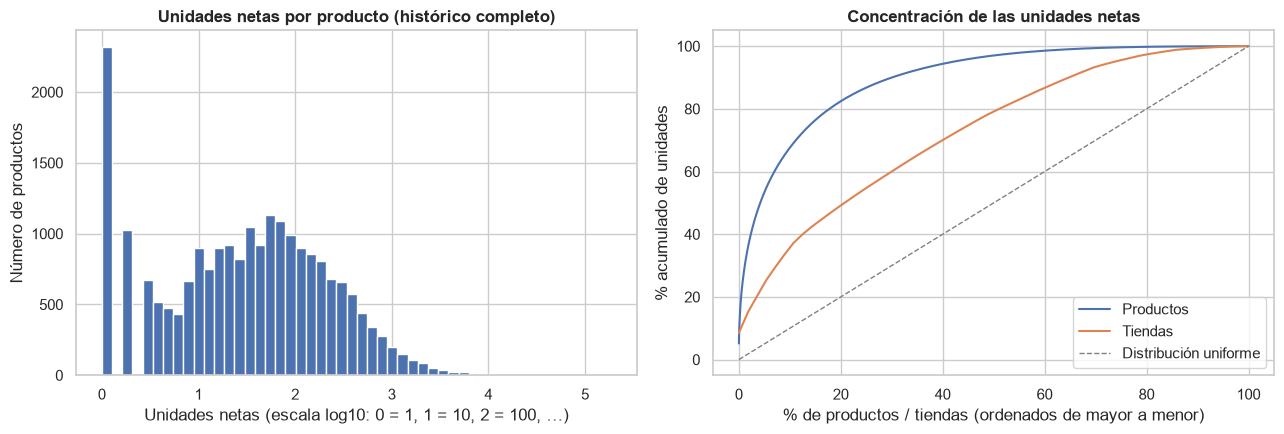

In [41]:
# Curvas de concentración (Lorenz) de unidades por producto y por tienda + distribución de unidades por producto
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5))

positivos = por_producto.loc[por_producto["unidades"] > 0, "unidades"]
ejes[0].hist(np.log10(positivos), bins=50, color="#4C72B0")
ejes[0].set_title("Unidades netas por producto (histórico completo)")
ejes[0].set_xlabel("Unidades netas (escala log10: 0 = 1, 1 = 10, 2 = 100, …)")
ejes[0].set_ylabel("Número de productos")

for serie, etiqueta in [(por_producto["unidades"].clip(lower=0), "Productos"), (por_tienda["unidades"], "Tiendas")]:
    s = np.sort(serie.to_numpy())[::-1]
    ejes[1].plot(np.linspace(0, 100, len(s)), 100 * np.cumsum(s) / s.sum(), label=etiqueta)
ejes[1].plot([0, 100], [0, 100], ls="--", c="grey", lw=1, label="Distribución uniforme")
ejes[1].set_title("Concentración de las unidades netas")
ejes[1].set_xlabel("% de productos / tiendas (ordenados de mayor a menor)")
ejes[1].set_ylabel("% acumulado de unidades")
ejes[1].legend()
plt.tight_layout()
plt.show()

**Interpretación.**

**Por producto (21,807 productos).**
- **Distribución:** muy desigual. El producto mediano vende 33 unidades netas en todo el histórico, la media es 167.29 y el máximo 187,642.
- **Concentración:** el 1 % de los productos genera el **28.15 % de las unidades** y el **44.83 % de los ingresos**; el 10 % genera el 67.58 % y el 83.83 %, respectivamente.
- **Cola larga:** 2,319 productos vendieron exactamente 1 unidad, 2,999 solo se vendieron en un mes y 8 tienen ventas netas ≤ 0.
- **Lectura del histograma:** el primer bloque corresponde a los productos de 1 unidad; el grueso se ubica entre 10 y 1,000 unidades.

**Por categoría (84 categorías).**
- **Concentración:** también es alta. Las 4 categorías principales (5 %) suman el 46.4 % de las unidades, y las 17 principales (20 %) el 81.3 %.
- **Por grupo de categoría:** las unidades y los ingresos **no coinciden**:
  - `Кино` (películas) aporta el 25.13 % de las unidades pero solo el 9.86 % de los ingresos;
  - `Игры` (juegos de consola) aporta el 17.73 % de las unidades y el 33.95 % de los ingresos;
  - `Игровые консоли` (consolas) aporta apenas el 0.88 % de las unidades pero el 15.54 % de los ingresos, con un precio medio de 16,421 por unidad.

**Por sucursal (57 tiendas, IDs unificados).**
- **Concentración:** menor que la de productos. Las 3 tiendas principales (5 %) suman el 20.2 % de las unidades y las 11 principales (20 %) el 46.7 %.
- **Promedio por mes activo:** va de 330 a 9,140 unidades, con una mediana de 1,879.
- **Actividad:** solo 35 de las 57 tiendas estuvieron activas los 34 meses.
- **Curvas de Lorenz:** la curva de productos sube mucho más rápido que la de tiendas, es decir, las ventas están mucho más concentradas en pocos productos que en pocas tiendas.

#### iii. Por periodo de tiempo (día, semana, mes, año)
- **Semanas:** van de lunes a domingo, y se excluyen la primera y la última si están incompletas.
- **Años:** 2015 solo tiene 10 meses, así que la comparación anual equivalente se hace con **enero–octubre** de cada año.

In [42]:
diario = ventas.groupby("date").agg(unidades=("item_cnt_day", "sum"), ingresos=("ingresos", "sum"))

semanal = diario.resample("W-SUN").agg(["sum", "count"])
semanal = semanal[semanal[("unidades", "count")] == 7]
semanal = pd.DataFrame({"unidades": semanal[("unidades", "sum")], "ingresos": semanal[("ingresos", "sum")]})

mensual = ventas.groupby("date_block_num").agg(
    mes=("date", lambda d: d.min().strftime("%Y-%m")),
    unidades=("item_cnt_day", "sum"),
    ingresos=("ingresos", "sum"),
    registros=("item_cnt_day", "size"),
    tiendas_activas=("shop_id", "nunique"),
    productos_activos=("item_id", "nunique"),
)

resumen_periodos = pd.DataFrame(
    {
        f"{nombre} (n={len(df)})": df[["unidades", "ingresos"]].agg(["mean", "median", "min", "max", "std"]).stack()
        for nombre, df in [("día", diario), ("semana", semanal), ("mes", mensual)]
    }
)
resumen_periodos.index = [f"{m} – {e}" for m, e in resumen_periodos.index]
resumen_periodos

,día (n=1034),semana (n=146),mes (n=34)
mean – unidades,"3,528.24","24,645.97","107,300.00"
mean – ingresos,"3,287,160.13","23,006,287.80","99,968,340.46"
median – unidades,"3,145.00","24,500.50","107,306.00"
median – ingresos,"2,664,234.47","19,281,257.97","90,459,260.56"
min – unidades,"1,274.00","12,389.00","63,187.00"
min – ingresos,"1,194,405.00","11,231,169.51","59,405,787.17"
max – unidades,"13,343.00","57,680.00","183,342.00"
max – ingresos,"36,544,808.00","70,269,551.12","232,024,671.81"
std – unidades,"1,584.68","7,801.24","28,455.95"
std – ingresos,"2,257,311.86","11,084,528.95","37,117,760.92"


In [43]:
mensual

,mes,unidades,ingresos,registros,tiendas_activas,productos_activos
date_block_num,,,,,,
0,2013-01,"131,478.00","91,946,942.13",115689,45,8115
1,2013-02,"128,090.00","90,665,707.37",108613,46,8168
2,2013-03,"147,142.00","104,932,687.15",121347,46,8302
3,2013-04,"107,190.00","69,154,285.55",94109,46,8145
4,2013-05,"106,970.00","65,067,187.46",91759,45,8339
5,2013-06,"125,381.00","79,550,405.83",100403,46,8478
6,2013-07,"116,966.00","69,350,599.88",100548,46,8405
7,2013-08,"125,291.00","74,297,969.64",104772,45,8031
8,2013-09,"133,332.00","119,081,891.68",96137,45,7876


In [44]:
anual = ventas.groupby("anio").agg(
    meses=("date_block_num", "nunique"), unidades=("item_cnt_day", "sum"), ingresos=("ingresos", "sum")
)
ene_oct = ventas[ventas["mes"] <= 10].groupby("anio").agg(unidades_ene_oct=("item_cnt_day", "sum"),
                                                          ingresos_ene_oct=("ingresos", "sum"))
anual = anual.join(ene_oct)
anual["var_%_unidades_ene_oct"] = anual["unidades_ene_oct"].pct_change() * 100
anual["var_%_ingresos_ene_oct"] = anual["ingresos_ene_oct"].pct_change() * 100
anual["ingreso_medio_por_unidad"] = anual["ingresos"] / anual["unidades"]
anual

,meses,unidades,ingresos,unidades_ene_oct,ingresos_ene_oct,var_%_unidades_ene_oct,var_%_ingresos_ene_oct,ingreso_medio_por_unidad
anio,,,,,,,,
2013,12,"1,562,732.00","1,217,526,459.98","1,249,381.00","871,289,289.22",NaN,NaN,779.10
2014,12,"1,320,884.00","1,346,773,983.81","1,034,285.00","962,711,712.66",-17.22,10.49,"1,019.60"
2015,10,"764,584.00","834,623,131.78","764,584.00","834,623,131.78",-26.08,-13.30,"1,091.60"


**Interpretación.**

**Escalas temporales (unidades netas).**
- **Día:** 3,528 en promedio (mediana 3,145), con un rango de 1,274 a 13,343.
- **Semana completa:** 24,646 en promedio, con un rango de 12,389 a 57,680.
- **Mes:** 107,300 en promedio, con un mínimo de 63,187 (julio 2015) y un máximo de 183,342 (diciembre 2013).

La variabilidad relativa es alta en todas las escalas, y los máximos coinciden con fin de año (sección 6).

**Tabla mensual.**
- **Productos activos:** caen de forma sostenida, de 7,876–8,478 al mes en 2013 a 5,085–5,476 entre abril y octubre de 2015.
- **Registros mensuales:** bajan de 91,759–121,347 en los meses de 2013 sin contar diciembre a 50,588–57,029 entre abril y octubre de 2015.
- **Tiendas activas:** se mantienen entre 42 y 52.

Es decir, la reducción del volumen no se explica por menos tiendas, sino por menos transacciones y menos productos vendidos por mes.

**Comparación anual (enero–octubre, para que 2015 sea comparable).**
- **Unidades:** caen un **17.22 %** de 2013 a 2014 y un **26.08 %** de 2014 a 2015.
- **Ingresos:** suben un **10.49 %** de 2013 a 2014 y caen un **13.30 %** de 2014 a 2015.
- **Ingreso medio por unidad:** sube de 779.10 (2013) a 1,019.60 (2014) y 1,091.60 (2015). Por eso los ingresos caen menos que las unidades.

Los datos no permiten determinar si ese aumento se debe a cambios de precio, a un cambio en la mezcla de productos o a ambos.

## 6. Exploración temporal

### 6a. Evolución de las ventas a lo largo del tiempo
Se grafica la serie **diaria** de unidades netas, con su media móvil de 28 días, y la serie **semanal** de unidades e ingresos. La serie mensual total corresponde a la visualización obligatoria 8a y se presenta en la sección 8, para no duplicarla.

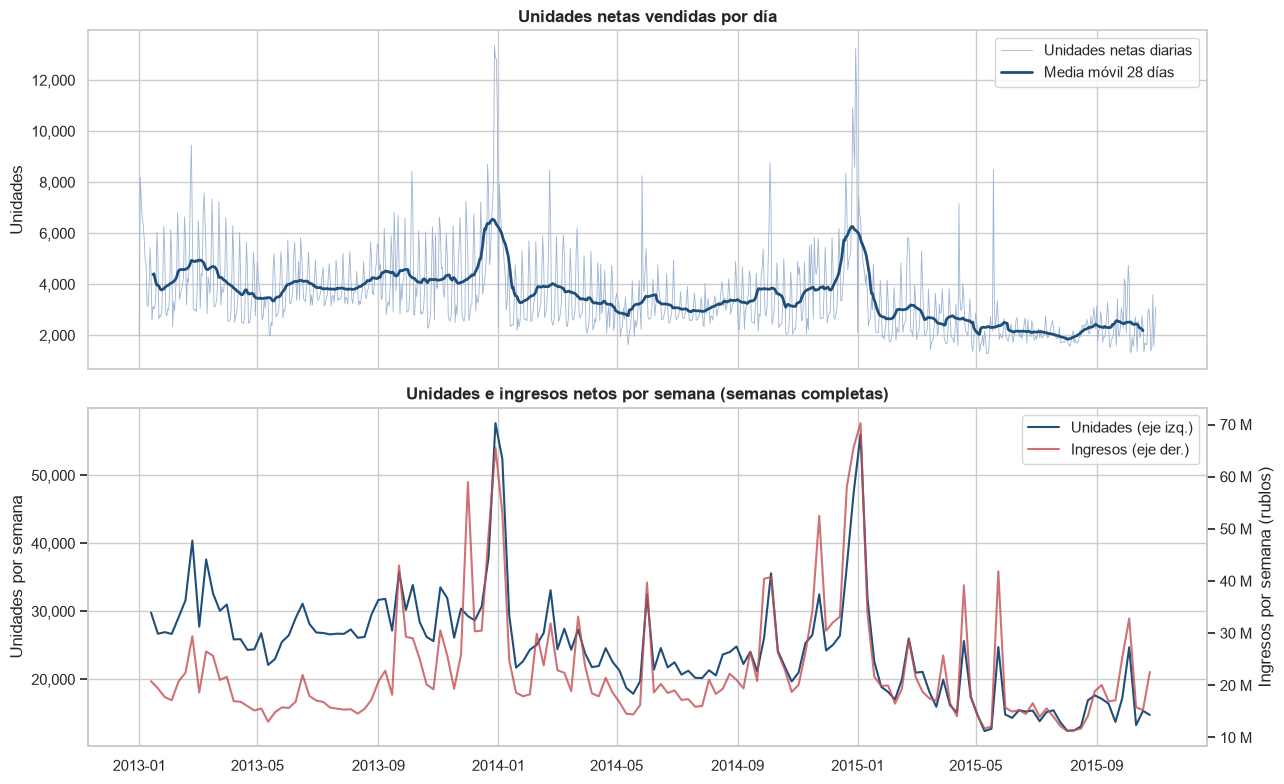

In [45]:
fig, ejes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)

ejes[0].plot(diario.index, diario["unidades"], lw=0.6, color="#9DB4D3", label="Unidades netas diarias")
ejes[0].plot(diario.index, diario["unidades"].rolling(28, center=True).mean(), lw=2, color="#1F4E79",
             label="Media móvil 28 días")
ejes[0].set_title("Unidades netas vendidas por día")
ejes[0].set_ylabel("Unidades")
ejes[0].yaxis.set_major_formatter(miles)
ejes[0].legend(loc="upper right")

ejes[1].plot(semanal.index, semanal["unidades"], color="#1F4E79", label="Unidades (eje izq.)")
ejes[1].set_ylabel("Unidades por semana")
ejes[1].yaxis.set_major_formatter(miles)
eje_ing = ejes[1].twinx()
eje_ing.plot(semanal.index, semanal["ingresos"], color="#C44E52", alpha=0.8, label="Ingresos (eje der.)")
eje_ing.set_ylabel("Ingresos por semana (rublos)")
eje_ing.yaxis.set_major_formatter(millones)
eje_ing.grid(False)
ejes[1].set_title("Unidades e ingresos netos por semana (semanas completas)")
lineas = ejes[1].get_legend_handles_labels()[0] + eje_ing.get_legend_handles_labels()[0]
ejes[1].legend(lineas, [l.get_label() for l in lineas], loc="upper right")
plt.tight_layout()
plt.show()

### 6b. Patrones temporales

#### i. Tendencia
Se usan tres evidencias:
1. Una **regresión lineal** de las unidades mensuales sobre el índice de mes (OLS).
2. La **comparación enero–octubre** entre años.
3. Una **descomposición clásica aditiva** (periodo 12) de la serie mensual. Con 34 meses solo hay dos ciclos anuales completos, así que la descomposición es descriptiva y no confirmatoria.

In [46]:
y_unid = mensual["unidades"].astype(float).to_numpy()
y_ing = mensual["ingresos"].astype(float).to_numpy()
X = sm.add_constant(np.arange(len(mensual)))

tendencia = []
for nombre, y in [("unidades", y_unid), ("ingresos", y_ing)]:
    modelo = sm.OLS(y, X).fit()
    tendencia.append(
        {
            "serie mensual": nombre,
            "pendiente_por_mes": modelo.params[1],
            "pendiente_%_de_la_media": 100 * modelo.params[1] / y.mean(),
            "p_valor": modelo.pvalues[1],
            "R2": modelo.rsquared,
        }
    )
pd.DataFrame(tendencia).set_index("serie mensual")

,pendiente_por_mes,pendiente_%_de_la_media,p_valor,R2
serie mensual,,,,
unidades,"-1,943.52",-1.81,0.00,0.46
ingresos,"-80,081.15",-0.08,0.90,0.00


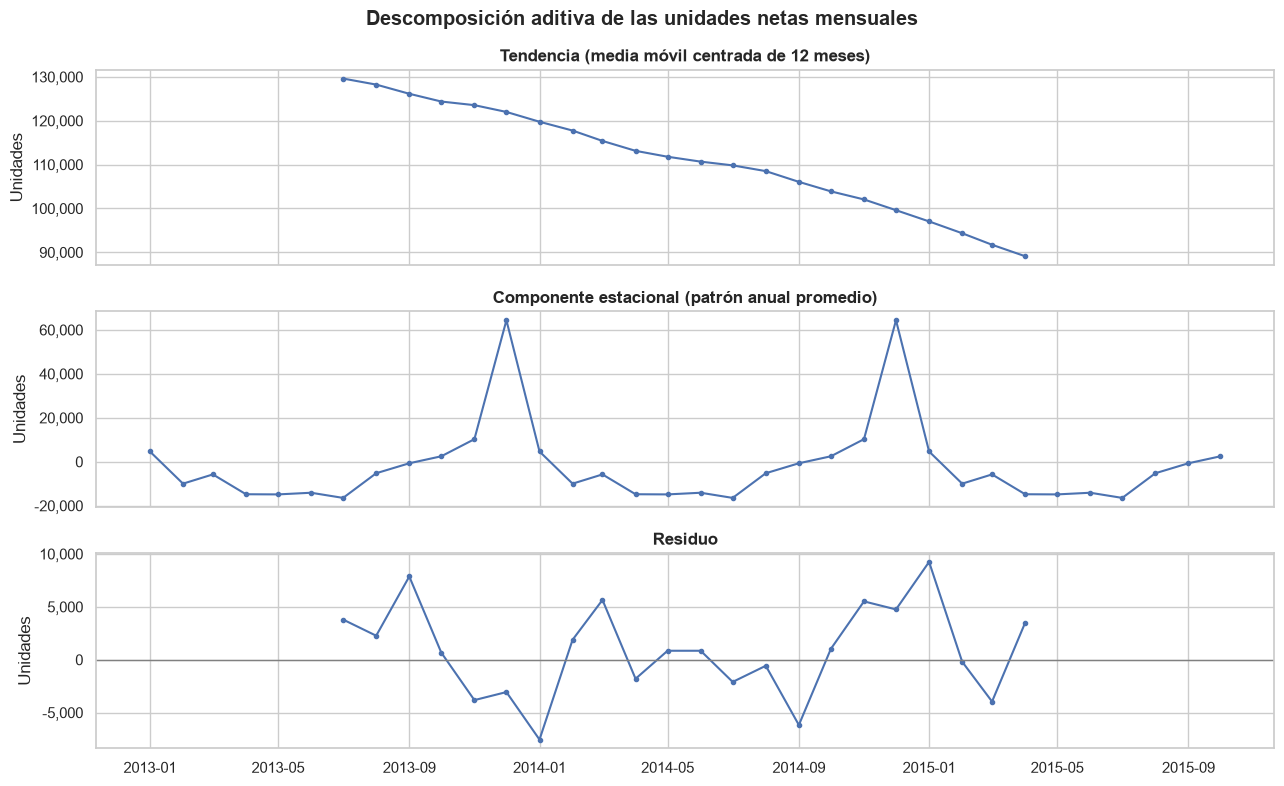

Tendencia: 2013-07 = 129,620 -> 2015-04 = 89,114 (-31.3%)
Residuo: mínimo -7,550 | máximo 9,247 unidades


In [47]:
serie_mensual = pd.Series(y_unid, index=pd.period_range("2013-01", periods=len(mensual), freq="M").to_timestamp())
descomp = seasonal_decompose(serie_mensual, model="additive", period=12)

fig, ejes = plt.subplots(3, 1, figsize=(13, 8), sharex=True)
for eje, (comp, titulo) in zip(
    ejes,
    [(descomp.trend, "Tendencia (media móvil centrada de 12 meses)"),
     (descomp.seasonal, "Componente estacional (patrón anual promedio)"),
     (descomp.resid, "Residuo")],
):
    eje.plot(comp.index, comp.values, marker="o", ms=3)
    eje.set_title(titulo)
    eje.set_ylabel("Unidades")
    eje.yaxis.set_major_formatter(miles)
ejes[2].axhline(0, c="grey", lw=1)
fig.suptitle("Descomposición aditiva de las unidades netas mensuales", fontweight="bold")
plt.tight_layout()
plt.show()

tend = descomp.trend.dropna()
print(f"Tendencia: {tend.index[0]:%Y-%m} = {tend.iloc[0]:,.0f} -> {tend.index[-1]:%Y-%m} = {tend.iloc[-1]:,.0f} "
      f"({100 * (tend.iloc[-1] / tend.iloc[0] - 1):.1f}%)")
print(f"Residuo: mínimo {descomp.resid.min():,.0f} | máximo {descomp.resid.max():,.0f} unidades")

**Interpretación.**
- **Unidades:** tendencia **decreciente y estadísticamente significativa**. La regresión estima −1,943.52 unidades por mes (−1.81 % de la media mensual), con p < 0.01 y R² = 0.46. La tendencia de la descomposición baja de 129,620 (jul-2013) a 89,114 (abr-2015), un **−31.3 %**, de forma casi monótona. La serie diaria (6a) muestra lo mismo: el promedio diario pasa de 4,281 unidades en 2013 (1,562,732 / 365) a 2,515 en 2015 (764,584 / 304 días).
- **Ingresos:** **no muestran una tendencia lineal significativa** (pendiente −80,081 por mes, p = 0.90, R² ≈ 0). Esto es coherente con el aumento del ingreso medio por unidad visto en 5b-iii.
- **Residuo de la descomposición:** sin patrón evidente (entre −7,550 y 9,247 unidades). Con solo 34 meses, la descomposición describe la serie pero no permite proyectarla con confianza.

#### ii. Estacionalidad
Se compara cada mes calendario entre años y se expresa cada mes como **índice respecto al promedio mensual de su año** (100 = mes promedio). Así se separa el patrón estacional del nivel de cada año.

In [48]:
pivote = ventas.groupby(["anio", "mes"])["item_cnt_day"].sum().unstack("anio")
pivote.index = MESES_ES
indice_estacional = pivote / pivote.mean() * 100
display(pivote.style.format("{:,.0f}", na_rep="—").set_caption("Unidades netas por mes calendario y año"))
display(indice_estacional.round(1).style.format("{:.1f}", na_rep="—")
        .set_caption("Índice estacional (100 = promedio mensual del año)"))

comp_estacional = descomp.seasonal.groupby(descomp.seasonal.index.month).first()
comp_estacional.index = MESES_ES
print("Componente estacional de la descomposición (unidades sobre/bajo la tendencia):")
print(comp_estacional.round(0).astype(int).to_string())

anio,2013,2014,2015
Ene,"131,478","116,899","110,971"
Feb,"128,090","109,686","84,198"
Mar,"147,142","115,296","82,014"
Abr,"107,190","96,556","77,827"
May,"106,970","97,789","72,295"
Jun,"125,381","97,429","64,114"
Jul,"116,966","91,279","63,187"
Ago,"125,291","102,721","66,079"
Sep,"133,332","99,208","72,843"
Oct,"127,541","107,422","71,056"


anio,2013,2014,2015
Ene,101.0,106.2,145.1
Feb,98.4,99.6,110.1
Mar,113.0,104.7,107.3
Abr,82.3,87.7,101.8
May,82.1,88.8,94.6
Jun,96.3,88.5,83.9
Jul,89.8,82.9,82.6
Ago,96.2,93.3,86.4
Sep,102.4,90.1,95.3
Oct,97.9,97.6,92.9


Componente estacional de la descomposición (unidades sobre/bajo la tendencia):
Ene     4674
Feb    -9965
Mar    -5758
Abr   -14785
May   -14856
Jun   -14101
Jul   -16449
Ago    -5224
Sep     -689
Oct     2491
Nov    10271
Dic    64390


**Interpretación.** La estacionalidad anual es clara y se repite en los dos años completos:
- **Diciembre es el pico del año:** su índice es 140.8 en 2013 y 153.3 en 2014, y el componente estacional suma unas +64,390 unidades sobre la tendencia.
- **Noviembre ya está por encima de la tendencia** (+10,271 en el componente estacional).
- **La parte baja del año va de abril a julio:** el componente estacional está entre −14,101 y −16,449, y los índices entre 82 y 96 en 2013 y 2014.

**Precaución con 2015:** su índice no es comparable. Solo incluye enero–octubre y está dominado por la tendencia descendente (enero 145.1 frente a julio 82.6), así que la lectura estacional se apoya en 2013 y 2014.

**Relevancia para el forecasting:** el mes a predecir, noviembre de 2015, está en la fase de subida estacional previa a diciembre. Sin embargo, solo hay **dos noviembres** observados (130,009 y 117,845 unidades), así que la magnitud estacional se estima con muy pocos ciclos.

#### iii. Picos o caídas abruptas
**Criterio explícito (diario).** Se compara cada día con la **mediana móvil centrada de 29 días** (±14 días). Se marca:
- un **pico** si las unidades del día superan **2 veces** esa mediana;
- una **caída** si quedan por debajo de **0.5 veces**.

**Nivel mensual.** Se revisan las mayores variaciones porcentuales mes contra mes.

In [49]:
mediana_local = diario["unidades"].rolling(29, center=True, min_periods=15).median()
ratio = diario["unidades"] / mediana_local
eventos = (
    pd.DataFrame({"unidades": diario["unidades"], "mediana_local_29d": mediana_local, "ratio": ratio})
    .assign(dia_semana=lambda d: d.index.day_of_week.map(dict(enumerate(DIAS_ES))))
)
picos = eventos[eventos["ratio"] > 2].sort_values("ratio", ascending=False)
caidas = eventos[eventos["ratio"] < 0.5].sort_values("ratio")
print(f"Días con pico (> 2x mediana local): {len(picos)} | días con caída (< 0.5x): {len(caidas)}")
display(picos.head(15).style.format({"unidades": "{:,.0f}", "mediana_local_29d": "{:,.0f}", "ratio": "{:.2f}"})
        .set_caption("Picos diarios"))
display(caidas.style.format({"unidades": "{:,.0f}", "mediana_local_29d": "{:,.0f}", "ratio": "{:.2f}"})
        .set_caption("Caídas diarias"))

Días con pico (> 2x mediana local): 21 | días con caída (< 0.5x): 3


,unidades,mediana_local_29d,ratio,dia_semana
date,,,,
2015-05-19 00:00:00,"8,483","1,997",4.25,Martes
2015-04-14 00:00:00,"7,158","2,299",3.11,Martes
2014-05-27 00:00:00,"8,256","3,010",2.74,Martes
2014-12-30 00:00:00,"13,236","5,070",2.61,Martes
2014-02-22 00:00:00,"8,472","3,263",2.60,Sábado
2014-10-04 00:00:00,"8,767","3,583",2.45,Sábado
2013-12-30 00:00:00,"12,823","5,301",2.42,Lunes
2013-12-29 00:00:00,"12,863","5,368",2.40,Domingo
2013-12-28 00:00:00,"13,343","5,806",2.30,Sábado


,unidades,mediana_local_29d,ratio,dia_semana
date,,,,
2013-01-01 00:00:00,"1,951","4,772",0.41,Martes
2015-01-01 00:00:00,"2,117","5,070",0.42,Jueves
2014-01-01 00:00:00,"2,310","5,301",0.44,Miércoles


In [50]:
# Composición de los 12 picos principales: ¿se explican por una tienda o un producto concreto?
def composicion_dia(fecha: pd.Timestamp) -> dict:
    d = ventas[ventas["date"] == fecha]
    total = d["item_cnt_day"].sum()
    por_t = d.groupby("shop_id")["item_cnt_day"].sum()
    por_p = d.groupby("item_id")["item_cnt_day"].sum()
    return {
        "fecha": fecha.date(),
        "dia_semana": DIAS_ES[fecha.day_of_week],
        "unidades": total,
        "ratio": eventos.loc[fecha, "ratio"],
        "tiendas_con_venta": d["shop_id"].nunique(),
        "tienda_principal": por_t.idxmax(),
        "%_tienda_principal": 100 * por_t.max() / total,
        "producto_principal": recortar(items.set_index("item_id").loc[por_p.idxmax(), "item_name"], 40),
        "%_producto_principal": 100 * por_p.max() / total,
    }


pd.DataFrame([composicion_dia(f) for f in picos.head(12).index]).style.format(
    {"unidades": "{:,.0f}", "ratio": "{:.2f}", "%_tienda_principal": "{:.1f}%", "%_producto_principal": "{:.1f}%"}
).set_caption("Composición de los 12 picos diarios con mayor ratio")

,fecha,dia_semana,unidades,ratio,tiendas_con_venta,tienda_principal,%_tienda_principal,producto_principal,%_producto_principal
0,2015-05-19,Martes,"8,483",4.25,44,12,26.3%,"Ведьмак 3: Дикая охота [PC, русская вер…",23.6%
1,2015-04-14,Martes,"7,158",3.11,44,12,11.4%,"Grand Theft Auto V [PC, русские субтитр…",53.4%
2,2014-05-27,Martes,"8,256",2.74,49,12,11.2%,"Watch_Dogs. Специальное издание [PS4, р…",17.3%
3,2014-12-30,Martes,"13,236",2.61,50,25,14.9%,Фирменный пакет майка 1С Интерес белый …,8.1%
4,2014-02-22,Sábado,"8,472",2.60,46,31,7.9%,Фирменный пакет майка 1С Интерес белый …,6.0%
5,2014-10-04,Sábado,"8,767",2.45,51,9,23.6%,"Средиземье: Тени Мордора [PC, Цифровая …",4.6%
6,2013-12-30,Lunes,"12,823",2.42,46,31,8.1%,Фирменный пакет майка 1С Интерес белый …,8.5%
7,2013-12-29,Domingo,"12,863",2.40,45,31,7.5%,Фирменный пакет майка 1С Интерес белый …,6.6%
8,2013-12-28,Sábado,"13,343",2.30,45,31,7.7%,Фирменный пакет майка 1С Интерес белый …,8.4%
9,2015-02-21,Sábado,"5,843",2.25,45,31,6.5%,Фирменный пакет майка 1С Интерес белый …,4.4%


In [51]:
var_mensual = mensual[["mes", "unidades", "ingresos"]].copy()
var_mensual["var_%_unidades"] = var_mensual["unidades"].pct_change() * 100
var_mensual["var_%_ingresos"] = var_mensual["ingresos"].pct_change() * 100
print("Mayores aumentos y caídas mes contra mes (unidades):")
pd.concat([var_mensual.nlargest(4, "var_%_unidades"), var_mensual.nsmallest(4, "var_%_unidades")])

Mayores aumentos y caídas mes contra mes (unidades):


,mes,unidades,ingresos,var_%_unidades,var_%_ingresos
date_block_num,,,,,
23,2014-12,"168,754.00","232,024,671.81",43.20,52.61
11,2013-12,"183,342.00","207,571,731.46",41.02,49.69
5,2013-06,"125,381.00","79,550,405.83",17.21,22.26
2,2013-03,"147,142.00","104,932,687.15",14.87,15.74
12,2014-01,"116,899.00","98,226,022.95",-36.24,-52.68
24,2015-01,"110,971.00","118,927,699.78",-34.24,-48.74
3,2013-04,"107,190.00","69,154,285.55",-27.15,-34.10
25,2015-02,"84,198.00","86,593,883.89",-24.13,-27.19


**Interpretación.**

**Caídas.** Con el criterio de 0.5 veces la mediana local hay solo **3 caídas**, y las tres son el **1 de enero** de cada año (de 1,951 a 2,310 unidades, entre 0.41 y 0.44 veces su mediana local).

**Picos.** Hay **21 días** que superan 2 veces la mediana local. Su composición muestra tres tipos distintos:
1. **Fin de año (28 al 31 de diciembre de 2013 y 2014):** entre 11,393 y 13,343 unidades por día, distribuidas en 45–50 tiendas. Ninguna tienda supera el 15 % del día y el producto principal (la bolsa `Фирменный пакет майка`) no pasa del 8.5 %. Es un pico **amplio**, de toda la cadena.
2. **Picos concentrados en un solo título y en la tienda online (shop 12):**
   - 14.04.2015: `Grand Theft Auto V [PC]` explica el **53.4 %** de las unidades del día (ratio 3.11).
   - 19.05.2015: `Ведьмак 3 [PC]` explica el 23.6 %, y la shop 12 el 26.3 %. Es el pico de mayor ratio (4.25).
   - 27.05.2014: `Watch_Dogs [PS4]` explica el 17.3 %.

   Este patrón es coherente con días de lanzamiento de juegos, pero el dataset no incluye fechas de lanzamiento para confirmarlo.
3. **Picos de una tienda concreta:** el 04.10.2014 la tienda itinerante (shop 9) aportó el 23.6 % del día.
4. **Fines de semana de finales de febrero:** 23.02.2013, 22.02.2014 y 21–22.02.2015. Son picos amplios: en los que aparecen en la tabla de composición, la tienda principal aporta entre el 6.2 % y el 7.9 % y el producto principal no supera el 6 %.

**Nivel mensual.**
- **Mayores aumentos:** diciembre (+43.20 % en 2014 y +41.02 % en 2013).
- **Mayores caídas:** enero (−36.24 % en 2014 y −34.24 % en 2015), además de abril de 2013 (−27.15 %) y febrero de 2015 (−24.13 %).

#### iv. Ciclos por día de la semana y por mes del año
- **Día de la semana:** promedio de unidades netas diarias de cada día, expresado también como índice (100 = día promedio).
- **Mes del año:** perfil de unidades netas mensuales de cada año, superpuesto.

,dias,unidades_promedio,ingresos_promedio,indice_unidades
Lunes,147,"2,731","2,492,524",77.4
Martes,148,"3,074","3,174,811",87.1
Miércoles,148,"2,971","2,865,514",84.2
Jueves,148,"3,072","2,892,309",87.1
Viernes,148,"3,740","3,722,738",106.0
Sábado,148,"4,964","4,349,099",140.7
Domingo,147,"4,145","3,509,257",117.5


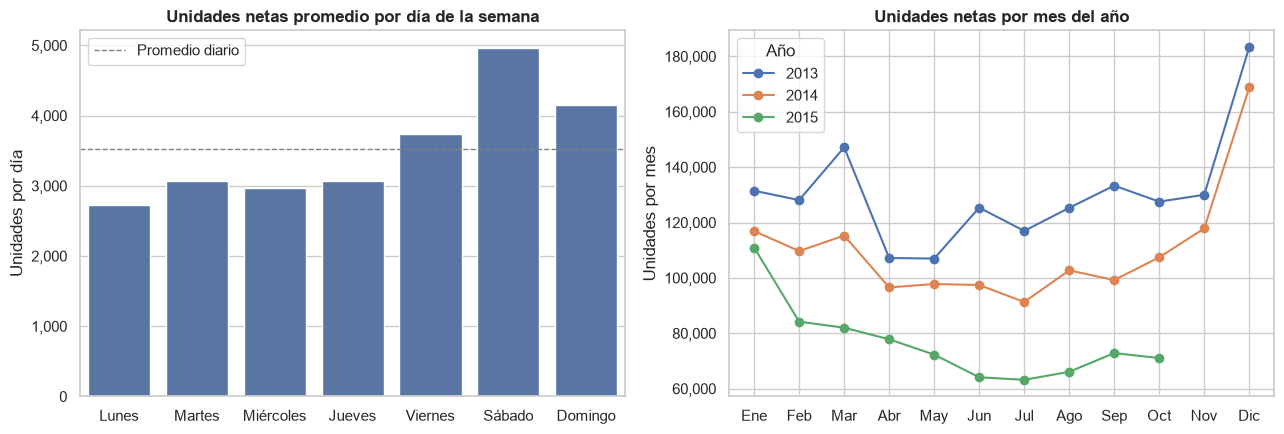

In [52]:
por_dia_semana = diario.assign(dia=diario.index.day_of_week).groupby("dia").agg(
    dias=("unidades", "size"), unidades_promedio=("unidades", "mean"), ingresos_promedio=("ingresos", "mean")
)
por_dia_semana.index = DIAS_ES
por_dia_semana["indice_unidades"] = 100 * por_dia_semana["unidades_promedio"] / diario["unidades"].mean()
display(por_dia_semana.style.format({"unidades_promedio": "{:,.0f}", "ingresos_promedio": "{:,.0f}",
                                     "indice_unidades": "{:.1f}"}))

fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.barplot(x=por_dia_semana.index, y=por_dia_semana["unidades_promedio"], ax=ejes[0], color="#4C72B0")
ejes[0].axhline(diario["unidades"].mean(), ls="--", c="grey", lw=1, label="Promedio diario")
ejes[0].set_title("Unidades netas promedio por día de la semana")
ejes[0].set_xlabel("")
ejes[0].set_ylabel("Unidades por día")
ejes[0].yaxis.set_major_formatter(miles)
ejes[0].legend()

for anio in pivote.columns:
    ejes[1].plot(MESES_ES, pivote[anio], marker="o", label=str(anio))
ejes[1].set_title("Unidades netas por mes del año")
ejes[1].set_ylabel("Unidades por mes")
ejes[1].yaxis.set_major_formatter(miles)
ejes[1].legend(title="Año")
plt.tight_layout()
plt.show()

**Interpretación.**

**Ciclo semanal.** Es marcado y consistente:
- **Sábado** es el día de más ventas: 4,964 unidades en promedio, índice 140.7.
- Le siguen **domingo** (4,145; 117.5) y **viernes** (3,740; 106.0).
- **Lunes** es el más bajo (2,731; 77.4), y de martes a jueves se mantienen entre 2,971 y 3,074 (índices 84–87).
- Cada día de la semana tiene 147–148 observaciones, así que la comparación está balanceada.

El fin de semana concentra la demanda. Para el forecasting mensual, el número de fines de semana de cada mes puede influir en el total.

**Ciclo por mes del año.**
- Los perfiles de 2013 y 2014 tienen la misma forma: subida en noviembre y pico en diciembre.
- El perfil de 2015 está sistemáticamente por debajo de los anteriores y desciende hasta julio (63,187), con una leve recuperación en agosto y septiembre.
- Los tres años muestran un mínimo a mediados de año.

#### Patrones observados vs. conclusiones no demostrables con el histórico

| Patrones respaldados por los datos | Lo que **no** puede demostrarse con este histórico |
|---|---|
| Tendencia decreciente en unidades (−31.3 % en la tendencia; −17.22 % y −26.08 % interanual en enero–octubre). | **Por qué** caen las ventas (cambio a canales digitales, contexto económico, competencia…). El dataset no tiene variables explicativas externas. |
| Ingresos sin tendencia lineal significativa y aumento del ingreso medio por unidad. | Si el aumento se debe a inflación, a cambios de precio o a cambios en la mezcla de productos. Los ingresos están en rublos nominales. |
| Pico en diciembre y caída en enero en ambos años completos; noviembre por encima de la tendencia. | La magnitud exacta del efecto de noviembre de 2015: solo hay 2 noviembres observados. |
| Ciclo semanal con máximo en sábado. | — |
| Picos diarios concentrados en un solo título y en la tienda online. | Que correspondan a lanzamientos o promociones: no hay fechas de lanzamiento ni calendario de campañas. |
| Caída del número de productos activos por mes. | Si se debe a una reducción del surtido, a la rotación del catálogo o a menor demanda. |

## 7. Análisis comparativo entre sucursales y productos

### 7a. Productos y categorías más y menos vendidos
El ranking se hace por **unidades netas** sobre todo el histórico, con los ingresos como referencia. Las gráficas de barras del top N y por categoría son las visualizaciones obligatorias 8c, así que aquí se presentan como tablas.

In [53]:
ranking_productos = por_producto.join(items.set_index("item_id")[["item_name", "item_category_id"]]).join(
    item_categories.set_index("item_category_id")["item_category_name"], on="item_category_id"
)
ranking_productos["%_unidades"] = 100 * ranking_productos["unidades"] / ranking_productos["unidades"].sum()
ranking_productos["rank_ingresos"] = ranking_productos["ingresos"].rank(ascending=False, method="min").astype(int)
cols_rank = ["item_name", "item_category_name", "unidades", "%_unidades", "ingresos", "rank_ingresos", "tiendas", "meses"]

top20 = ranking_productos.sort_values("unidades", ascending=False).head(20)[cols_rank]
print(f"Los 20 productos más vendidos suman {top20['%_unidades'].sum():.1f}% de las unidades netas")
top20.style.format({"unidades": "{:,.0f}", "%_unidades": "{:.2f}%", "ingresos": "{:,.0f}"}).set_caption(
    "Top 20 productos por unidades netas"
)

Los 20 productos más vendidos suman 10.4% de las unidades netas


,item_name,item_category_name,unidades,%_unidades,ingresos,rank_ingresos,tiendas,meses
item_id,,,,,,,,
20949,Фирменный пакет майка 1С Интерес белый (34*42) 45 мкм,"Подарки - Сумки, Альбомы, Коврики д/мыши","187,642",5.14%,"928,864",646,52,31
2808,"Diablo III [PC, Jewel, русская версия]",Игры PC - Стандартные издания,"17,245",0.47%,"16,852,778",12,55,34
3732,"Grand Theft Auto V [PS3, русские субтитры]",Игры - PS3,"16,642",0.46%,"43,617,975",2,52,26
17717,Прием денежных средств для 1С-Онлайн,Служебные,"15,830",0.43%,"17,200,826",9,51,34
5822,Playstation Store пополнение бумажника: Карта оплаты 1000 руб.,Карты оплаты - PSN,"14,515",0.40%,"15,408,983",14,55,34
3734,"Grand Theft Auto V [Xbox 360, русские субтитры]",Игры - XBOX 360,"11,688",0.32%,"31,065,160",4,51,26
6675,Sony PlayStation 4 (500 Gb) Black (CUH-1008A/1108A/B01),Игровые консоли - PS4,"10,289",0.28%,"219,391,489",1,51,24
3731,"Grand Theft Auto V [PC, русские субтитры]",Игры PC - Стандартные издания,"10,099",0.28%,"19,983,483",7,43,7
1855,"Battlefield 4 [PC, русская версия]",Игры PC - Стандартные издания,"10,032",0.27%,"9,357,025",31,51,24


In [54]:
# Menos vendidos: hay miles de productos empatados con 1 unidad, por eso se resumen por nivel de ventas
niveles = pd.cut(
    ranking_productos["unidades"], bins=[-np.inf, -0.5, 0.5, 1.5, 5.5, 10.5, np.inf],
    labels=["< 0 (más devoluciones que ventas)", "0 (ventas = devoluciones)", "1", "2–5", "6–10", "> 10"],
)
display(niveles.value_counts().sort_index().rename("productos").to_frame()
        .assign(**{"%": lambda d: 100 * d["productos"] / d["productos"].sum()}))

bottom20 = ranking_productos.sort_values(["unidades", "ingresos"]).head(20)[cols_rank]
bottom20.style.format({"unidades": "{:,.0f}", "%_unidades": "{:.4f}%", "ingresos": "{:,.0f}"}).set_caption(
    "20 productos con menores unidades netas (desempate por ingresos)"
)

,productos,%
unidades,,
< 0 (más devoluciones que ventas),4,0.02
0 (ventas = devoluciones),4,0.02
1,2319,10.63
2–5,2688,12.33
6–10,1694,7.77
> 10,15098,69.23


,item_name,item_category_name,unidades,%_unidades,ingresos,rank_ingresos,tiendas,meses
item_id,,,,,,,,
1590,"Assassin’s Creed 3. Freedom Edition [PC, русская версия]",Игры PC - Коллекционные издания,-11,-0.0003%,"-28,589",21807,2,4
13474,Комплект «Sony PS3 (320 Gb) (CECH-2508B) + игра «FIFA 12»,Игровые консоли - PS3,-1,-0.0000%,"-10,398",21806,1,1
11871,Змея,"Подарки - Гаджеты, роботы, спорт",-1,-0.0000%,"-5,999",21804,1,1
18062,Робопет Собака,"Подарки - Гаджеты, роботы, спорт",-1,-0.0000%,"-4,999",21803,1,1
13477,Комплект «Sony PS3 (320 Gb) (CECH-3008B)» + игра «Чародей» + «PS Move Starter Pack»,Игровые консоли - PS3,0,0.0000%,"-7,592",21805,2,2
4591,"MCCARTNEY, PAUL In Red Square (Фирм.)",Музыка - Музыкальное видео,0,0.0000%,0,21801,1,1
7547,VideoStudio Pro X6 IE Windows Mini-Box,Программы - Для дома и офиса,0,0.0000%,0,21801,1,1
8515,Английский язык. 2 - 5 класс (Jewel),Программы - Обучающие,0,0.0000%,15,21798,2,1
22098,Элемент питания КОСМОС LR03 2*BL,Элементы питания,1,0.0000%,7,21800,1,1


In [55]:
ranking_categorias = por_categoria.reset_index().set_index("item_category_id").sort_values("unidades", ascending=False)
ranking_categorias["rank_ingresos"] = ranking_categorias["ingresos"].rank(ascending=False, method="min").astype(int)
cols_cat = ["item_category_name", "unidades", "%_unidades", "ingresos", "%_ingresos", "rank_ingresos", "productos"]
fmt_cat = {"unidades": "{:,.0f}", "%_unidades": "{:.2f}%", "ingresos": "{:,.0f}", "%_ingresos": "{:.2f}%"}
display(ranking_categorias.head(10)[cols_cat].style.format(fmt_cat).set_caption("10 categorías más vendidas (unidades)"))
display(ranking_categorias.tail(10)[cols_cat].style.format(fmt_cat).set_caption("10 categorías menos vendidas (unidades)"))

,item_category_name,unidades,%_unidades,ingresos,%_ingresos,rank_ingresos,productos
item_category_id,,,,,,,
40,Кино - DVD,"634,170",17.38%,"169,944,073",5.00%,6,4964
30,Игры PC - Стандартные издания,"456,540",12.51%,"257,519,291",7.58%,5,751
55,Музыка - CD локального производства,"348,591",9.56%,"100,022,564",2.94%,8,2327
19,Игры - PS3,"254,887",6.99%,"412,052,156",12.12%,1,625
37,Кино - Blu-Ray,"203,283",5.57%,"90,478,233",2.66%,9,1777
71,"Подарки - Сумки, Альбомы, Коврики д/мыши","187,998",5.15%,"934,207",0.03%,61,6
28,Игры PC - Дополнительные издания,"174,954",4.80%,"136,419,149",4.01%,7,235
23,Игры - XBOX 360,"169,940",4.66%,"259,615,132",7.64%,4,496
20,Игры - PS4,"127,319",3.49%,"373,010,312",10.97%,2,157


,item_category_name,unidades,%_unidades,ingresos,%_ingresos,rank_ingresos,productos
item_category_id,,,,,,,
18,Игры - PS2,11,0.00%,"3,828",0.00%,76,6
27,Игры MAC - Цифра,8,0.00%,"5,422",0.00%,74,7
48,Книги - Компьютерная литература,6,0.00%,"1,654",0.00%,78,5
52,Книги - Путеводители,3,0.00%,300,0.00%,81,3
0,PC - Гарнитуры/Наушники,3,0.00%,263,0.00%,82,3
50,Книги - Открытки,3,0.00%,58,0.00%,84,2
53,Книги - Художественная литература,3,0.00%,847,0.00%,79,3
1,Аксессуары - PS2,2,0.00%,431,0.00%,80,2
10,Игровые консоли - PS2,1,0.00%,"1,998",0.00%,77,1


**Interpretación.**

**Productos más vendidos.** Los 20 primeros suman el **10.4 %** de las unidades netas, y el ranking por unidades mezcla mercancía con artículos que no son producto de venta:
- **#1, `Фирменный пакет майка 1С Интерес` (bolsa con la marca de la tienda):** 187,642 unidades, el **5.14 % del total**. Se vende en 52 tiendas durante 31 meses, pero ocupa el puesto 646 en ingresos.
- **Servicios y logística:** `Прием денежных средств для 1С-Онлайн` (recepción de pagos de 1C-Online, categoría `Служебные`, 15,830 unidades) y `Доставка до пункта выдачи (Boxberry)` (envío; 6,563 unidades, solo en la shop 12).
- **Mercancía:** el resto son sobre todo videojuegos (por ejemplo, `Diablo III [PC]` con 17,245 y `Grand Theft Auto V [PS3]` con 16,642, este último segundo en ingresos), tarjetas de pago (PSN 1000 rublos) y la consola `PlayStation 4`. La PS4 vende 10,289 unidades pero es el **número 1 en ingresos** (219.4 millones).

**Productos menos vendidos.**
- 4 productos tienen ventas netas negativas y 4 netas cero. El caso extremo es `Assassin's Creed 3. Freedom Edition [PC]`, con −11 unidades: más devoluciones que ventas dentro del periodo, posiblemente de compras anteriores a enero de 2013 (no verificable).
- **2,319 productos (10.63 %) vendieron una sola unidad** en todo el histórico, mientras que el 69.23 % superó las 10 unidades.

**Categorías más vendidas.**
- `Кино - DVD` (634,170 unidades, 17.38 %), `Игры PC - Стандартные издания` (12.51 %) y `Музыка - CD локального производства` (9.56 %).
- En ingresos las primeras son `Игры - PS3` (12.12 %) y `Игры - PS4` (10.97 %). En unidades la PS4 solo aporta el 3.49 %.
- La categoría 71 (bolsas, álbumes, alfombrillas) aporta el 5.15 % de las unidades pero solo el 0.03 % de los ingresos: casi todo su volumen es la bolsa de la tienda.

**Categorías menos vendidas.** Son categorías marginales con 1 a 11 unidades en todo el periodo: productos de PS2 (`Игры - PS2`, `Аксессуары - PS2`, `Игровые консоли - PS2`), algunas de libros (`Книги - …`) y auriculares para PC (`PC - Гарнитуры/Наушники`).

### 7b. Comparación del desempeño entre sucursales
Indicadores por tienda:
- unidades e ingresos totales;
- meses activos;
- **unidades por mes activo** (para comparar tiendas con distinta antigüedad);
- ingreso medio por unidad;
- variabilidad mensual (coeficiente de variación);
- presencia en `test.csv`.

In [56]:
mensual_por_tienda = ventas.groupby(["shop_id", "date_block_num"])["item_cnt_day"].sum()
cv = mensual_por_tienda.groupby("shop_id").agg(lambda s: s.std() / s.mean() if len(s) > 1 else np.nan)

desempeno = por_tienda.assign(
    ingreso_por_unidad=por_tienda["ingresos"] / por_tienda["unidades"],
    cv_mensual=cv,
    primer_mes=mensual_por_tienda.reset_index().groupby("shop_id")["date_block_num"].min(),
    ultimo_mes=mensual_por_tienda.reset_index().groupby("shop_id")["date_block_num"].max(),
    en_test=por_tienda.index.isin(test["shop_id"]),
).sort_values("unidades_por_mes", ascending=False)
desempeno["rank_unidades_por_mes"] = range(1, len(desempeno) + 1)

cols_t = ["nombre", "unidades", "%_unidades", "ingresos", "meses_activos", "primer_mes", "ultimo_mes",
          "unidades_por_mes", "ingreso_por_unidad", "cv_mensual", "en_test"]
fmt_t = {"unidades": "{:,.0f}", "%_unidades": "{:.2f}%", "ingresos": "{:,.0f}", "unidades_por_mes": "{:,.0f}",
         "ingreso_por_unidad": "{:,.0f}", "cv_mensual": "{:.2f}"}
display(desempeno.head(10)[cols_t].style.format(fmt_t).set_caption("10 tiendas con más unidades por mes activo"))
display(desempeno.tail(10)[cols_t].style.format(fmt_t).set_caption("10 tiendas con menos unidades por mes activo"))
print(f"Tiendas activas en el último mes (33): {(desempeno['ultimo_mes'] == 33).sum()} | "
      f"tiendas que dejaron de vender antes: {(desempeno['ultimo_mes'] < 33).sum()} | "
      f"tiendas de test sin ventas en el mes 33: {((desempeno['ultimo_mes'] < 33) & desempeno['en_test']).sum()}")
print(f"Relación entre la tienda con más y menos unidades por mes: "
      f"{desempeno['unidades_por_mes'].max() / desempeno['unidades_por_mes'].min():,.0f} veces")
print(f"Correlación de Spearman entre unidades por mes e ingreso por unidad: "
      f"{desempeno[['unidades_por_mes', 'ingreso_por_unidad']].corr(method='spearman').iloc[0, 1]:.2f}")

,nombre,unidades,%_unidades,ingresos,meses_activos,primer_mes,ultimo_mes,unidades_por_mes,ingreso_por_unidad,cv_mensual,en_test
shop_id,,,,,,,,,,,
31,"Москва ТЦ ""Семеновский""","310,777",8.52%,"235,217,019",34,0,33,"9,140",757,0.26,True
25,"Москва ТРК ""Атриум""","241,919",6.63%,"216,479,572",34,0,33,"7,115",895,0.25,True
54,"Химки ТЦ ""Мега""","185,789",5.09%,"141,939,524",28,0,27,"6,635",764,0.28,False
28,"Москва ТЦ ""МЕГА Теплый Стан"" II","184,557",5.06%,"159,746,337",34,0,33,"5,428",866,0.26,True
57,"Якутск Орджоникидзе, 56","152,812",4.19%,"119,637,154",34,0,33,"4,494",783,0.35,True
27,"Москва ТЦ ""МЕГА Белая Дача II""","136,657",3.75%,"140,632,474",32,0,32,"4,271","1,029",0.37,False
42,"СПб ТК ""Невский Центр""","144,933",3.97%,"151,916,534",34,0,33,"4,263","1,048",0.20,True
9,Выездная Торговля,"15,866",0.43%,"16,372,837",4,9,33,"3,966","1,032",0.77,False
6,"Воронеж (Плехановская, 13)","100,489",2.75%,"98,067,454",34,0,33,"2,956",976,0.32,True


,nombre,unidades,%_unidades,ingresos,meses_activos,primer_mes,ultimo_mes,unidades_por_mes,ingreso_por_unidad,cv_mensual,en_test
shop_id,,,,,,,,,,,
2,"Адыгея ТЦ ""Мега""","30,620",0.84%,"44,049,639",34,0,33,901,"1,439",0.27,True
8,"Воронеж ТРЦ Сити-Парк ""Град""","3,595",0.10%,"2,349,358",4,0,3,899,654,0.70,False
3,"Балашиха ТРК ""Октябрь-Киномир""","28,355",0.78%,"30,140,854",34,0,33,834,"1,063",0.20,True
39,"РостовНаДону ТРК ""Мегацентр Горизонт""","16,617",0.46%,"18,092,891",20,14,33,831,"1,089",0.22,True
49,"Тюмень ТРЦ ""Кристалл""","17,090",0.47%,"20,140,924",23,11,33,743,"1,179",0.28,True
10,Жуковский ул. Чкалова 39м?,"25,095",0.69%,"19,931,939",34,0,33,738,794,0.30,True
33,"Мытищи ТРК ""XL-3""","5,482",0.15%,"5,949,102",9,19,27,609,"1,085",0.59,False
40,"РостовНаДону ТРК ""Мегацентр Горизонт"" Остров…","4,943",0.14%,"4,293,587",11,14,24,449,869,0.45,False
34,"Н.Новгород ТРЦ ""РИО""","6,451",0.18%,"8,582,822",16,18,33,403,"1,330",0.32,True


Tiendas activas en el último mes (33): 44 | tiendas que dejaron de vender antes: 13 | tiendas de test sin ventas en el mes 33: 0
Relación entre la tienda con más y menos unidades por mes: 28 veces
Correlación de Spearman entre unidades por mes e ingreso por unidad: -0.18


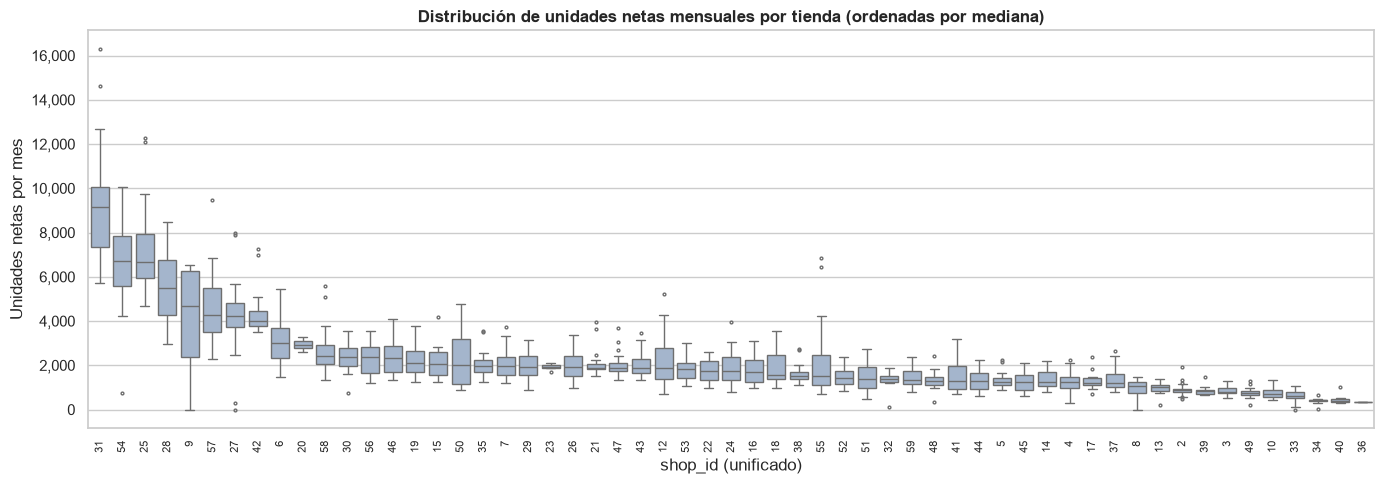

In [57]:
# Distribución de las unidades netas mensuales de cada tienda (nivel y variabilidad)
orden = mensual_por_tienda.groupby("shop_id").median().sort_values(ascending=False).index
datos_box = mensual_por_tienda.reset_index()
fig, eje = plt.subplots(figsize=(14, 5))
sns.boxplot(data=datos_box, x="shop_id", y="item_cnt_day", order=orden, ax=eje, color="#9DB4D3", fliersize=2)
eje.set_title("Distribución de unidades netas mensuales por tienda (ordenadas por mediana)")
eje.set_xlabel("shop_id (unificado)")
eje.set_ylabel("Unidades netas por mes")
eje.yaxis.set_major_formatter(miles)
eje.tick_params(axis="x", labelsize=8, rotation=90)
plt.tight_layout()
plt.show()

**Interpretación.**

**Tiendas líderes por unidades por mes activo.**
- La 31 (`Москва ТЦ "Семеновский"`): 9,140 unidades por mes, el 8.52 % de todas las unidades.
- La 25 (`Москва ТРК "Атриум"`): 7,115.
- La 54 (`Химки ТЦ "Мега"`): 6,635. Dejó de vender en el mes 27 y **no está en `test.csv`**.
- La 28: 5,428.
- La 57 (`Якутск Орджоникидзе, 56`, unificada): 4,494.

**Tiendas con menor volumen.**
- La 36 (`Новосибирск`) tiene 330 unidades, pero solo tuvo actividad en el último mes (33) y está en `test`: es una **tienda nueva con un solo mes de historia**.
- Le siguen la 34 (403), la 40 (449) y la 33 (609).

**Contraste.** La tienda con más unidades por mes vende **28 veces** más que la de menos.

**Tiendas atípicas.** Las tiendas 9 (itinerante) y 20 (liquidación) aparecen entre las 10 primeras en unidades por mes, pero porque solo tuvieron 4 y 2 meses activos con volúmenes concentrados. La tienda 9 tiene además una variabilidad mensual muy alta (CV = 0.77). Ninguna de las dos está en `test`.

**Actividad al final del periodo.**
- 44 tiendas estaban activas en el último mes y 13 dejaron de vender antes.
- Todas las tiendas de `test.csv` tienen ventas en el mes 33.

**Precio y volumen.** El ingreso medio por unidad varía entre tiendas, pero su correlación con el volumen es débil (Spearman = −0.18). Las tiendas que más venden no son sistemáticamente las de productos más caros ni las de más baratos.

**Boxplot.** Las tiendas grandes tienen además mayor dispersión absoluta de un mes a otro. Varias muestran meses excepcionalmente altos (puntos sobre los bigotes).

### 7c. Outliers y comportamientos anómalos
**Criterios estadísticos explícitos.** Ninguno de los casos detectados se elimina: solo se identifican y documentan.

1. **Extremos globales (cola alta):**
   - **Precio:** valores mayores que **Q3 + 3·IQR calculado en escala log10**. Es el criterio de "valor extremo" de Tukey, aplicado sobre el logaritmo porque la distribución de precios es muy asimétrica.
   - **Cantidad (`item_cnt_day` > 0):** se usa el **percentil 99.9**. El criterio de Tukey no sirve aquí porque la gran mayoría de los registros vale 1: Q1 = Q3 = 1, el IQR es 0 y el umbral resultante (1 unidad) marcaría como extrema cualquier venta de 2 o más unidades. La tabla siguiente muestra ambos umbrales para que esa limitación quede documentada.
2. **Precio atípico respecto al propio producto:** se compara cada precio con la mediana de precios de ese producto, en productos con al menos 20 registros. Es atípico si es **mayor que 5 veces o menor que 0.2 veces** esa mediana.
3. **Concentración por sucursal:** qué tiendas acumulan los registros de cantidad extrema (sobre el percentil 99.9).

In [58]:
def umbral_tukey_log(serie: pd.Series, k: float = 3.0) -> float:
    log = np.log10(serie)
    q1, q3 = log.quantile([0.25, 0.75])
    return 10 ** (q3 + k * (q3 - q1))


ventas_pos = ventas[ventas["item_cnt_day"] > 0]
umbrales = pd.DataFrame(
    {
        "Q1": [ventas["item_price"].quantile(0.25), ventas_pos["item_cnt_day"].quantile(0.25)],
        "Q3": [ventas["item_price"].quantile(0.75), ventas_pos["item_cnt_day"].quantile(0.75)],
        "umbral_Q3+3IQR_log10": [umbral_tukey_log(ventas["item_price"]), umbral_tukey_log(ventas_pos["item_cnt_day"])],
        "p99.9": [ventas["item_price"].quantile(0.999), ventas_pos["item_cnt_day"].quantile(0.999)],
        "máximo": [ventas["item_price"].max(), ventas_pos["item_cnt_day"].max()],
    },
    index=["item_price", "item_cnt_day (> 0)"],
)
umbrales["registros_sobre_umbral_tukey"] = [
    int((ventas["item_price"] > umbrales.loc["item_price", "umbral_Q3+3IQR_log10"]).sum()),
    int((ventas_pos["item_cnt_day"] > umbrales.loc["item_cnt_day (> 0)", "umbral_Q3+3IQR_log10"]).sum()),
]
umbrales["registros_sobre_p99.9"] = [
    int((ventas["item_price"] > umbrales.loc["item_price", "p99.9"]).sum()),
    int((ventas_pos["item_cnt_day"] > umbrales.loc["item_cnt_day (> 0)", "p99.9"]).sum()),
]
umbral_precio = umbrales.loc["item_price", "umbral_Q3+3IQR_log10"]
umbral_cnt = umbrales.loc["item_cnt_day (> 0)", "p99.9"]
umbrales["criterio_aplicado"] = ["Q3 + 3·IQR (log10)", "p99.9 (IQR = 0, Tukey no aplicable)"]
print(f"Umbral aplicado a precio: > {umbral_precio:,.2f} | umbral aplicado a cantidad: > {umbral_cnt:,.0f} unidades")
umbrales

Umbral aplicado a precio: > 64,515.48 | umbral aplicado a cantidad: > 22 unidades


,Q1,Q3,umbral_Q3+3IQR_log10,p99.9,máximo,registros_sobre_umbral_tukey,registros_sobre_p99.9,criterio_aplicado
item_price,249.00,999.00,"64,515.48","23,990.00","307,980.00",1,2932,Q3 + 3·IQR (log10)
item_cnt_day (> 0),1.00,1.00,1.00,22.00,"2,169.00",299121,2882,"p99.9 (IQR = 0, Tukey no aplicable)"


In [59]:
cols_out = ["date", "shop_id", "item_id", "item_name", "item_category_name", "item_price", "item_cnt_day", "ingresos"]
fmt_out = {"item_price": "{:,.2f}", "item_cnt_day": "{:,.0f}", "ingresos": "{:,.0f}"}
extremos_cnt = ventas.nlargest(10, "item_cnt_day")[cols_out].assign(item_name=lambda d: d["item_name"].map(recortar))
extremos_precio = ventas.nlargest(10, "item_price")[cols_out].assign(item_name=lambda d: d["item_name"].map(recortar))
display(extremos_cnt.style.format(fmt_out).set_caption("10 registros con mayor cantidad diaria"))
display(extremos_precio.style.format(fmt_out).set_caption("10 registros con mayor precio"))

,date,shop_id,item_id,item_name,item_category_name,item_price,item_cnt_day,ingresos
2909818,2015-10-28 00:00:00,12,11373,Доставка до пункта выдачи (Boxberry),Доставка товара,0.91,"2,169","1,971"
2326930,2015-01-15 00:00:00,12,20949,Фирменный пакет майка 1С Интерес белый (34*4…,"Подарки - Сумки, Альбомы, Коврики д/мыши",4.00,"1,000","4,000"
2864235,2015-09-30 00:00:00,12,9248,"Билет ""ИгроМир 2015"" - 3 октября 2015 (сайт)…",Служебные - Билеты,"1,692.53",669,"1,132,300"
2851091,2015-09-30 00:00:00,55,9249,"Билет ""ИгроМир 2015"" - 3 октября 2015 (сайт)…",Билеты (Цифра),"1,702.83",637,"1,084,700"
2608040,2015-04-14 00:00:00,12,3731,"Grand Theft Auto V [PC, русские субтитры]",Игры PC - Стандартные издания,"1,904.55",624,"1,188,438"
2626181,2015-05-19 00:00:00,12,11373,Доставка до пункта выдачи (Boxberry),Доставка товара,155.19,539,"83,649"
2851073,2015-09-29 00:00:00,55,9249,"Билет ""ИгроМир 2015"" - 3 октября 2015 (сайт)…",Билеты (Цифра),"1,500.00",533,"799,500"
2048518,2014-10-02 00:00:00,12,9242,"Билет ""ИгроМир 2014"" (на один день (отдельно…",Билеты (Цифра),"1,500.00",512,"768,000"
2067669,2014-10-09 00:00:00,55,19437,"Средиземье: Тени Мордора [PC, Цифровая верси…",Игры PC - Цифра,899.00,508,"456,692"
2864260,2015-09-29 00:00:00,12,9248,"Билет ""ИгроМир 2015"" - 3 октября 2015 (сайт)…",Служебные - Билеты,"1,500.00",504,"756,000"


,date,shop_id,item_id,item_name,item_category_name,item_price,item_cnt_day,ingresos
1163158,2013-12-13 00:00:00,12,6066,Radmin 3 - 522 лиц.,Программы - Для дома и офиса,"307,980.00",1,"307,980"
885138,2013-09-17 00:00:00,12,11365,Доставка (EMS),Доставка товара,"59,200.00",1,"59,200"
1488135,2014-03-20 00:00:00,25,13199,Коллекционные шахматы (Властелин Колец),Подарки - Сувениры,"50,999.00",1,"50,999"
2327159,2015-01-29 00:00:00,12,7241,UserGate Proxy & Firewall 6.X с модулем филь…,Программы - Для дома и офиса,"49,782.00",1,"49,782"
2885692,2015-10-23 00:00:00,42,13403,"Комплект ""Microsoft Xbox One 1TB Limited Ed…",Игровые консоли - XBOX ONE,"42,990.00",1,"42,990"
2910156,2015-10-29 00:00:00,12,13403,"Комплект ""Microsoft Xbox One 1TB Limited Ed…",Игровые консоли - XBOX ONE,"42,990.00",1,"42,990"
2917760,2015-10-20 00:00:00,3,13403,"Комплект ""Microsoft Xbox One 1TB Limited Ed…",Игровые консоли - XBOX ONE,"42,990.00",1,"42,990"
2931380,2015-10-20 00:00:00,22,13403,"Комплект ""Microsoft Xbox One 1TB Limited Ed…",Игровые консоли - XBOX ONE,"42,990.00",1,"42,990"
1006638,2013-10-24 00:00:00,12,7238,UserGate Proxy & Firewall 6.X до 100 сессий,Программы - Для дома и офиса,"42,000.00",1,"42,000"
2893100,2015-10-20 00:00:00,38,13403,"Комплект ""Microsoft Xbox One 1TB Limited Ed…",Игровые консоли - XBOX ONE,"41,990.00",1,"41,990"


In [60]:
# Contexto de los casos más extremos: ¿cómo se comporta normalmente ese producto?
casos = pd.concat([extremos_cnt.head(3), extremos_precio.head(3)]).drop_duplicates(subset=["date", "shop_id", "item_id"])
contexto = []
for _, c in casos.iterrows():
    h = ventas[ventas["item_id"] == c["item_id"]]
    contexto.append(
        {
            "item_id": c["item_id"],
            "item_name": recortar(c["item_name"], 40),
            "valor_extremo": f"precio {c['item_price']:,.0f} / cantidad {c['item_cnt_day']:,.0f}",
            "registros_del_producto": len(h),
            "tiendas_del_producto": h["shop_id"].nunique(),
            "mediana_precio_producto": h["item_price"].median(),
            "mediana_cantidad_producto": h["item_cnt_day"].median(),
            "max_cantidad_otros_registros": h.drop(index=h.index[(h["date"] == c["date"]) & (h["shop_id"] == c["shop_id"])])["item_cnt_day"].max(),
        }
    )
pd.DataFrame(contexto)

,item_id,item_name,valor_extremo,registros_del_producto,tiendas_del_producto,mediana_precio_producto,mediana_cantidad_producto,max_cantidad_otros_registros
0,11373,Доставка до пункта выдачи (Boxberry),"precio 1 / cantidad 2,169",464,1,281.62,4.00,539.00
1,20949,Фирменный пакет майка 1С Интерес белый …,"precio 4 / cantidad 1,000",31340,52,5.00,3.00,501.00
2,9248,"Билет ""ИгроМир 2015"" - 3 октября 2015 (…","precio 1,693 / cantidad 669",61,2,"1,500.00",2.00,504.00
3,6066,Radmin 3 - 522 лиц.,"precio 307,980 / cantidad 1",1,1,"307,980.00",1.00,NaN
4,11365,Доставка (EMS),"precio 59,200 / cantidad 1",242,1,"1,203.75",2.00,103.00
5,13199,Коллекционные шахматы (Властелин Колец),"precio 50,999 / cantidad 1",1,1,"50,999.00",1.00,NaN


In [61]:
# Criterio 2: precio atípico respecto a la mediana del propio producto
stats_item = ventas.groupby("item_id")["item_price"].agg(n="size", mediana="median")
con_historia = ventas.join(stats_item, on="item_id")
con_historia = con_historia[con_historia["n"] >= 20]
con_historia["ratio_precio"] = con_historia["item_price"] / con_historia["mediana"]
atipicos_precio = con_historia[(con_historia["ratio_precio"] > 5) | (con_historia["ratio_precio"] < 0.2)]

print(f"Registros evaluados (productos con >= 20 registros): {len(con_historia):,}")
print(f"Precios > 5x la mediana del producto: {(con_historia['ratio_precio'] > 5).sum():,}")
print(f"Precios < 0.2x la mediana del producto: {(con_historia['ratio_precio'] < 0.2).sum():,}")
print(f"Productos involucrados: {atipicos_precio['item_id'].nunique():,}")
display(atipicos_precio.groupby("item_category_name").size().sort_values(ascending=False).head(8)
        .rename("registros_atipicos").to_frame())
(atipicos_precio.assign(item_name=lambda d: d["item_name"].map(recortar))
 .sort_values("ratio_precio")[cols_out + ["mediana", "ratio_precio"]]
 .iloc[np.r_[0:5, -5:0]]
 .style.format({**fmt_out, "mediana": "{:,.2f}", "ratio_precio": "{:.3f}"})
 .set_caption("Los 5 ratios más bajos y los 5 más altos"))

Registros evaluados (productos con >= 20 registros): 2,879,772
Precios > 5x la mediana del producto: 3,921
Precios < 0.2x la mediana del producto: 9,650
Productos involucrados: 1,221


,registros_atipicos
item_category_name,
Кино - DVD,2964
Игры PC - Стандартные издания,2651
Кино - Blu-Ray,2463
Подарки - Мягкие игрушки,1507
Служебные,646
Игры - PS3,584
Кино - Blu-Ray 3D,583
Игры - XBOX 360,458


,date,shop_id,item_id,item_name,item_category_name,item_price,item_cnt_day,ingresos,mediana,ratio_precio
1865999,2014-07-12 00:00:00,25,1851,"Battlefield 4 Limited Edition [Xbox 360, рус…",Игры - XBOX 360,0.50,1,0,"1,999.00",0.000
1866000,2014-07-13 00:00:00,25,1850,"Battlefield 4 Limited Edition [PS3, русская …",Игры - PS3,0.50,1,0,"1,999.00",0.000
1824813,2014-07-07 00:00:00,52,1851,"Battlefield 4 Limited Edition [Xbox 360, рус…",Игры - XBOX 360,0.50,1,0,"1,999.00",0.000
1824814,2014-07-07 00:00:00,52,1850,"Battlefield 4 Limited Edition [PS3, русская …",Игры - PS3,0.50,1,0,"1,999.00",0.000
1822082,2014-07-01 00:00:00,47,1850,"Battlefield 4 Limited Edition [PS3, русская …",Игры - PS3,0.50,1,0,"1,999.00",0.000
87961,2013-01-02 00:00:00,47,11865,Змей МАКС антистресс 33 см.,Подарки - Мягкие игрушки,729.00,1,729,0.10,7290.000
71638,2013-01-02 00:00:00,31,11865,Змей МАКС антистресс 33 см.,Подарки - Мягкие игрушки,729.00,1,729,0.10,7290.000
85167,2013-01-01 00:00:00,54,11857,Змей ВАСЯ антистресс 36 см.,Подарки - Мягкие игрушки,729.00,1,729,0.10,7290.000
113481,2013-01-02 00:00:00,44,11857,Змей ВАСЯ антистресс 36 см.,Подарки - Мягкие игрушки,729.00,1,729,0.10,7290.000
6664,2013-01-02 00:00:00,25,11865,Змей МАКС антистресс 33 см.,Подарки - Мягкие игрушки,729.00,1,729,0.10,7290.000


In [62]:
# Precios simbólicos (< 1 rublo): ¿errores aislados o un patrón sistemático?
simbolicos = ventas[ventas["item_price"] < 1]
print(f"Registros con precio < 1 rublo: {len(simbolicos):,} ({100 * len(simbolicos) / len(ventas):.2f}%) | "
      f"productos: {simbolicos['item_id'].nunique():,} | tiendas: {simbolicos['shop_id'].nunique()}")
(simbolicos.groupby("item_id")
 .agg(registros=("item_price", "size"), precio_min=("item_price", "min"), precio_max=("item_price", "max"),
      tiendas=("shop_id", "nunique"), desde=("date", "min"), hasta=("date", "max"))
 .join(items.set_index("item_id")["item_name"].map(recortar))
 .sort_values("registros", ascending=False).head(8))

Registros con precio < 1 rublo: 4,657 (0.16%) | productos: 66 | tiendas: 47


,registros,precio_min,precio_max,tiendas,desde,hasta,item_name
item_id,,,,,,,
11867,252,0.10,0.10,33,2013-06-01,2013-08-29,Змей ШНУР 15 см
15346,237,0.99,0.99,39,2015-07-14,2015-09-24,Мягкая игрушка Веселая овечка Заводная 11см
11853,212,0.10,0.10,31,2013-06-01,2013-08-30,Змей ВАЛЕНТИН 16 см
20141,202,0.10,0.10,31,2013-06-01,2013-08-31,Удавчик Плюшевый: 40см на сердечке
11854,191,0.10,0.10,38,2013-06-01,2013-08-26,Змей ВАСЯ 22 см
1855,183,0.50,0.50,40,2014-06-30,2014-07-27,"Battlefield 4 [PC, русская версия]"
1856,148,0.50,0.50,38,2014-06-30,2014-07-27,"Battlefield 4 [PS3, русская версия]"
11865,141,0.07,0.10,34,2013-06-01,2013-08-31,Змей МАКС антистресс 33 см.


In [63]:
# Criterio 3: tiendas con registros de cantidad extrema (sobre el percentil 99.9)
extremos_por_tienda = (
    ventas_pos.assign(extremo=ventas_pos["item_cnt_day"] > umbral_cnt)
    .groupby("shop_id")
    .agg(registros=("extremo", "size"), extremos=("extremo", "sum"),
         unidades_en_extremos=("item_cnt_day", lambda s: s[s > umbral_cnt].sum()), unidades=("item_cnt_day", "sum"))
)
extremos_por_tienda["%_registros_extremos"] = 100 * extremos_por_tienda["extremos"] / extremos_por_tienda["registros"]
extremos_por_tienda["%_unidades_en_extremos"] = 100 * extremos_por_tienda["unidades_en_extremos"] / extremos_por_tienda["unidades"]
extremos_por_tienda["nombre"] = nombre_tienda_u.reindex(extremos_por_tienda.index).map(recortar)
print(f"Umbral de cantidad extrema: > {umbral_cnt:,.0f} unidades por registro | "
      f"registros extremos: {int(extremos_por_tienda['extremos'].sum()):,} en {(extremos_por_tienda['extremos'] > 0).sum()} tiendas")
extremos_por_tienda.sort_values("extremos", ascending=False).head(8)

Umbral de cantidad extrema: > 22 unidades por registro | registros extremos: 2,882 en 52 tiendas


,registros,extremos,unidades_en_extremos,unidades,%_registros_extremos,%_unidades_en_extremos,nombre
shop_id,,,,,,,
31,235185,502,"18,394.00","311,230.00",0.21,5.91,"Москва ТЦ ""Семеновский"""
25,185787,316,"12,768.00","242,236.00",0.17,5.27,"Москва ТРК ""Атриум"""
12,34264,289,"22,750.00","73,990.00",0.84,30.75,Интернет-магазин ЧС
54,143123,232,"8,694.00","186,148.00",0.16,4.67,"Химки ТЦ ""Мега"""
28,142018,200,"6,863.00","184,777.00",0.14,3.71,"Москва ТЦ ""МЕГА Теплый Стан"" II"
55,34767,168,"11,944.00","63,390.00",0.48,18.84,Цифровой склад 1С-Онлайн
42,109001,153,"6,748.00","145,194.00",0.14,4.65,"СПб ТК ""Невский Центр"""
27,105209,115,"4,947.00","136,815.00",0.11,3.62,"Москва ТЦ ""МЕГА Белая Дача II"""


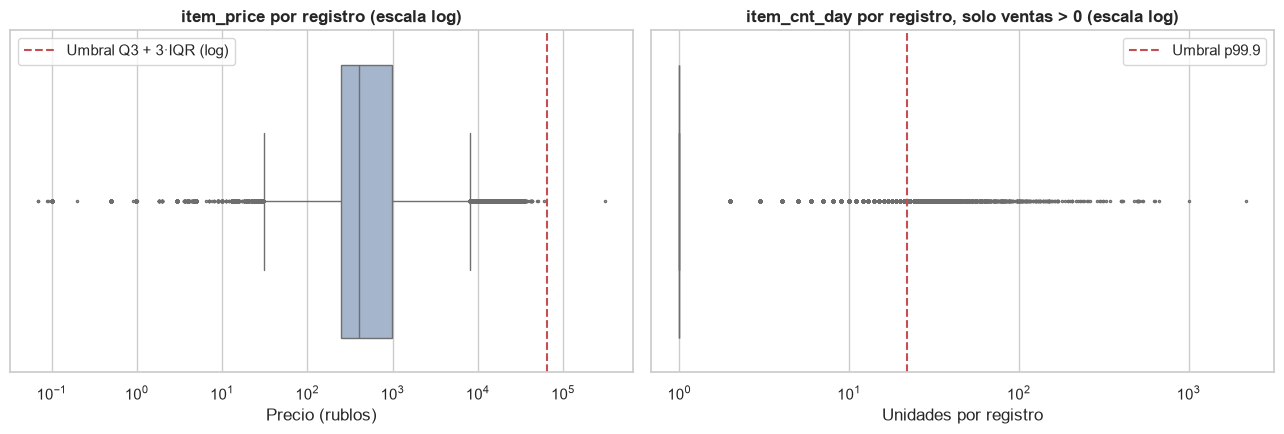

In [64]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.boxplot(x=ventas["item_price"], ax=ejes[0], color="#9DB4D3", fliersize=1.5, log_scale=True)
ejes[0].axvline(umbral_precio, c="#C44E52", ls="--", label="Umbral Q3 + 3·IQR (log)")
ejes[0].set_title("item_price por registro (escala log)")
ejes[0].set_xlabel("Precio (rublos)")
ejes[0].legend(loc="upper left")

sns.boxplot(x=ventas_pos["item_cnt_day"], ax=ejes[1], color="#9DB4D3", fliersize=1.5, log_scale=True)
ejes[1].axvline(umbral_cnt, c="#C44E52", ls="--", label="Umbral p99.9")
ejes[1].set_title("item_cnt_day por registro, solo ventas > 0 (escala log)")
ejes[1].set_xlabel("Unidades por registro")
ejes[1].legend(loc="upper right")
plt.tight_layout()
plt.show()

**Interpretación.**

**Precio.**
- **Criterio de Tukey en log10:** con umbral de 64,515 solo marca **1 registro**: `Radmin 3 - 522 лиц.` (licencia para 522 puestos) a 307,980 en la tienda online (shop 12). Es el único registro de ese producto, así que no hay referencia para compararlo. Por su descripción es coherente con una venta corporativa legítima, aunque no puede verificarse.
- **Percentil 99.9 (23,990), como referencia:** 2,932 registros. Entre los diez de mayor precio aparecen productos caros legítimos, como el paquete `Xbox One 1TB Limited Edition` a 42,990, vendido en cinco tiendas en octubre de 2015.
- **Envío caro:** `Доставка (EMS)` a 59,200 es atípico para su propio producto (mediana 1,203.75). Puede ser un envío voluminoso o un error de captura; no es concluyente.

**Cantidad (p99.9 = más de 22 unidades por registro, 2,882 registros en 52 tiendas).** Los casos más extremos se concentran en la tienda online (shop 12) y el almacén digital (shop 55):
- **`Доставка до пункта выдачи (Boxberry)`: 2,169 unidades a 0.91 cada una** (28.10.2015). En el resto de sus registros, la mediana del producto es 4 unidades, el máximo 539 y el precio mediano 281.62. Combina una cantidad y un precio anómalos: es el **candidato más claro a error o a un registro agregado**.
- **Bolsa de la tienda: 1,000 unidades a 4** en un día. El resto de sus registros tiene una mediana de 3 unidades y un máximo de 501. Es posiblemente una salida en lote; un artículo no comercial.
- **Entradas `ИгроМир 2015`: 669, 637, 533 y 504 unidades** el 29 y 30 de septiembre de 2015 en las tiendas 12 y 55. Es una demanda concentrada antes del evento del 3 de octubre que figura en el nombre del producto: **comportamiento comercial legítimo**.
- **`Grand Theft Auto V [PC]`: 624 unidades el 14.04.2015** en la shop 12. Coincide con el pico diario de 6b-iii.

**Por tienda.** En la shop 12 el 30.75 % de sus unidades proviene de registros extremos, y en la 55 el 18.84 %. En las tiendas físicas con más casos (31, 25, 54, 28, 42, 27) esa proporción es de entre el 3.6 % y el 5.9 %. Las cantidades extremas son un rasgo del **canal online/digital**.

**Precio relativo al propio producto.** Se marcan 3,921 registros más de 5 veces sobre su mediana y 9,650 por debajo de 0.2 veces, en 1,221 productos. Dos patrones dominan:
- **`Battlefield 4 Limited Edition`** se registra a 0.50 frente a una mediana de 1,999.
- **Peluches `Змей …`** tienen una mediana de 0.10, así que su precio "normal" de 729 aparece como atípico. Esto muestra una **limitación del criterio** cuando el precio dominante es simbólico.

**Precios simbólicos (menos de 1 rublo).** Hay **4,657 registros (0.16 %)** en 66 productos y 47 tiendas. No son errores aislados:
- Los peluches `Змей` a 0.10 aparecen en 31–38 tiendas entre junio y agosto de 2013.
- `Battlefield 4 [PC/PS3]` a 0.50 aparece en 38–40 tiendas entre el 30.06 y el 27.07.2014.

Son periodos acotados y simultáneos en muchas tiendas, lo que es **coherente con promociones o regalos**. Los datos no permiten confirmarlo.

**Clasificación y tratamiento propuesto (sin eliminar nada):**

| Caso | Posible naturaleza | Tratamiento sugerido para el modelado |
|---|---|---|
| Boxberry: 2,169 unidades a 0.91 | Probable error o registro agregado | Revisar; candidato a acotar (*clip*) |
| Bolsa de la tienda, envíos, recepción de pagos | Artículos no comerciales o servicios | Identificarlos; su volumen distorsiona los rankings por unidades |
| Entradas IgroMir; picos de lanzamiento | Demanda legítima por evento | Conservar |
| Consolas y licencias de alto precio | Productos caros legítimos | Conservar |
| Precios simbólicos (< 1 rublo) | Promociones o regalos sistemáticos | Conservar las unidades; no usarlos para estimar el precio típico |
| Devoluciones extremas (−22, −16) | Devoluciones reales | Conservar (ventas netas) |

*Recomendación opcional para la etapa de forecasting (no la exigen las instrucciones): definir un límite superior para la variable objetivo mensual, para que los registros extremos del canal online no dominen el ajuste.*

### Control de consistencia de las secciones 5–7
Verificación de que los análisis usan la base limpia completa: los totales de `ventas` coinciden con los de `sales_clean` tras la conciliación de la sección 4.

In [65]:
control_final = pd.DataFrame(
    {
        "sales_clean (sección 4)": totales_post_unificacion[["registros", "unidades_netas", "ingresos"]],
        "ventas (secciones 5–7)": [len(ventas), ventas["item_cnt_day"].sum(), ventas["ingresos"].sum()],
        "suma mensual": [mensual["registros"].sum(), mensual["unidades"].sum(), mensual["ingresos"].sum()],
        "suma por tienda": [np.nan, por_tienda["unidades"].sum(), por_tienda["ingresos"].sum()],
    }
)
control_final["consistente"] = control_final.apply(lambda r: np.allclose(r.dropna().to_numpy(dtype=float), r.iloc[0]), axis=1)
assert control_final["consistente"].all()
control_final

,sales_clean (sección 4),ventas (secciones 5–7),suma mensual,suma por tienda,consistente
registros,"2,935,843.00","2,935,843.00","2,935,843.00",NaN,True
unidades_netas,"3,648,200.00","3,648,200.00","3,648,200.00","3,648,200.00",True
ingresos,"3,398,923,575.57","3,398,923,575.57","3,398,923,575.57","3,398,923,575.57",True


## 8. Visualizaciones clave (obligatorias)

Todas las gráficas usan `ventas` (derivada de `sales_clean`): tiendas unificadas, devoluciones incluidas (**unidades netas**) e ingresos = `item_price × item_cnt_day`.

**Artículos no comerciales.** En la sección 7a aparecieron en los rankings artículos que no son mercancía. Aquí se identifican con una regla explícita para **señalarlos** en las gráficas. **No se excluyen** de ningún cálculo.

Un artículo se considera no comercial si cumple alguna de estas condiciones:
- su categoría es `Служебные` (servicios internos, como la recepción de pagos);
- su categoría es `Доставка товара` (envíos);
- su nombre empieza por `Фирменный пакет` (bolsas con la marca de la tienda).

In [66]:
from matplotlib.colors import TwoSlopeNorm
from matplotlib.patches import Patch

CATEGORIAS_NO_COMERCIALES = {"Служебные", "Доставка товара"}
ventas["no_comercial"] = ventas["item_category_name"].isin(CATEGORIAS_NO_COMERCIALES) | ventas[
    "item_name"
].str.startswith("Фирменный пакет")

no_com = ventas[ventas["no_comercial"]]
print(f"Artículos no comerciales: {no_com['item_id'].nunique()} productos | "
      f"{no_com['item_cnt_day'].sum():,.0f} unidades netas "
      f"({100 * no_com['item_cnt_day'].sum() / ventas['item_cnt_day'].sum():.2f}% del total) | "
      f"{100 * no_com['ingresos'].sum() / ventas['ingresos'].sum():.2f}% de los ingresos")
(no_com.groupby(["item_id", "item_name", "item_category_name"])["item_cnt_day"].sum()
 .sort_values(ascending=False).head(8).rename("unidades").reset_index()
 .assign(item_name=lambda d: d["item_name"].map(recortar)))

Artículos no comerciales: 14 productos | 221,590 unidades netas (6.07% del total) | 0.73% de los ingresos


,item_id,item_name,item_category_name,unidades
0,20949,Фирменный пакет майка 1С Интерес белый (34*4…,"Подарки - Сумки, Альбомы, Коврики д/мыши","187,642.00"
1,17717,Прием денежных средств для 1С-Онлайн,Служебные,"15,830.00"
2,11373,Доставка до пункта выдачи (Boxberry),Доставка товара,"6,563.00"
3,11370,Доставка (по Москве),Доставка товара,"6,163.00"
4,11369,Доставка (Почта),Доставка товара,"2,688.00"
5,11365,Доставка (EMS),Доставка товара,"1,007.00"
6,13753,Курьерская доставка (Boxberry),Доставка товара,653.00
7,11372,Доставка до постомата (PickPoint),Доставка товара,519.00


### 8a. Serie de tiempo de ventas totales
Unidades netas mensuales (métrica principal), con su media móvil centrada de 12 meses (que aproxima la tendencia sin estacionalidad), e ingresos mensuales en el eje secundario (métrica complementaria). Los meses de diciembre están marcados.

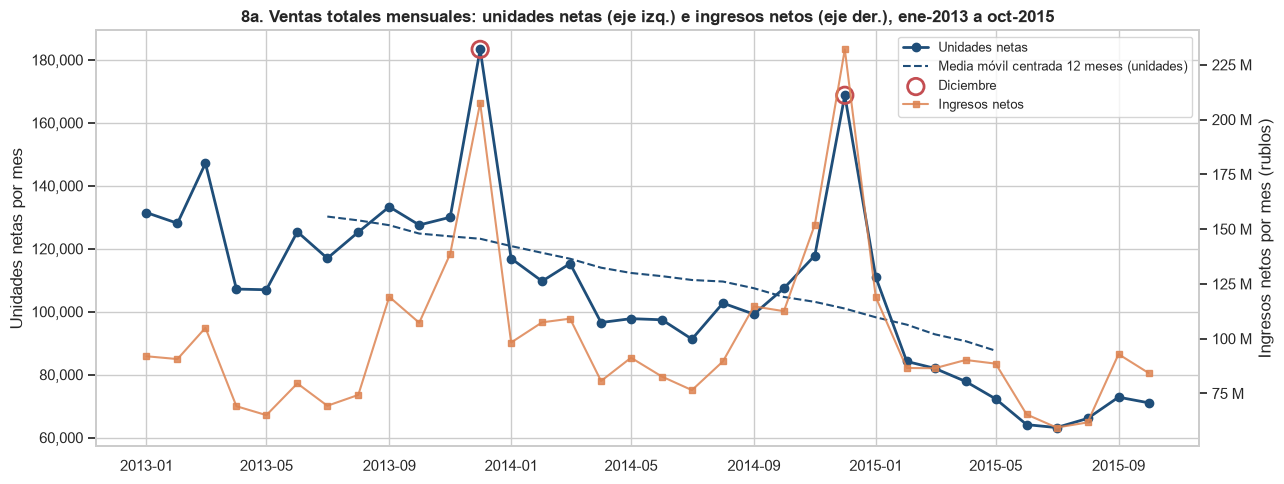

In [67]:
fechas_mes = pd.to_datetime(mensual["mes"])
fig, eje = plt.subplots(figsize=(13, 5))
eje.plot(fechas_mes, mensual["unidades"], marker="o", color="#1F4E79", lw=2, label="Unidades netas")
eje.plot(fechas_mes, mensual["unidades"].rolling(12, center=True).mean(), color="#1F4E79", ls="--", lw=1.5,
         label="Media móvil centrada 12 meses (unidades)")
dic = fechas_mes.dt.month == 12
eje.scatter(fechas_mes[dic], mensual.loc[dic.values, "unidades"], s=140, facecolors="none", edgecolors="#C44E52",
            lw=2, zorder=5, label="Diciembre")
eje.set_ylabel("Unidades netas por mes")
eje.yaxis.set_major_formatter(miles)

eje_ing = eje.twinx()
eje_ing.plot(fechas_mes, mensual["ingresos"], color="#DD8452", alpha=0.85, marker="s", ms=4, label="Ingresos netos")
eje_ing.set_ylabel("Ingresos netos por mes (rublos)")
eje_ing.yaxis.set_major_formatter(millones)
eje_ing.grid(False)

lineas = eje.get_legend_handles_labels()[0] + eje_ing.get_legend_handles_labels()[0]
eje.legend(lineas, [l.get_label() for l in lineas], loc="upper right", fontsize=9)
eje.set_title("8a. Ventas totales mensuales: unidades netas (eje izq.) e ingresos netos (eje der.), ene-2013 a oct-2015")
plt.tight_layout()
plt.show()

**Interpretación.**
- **Tendencia:** la media móvil de 12 meses de las unidades **desciende de forma continua** durante todo el periodo. La serie pasa de 106,970–147,142 unidades mensuales en 2013 (sin contar diciembre) a 63,187–72,843 entre mayo y octubre de 2015.
- **Estacionalidad:** los dos diciembres son los máximos absolutos (183,342 unidades en 2013 y 168,754 en 2014), seguidos de caídas bruscas en enero. De abril a julio, las ventas de 2013 y 2014 quedan por debajo del promedio mensual de su año (índices entre 82 y 96, sección 6b-ii).
- **Ingresos frente a unidades:** los ingresos repiten los picos de diciembre, y el de diciembre de 2014 (232.0 millones) supera al de 2013 (207.6 millones) aunque se vendieron menos unidades. Desde la segunda mitad de 2013 la línea de ingresos se mantiene relativamente alta frente a las unidades, en línea con el aumento del ingreso medio por unidad documentado en 5b-iii. En 2015 ambas series caen juntas y llegan a su mínimo en julio (63,187 unidades y 59.4 millones).

### 8b. Ventas por sucursal
Unidades netas totales por tienda (IDs unificados), ordenadas de mayor a menor. El color distingue las tiendas presentes en `test.csv`, y la etiqueta indica el % del total y los meses activos, porque el total depende de cuánto tiempo operó cada tienda (la comparación por mes activo está en 7b).

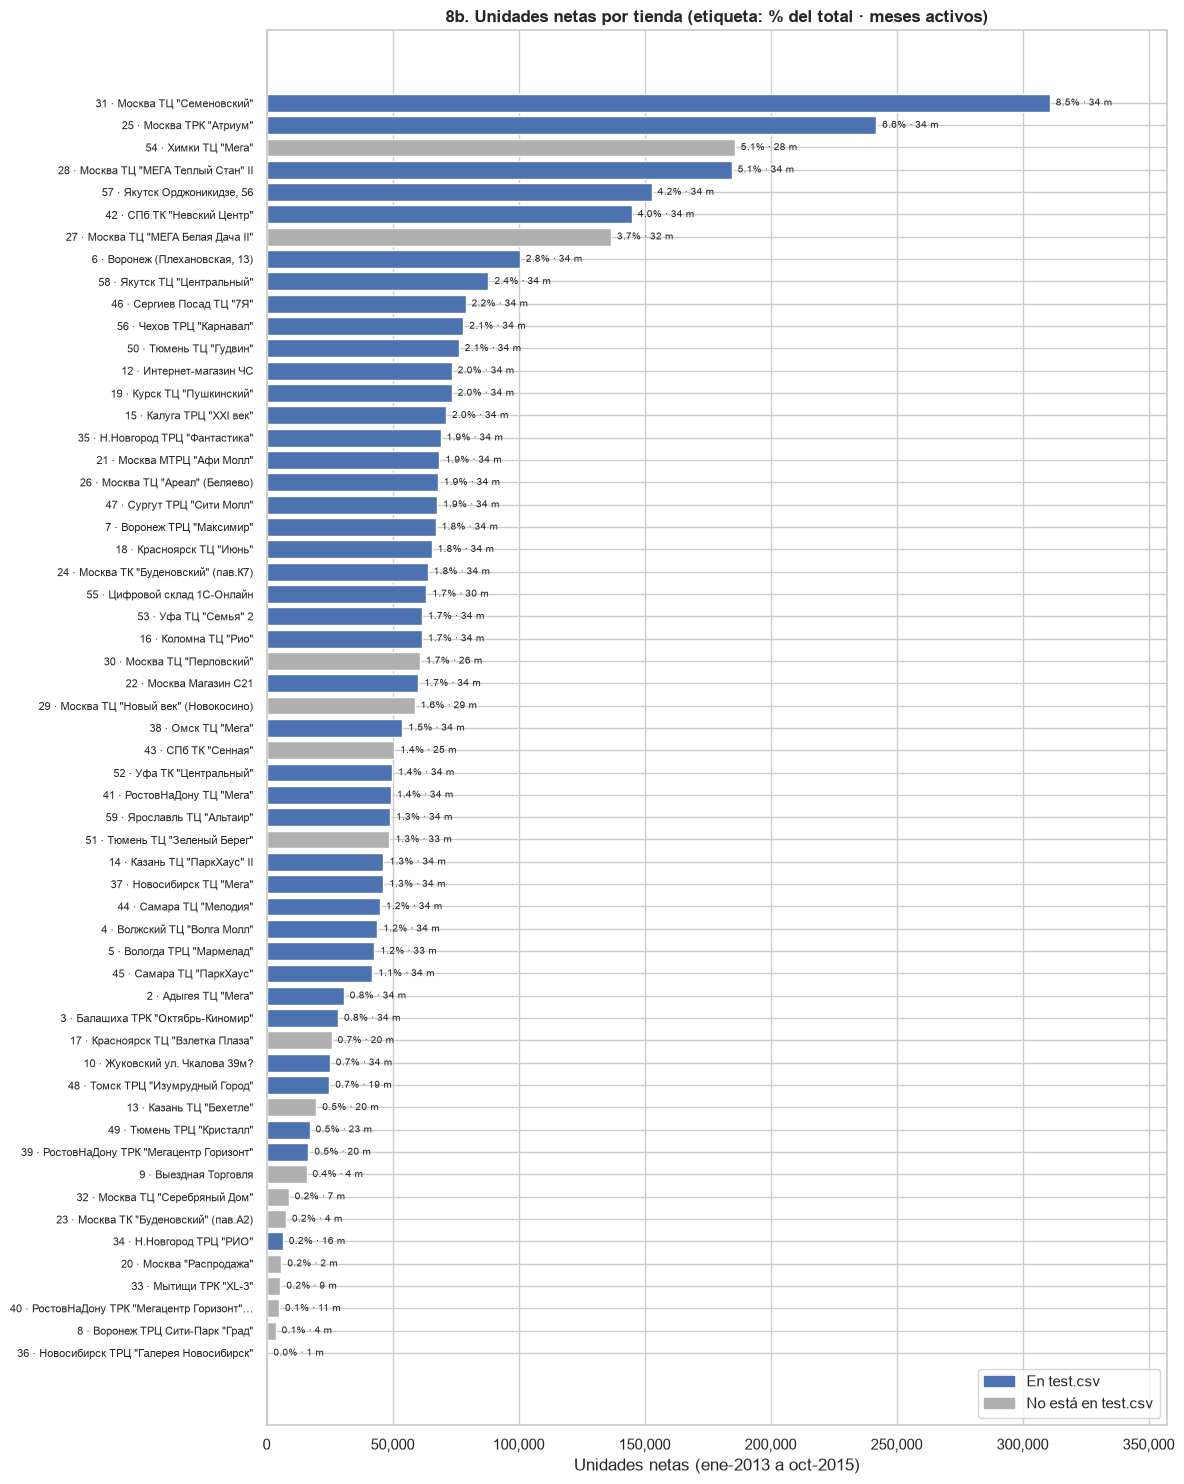

Tiendas necesarias para acumular el 50% de las unidades: 13 de 57
Tiendas necesarias para acumular el 80% de las unidades: 30 de 57


In [68]:
graf_t = desempeno.sort_values("unidades")
etiquetas_t = [f"{i} · {recortar(nombre_tienda_u[i], 38)}" for i in graf_t.index]
colores_t = np.where(graf_t["en_test"], "#4C72B0", "#B0B0B0")

fig, eje = plt.subplots(figsize=(12, 15))
eje.barh(etiquetas_t, graf_t["unidades"], color=colores_t)
for y, (u, p, m) in enumerate(zip(graf_t["unidades"], graf_t["%_unidades"], graf_t["meses_activos"])):
    eje.text(u, y, f"  {p:.1f}% · {m} m", va="center", fontsize=7.5)
eje.xaxis.set_major_formatter(miles)
eje.set_xlabel("Unidades netas (ene-2013 a oct-2015)")
eje.tick_params(axis="y", labelsize=8)
eje.set_xlim(0, graf_t["unidades"].max() * 1.15)
eje.legend(handles=[Patch(color="#4C72B0", label="En test.csv"), Patch(color="#B0B0B0", label="No está en test.csv")],
           loc="lower right")
eje.set_title("8b. Unidades netas por tienda (etiqueta: % del total · meses activos)")
plt.tight_layout()
plt.show()

acum = desempeno.sort_values("unidades", ascending=False)["%_unidades"].cumsum()
print(f"Tiendas necesarias para acumular el 50% de las unidades: {(acum < 50).sum() + 1} de {len(acum)}")
print(f"Tiendas necesarias para acumular el 80% de las unidades: {(acum < 80).sum() + 1} de {len(acum)}")

**Interpretación.**
- **Concentración moderada:** **13 de las 57 tiendas** acumulan el 50 % de las unidades netas y 30 acumulan el 80 %. La tienda 31 (`Москва ТЦ "Семеновский"`) lidera con el 8.5 %, seguida de la 25 (6.6 %).
- **Peso de Moscú:** cuatro de las seis primeras tiendas están en Moscú o en su área (31, 25, 54 y 28). La 57 (Якутск) y la 42 (San Petersburgo) completan el grupo líder.
- **Tiendas fuera de `test` (en gris):** dos de ellas tienen un volumen alto, la 54 (5.1 %, 28 meses) y la 27 (3.7 %, 32 meses), porque dejaron de operar antes del final del periodo. Su historial pesa en los totales, pero no habrá que predecirlas.
- **Cola de tiendas pequeñas:** la parte baja del gráfico está formada sobre todo por tiendas con pocos meses activos (36: 1 mes; 8: 4; 40: 11; 33: 9; 20: 2). Su total bajo refleja historia corta, no necesariamente baja productividad. Por eso, en 7b la comparación se hizo por mes activo.

### 8c. Ventas por producto (top 20) y por categoría
- **Productos:** los 20 con más unidades netas. Los artículos no comerciales aparecen en otro color.
- **Categorías:** las 84, con eje en **escala logarítmica**, porque sus volúmenes van de 1 a más de 600,000 unidades y en escala lineal la mayoría serían invisibles. Se marcan en otro color las categorías en las que los artículos no comerciales aportan más del 50 % de las unidades.

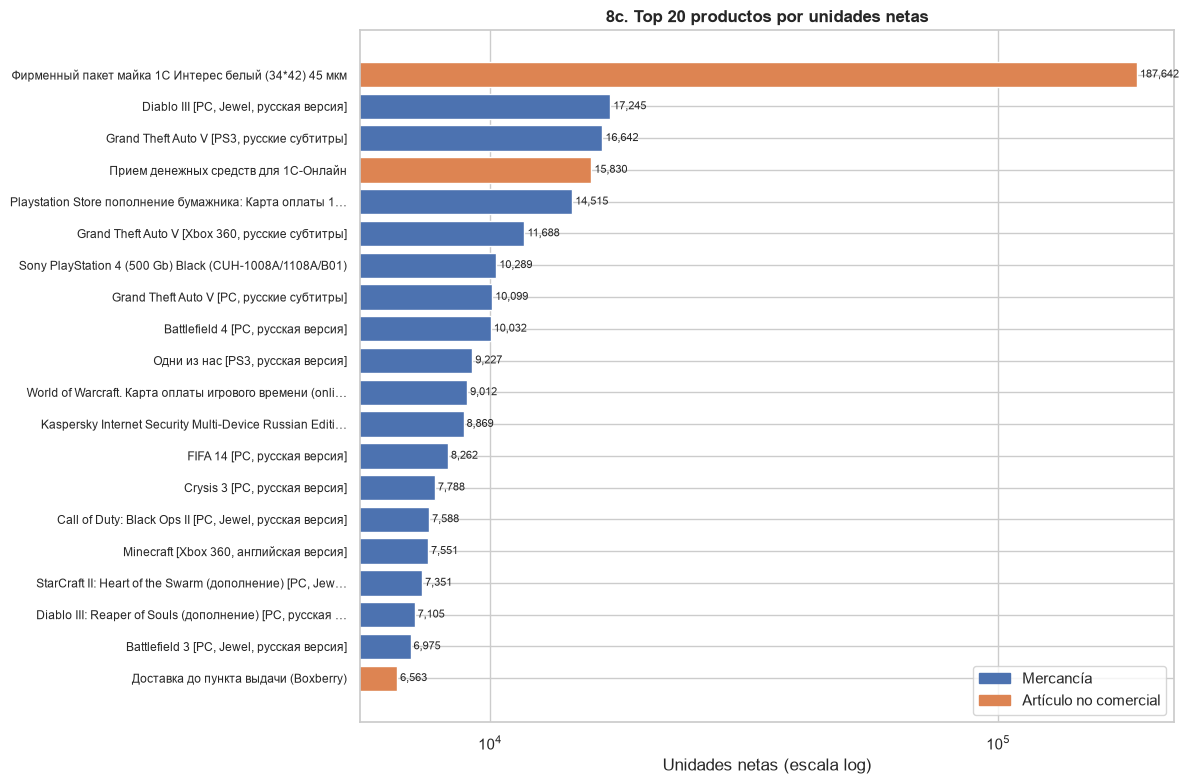

No comerciales en el top 20: 3 -> Фирменный пакет майка 1С Интерес белый …, Прием денежных средств для 1С-Онлайн, Доставка до пункта выдачи (Boxberry)


In [69]:
top20_g = ranking_productos.sort_values("unidades", ascending=False).head(20)
es_nc = top20_g.index.isin(ventas.loc[ventas["no_comercial"], "item_id"].unique())
top20_g = top20_g.iloc[::-1]
es_nc = es_nc[::-1]

fig, eje = plt.subplots(figsize=(12, 8))
eje.barh([recortar(n, 55) for n in top20_g["item_name"]], top20_g["unidades"],
         color=np.where(es_nc, "#DD8452", "#4C72B0"))
for y, u in enumerate(top20_g["unidades"]):
    eje.text(u, y, f" {u:,.0f}", va="center", fontsize=8)
eje.set_xscale("log")
eje.set_xlabel("Unidades netas (escala log)")
eje.tick_params(axis="y", labelsize=8.5)
eje.legend(handles=[Patch(color="#4C72B0", label="Mercancía"), Patch(color="#DD8452", label="Artículo no comercial")],
           loc="lower right")
eje.set_title("8c. Top 20 productos por unidades netas")
plt.tight_layout()
plt.show()
print(f"No comerciales en el top 20: {es_nc.sum()} -> "
      f"{', '.join(recortar(n, 40) for n in top20_g.loc[es_nc, 'item_name'][::-1])}")

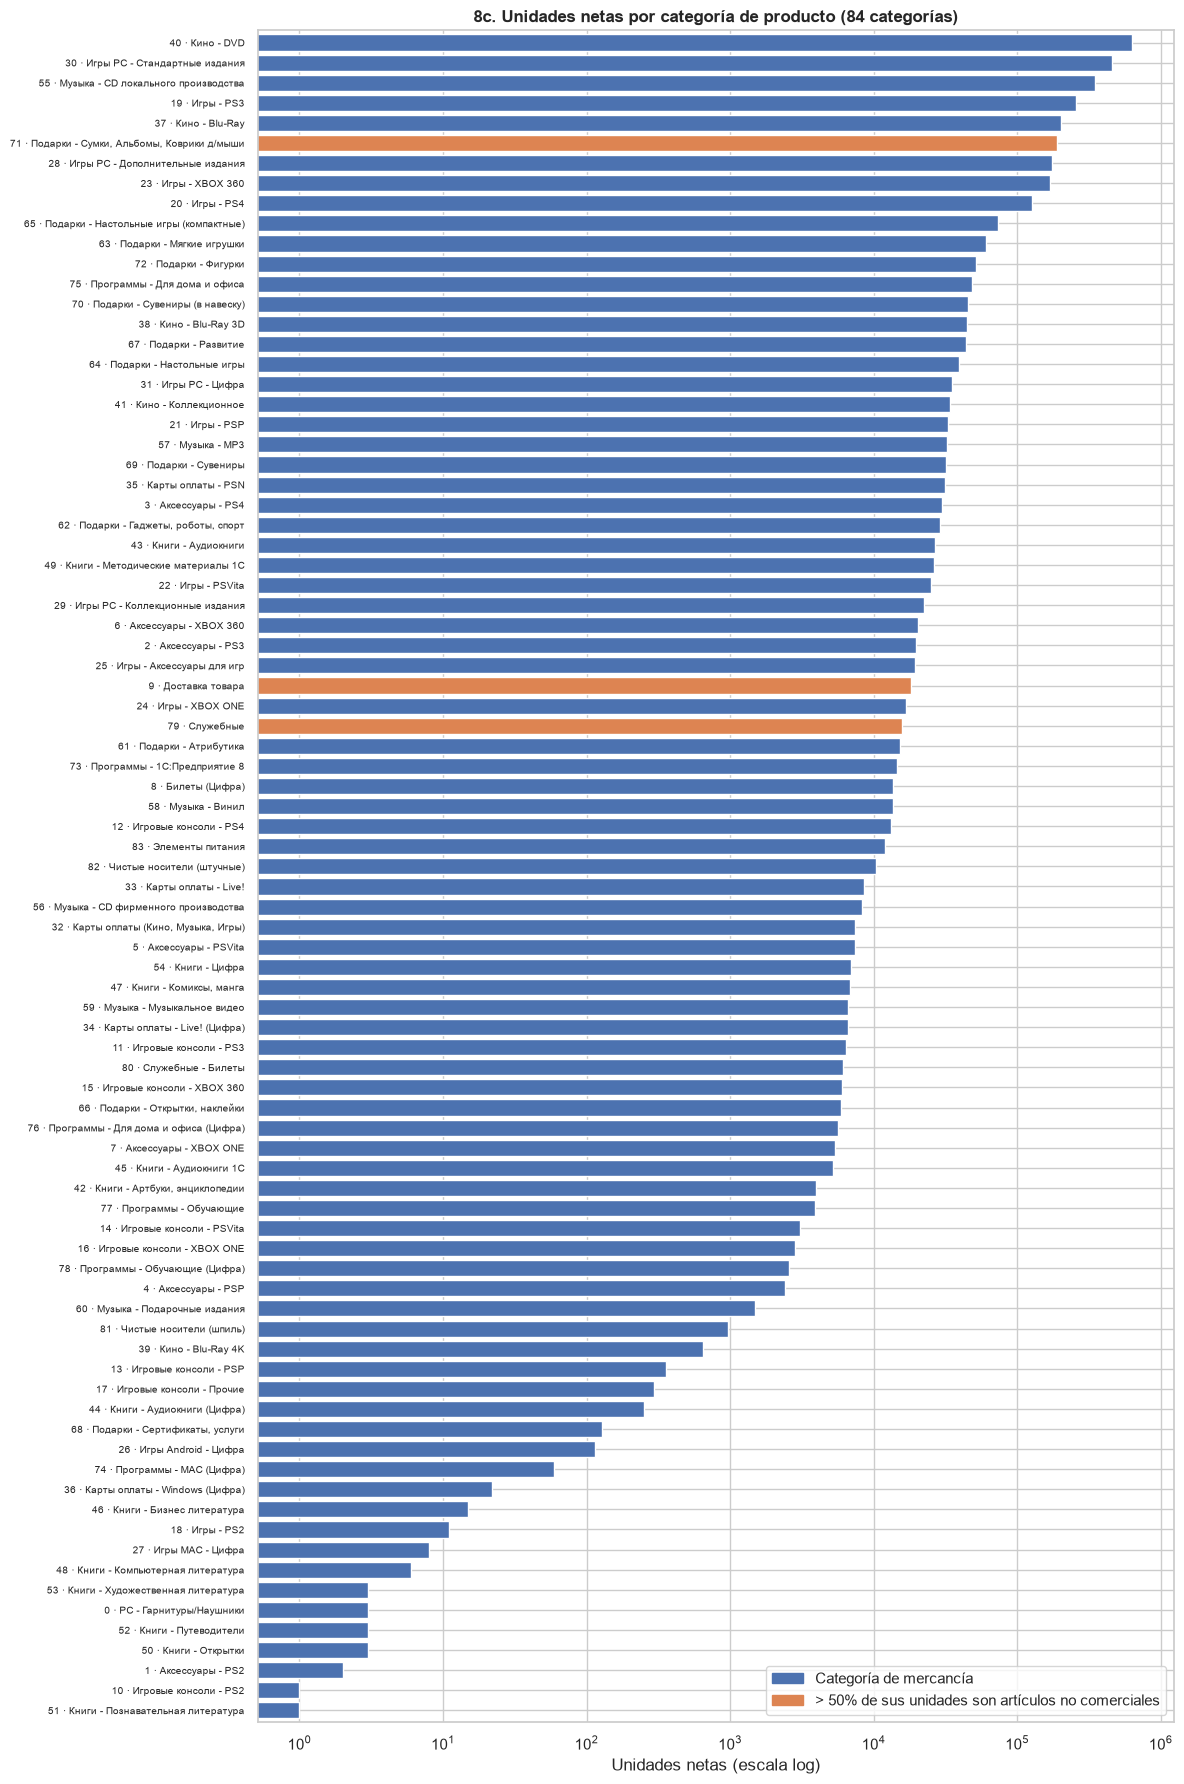

Categorías con unidades netas <= 0 (no graficables en escala log): 0


In [70]:
unid_nc = ventas[ventas["no_comercial"]].groupby("item_category_id")["item_cnt_day"].sum()
share_nc = (unid_nc.reindex(ranking_categorias.index, fill_value=0) / ranking_categorias["unidades"]).fillna(0)
cat_g = ranking_categorias.assign(share_no_comercial=share_nc).sort_values("unidades")
cat_g = cat_g[cat_g["unidades"] > 0]

fig, eje = plt.subplots(figsize=(12, 18))
eje.barh([f"{i} · {recortar(n, 45)}" for i, n in zip(cat_g.index, cat_g["item_category_name"])], cat_g["unidades"],
         color=np.where(cat_g["share_no_comercial"] > 0.5, "#DD8452", "#4C72B0"))
eje.set_xscale("log")
eje.set_xlabel("Unidades netas (escala log)")
eje.tick_params(axis="y", labelsize=7.5)
eje.set_ylim(-0.6, len(cat_g) - 0.4)
eje.legend(handles=[Patch(color="#4C72B0", label="Categoría de mercancía"),
                    Patch(color="#DD8452", label="> 50% de sus unidades son artículos no comerciales")],
           loc="lower right")
eje.set_title("8c. Unidades netas por categoría de producto (84 categorías)")
plt.tight_layout()
plt.show()
print(f"Categorías con unidades netas <= 0 (no graficables en escala log): {(ranking_categorias['unidades'] <= 0).sum()}")

**Interpretación.**

**Artículos no comerciales.** La regla identifica **14 productos** con 221,590 unidades netas: el **6.07 % de las unidades** pero solo el **0.73 % de los ingresos**.

**Top 20 de productos.** Hay **3 artículos no comerciales**:
- la bolsa de la tienda, primera con 187,642 unidades, más de 10 veces el segundo producto;
- la recepción de pagos de 1C-Online (15,830);
- el envío Boxberry (6,563).

Los otros 17 son mercancía: sobre todo videojuegos de PC y consola (Diablo III, GTA V en tres plataformas, Battlefield, FIFA, Call of Duty), tarjetas de pago (PSN, World of Warcraft), la consola PS4 y un antivirus. La escala logarítmica permite comparar los 20 aunque la bolsa los supera ampliamente.

**Categorías.** Las 84 tienen ventas netas positivas y van de 634,170 unidades (`Кино - DVD`) a 1 unidad (`Игровые консоли - PS2`, `Книги - Познавательная литература`), seis órdenes de magnitud.
- **Categorías dominadas por no comerciales (> 50 % de sus unidades):** la 71 (`Подарки - Сумки, Альбомы, Коврики д/мыши`, por la bolsa), la 9 (`Доставка товара`) y la 79 (`Служебные`).
- **Categoría 80 (`Служебные - Билеты`, entradas):** se trata como mercancía, porque son entradas vendidas al público.

La parte alta del ranking la forman los soportes físicos (DVD, CD, Blu-Ray) y los juegos de PC y consola. La cola la forman categorías de plataformas antiguas (PS2, PSP) y algunas de libros.

**Tratamiento.** Los artículos no comerciales se mantienen en todos los totales; solo se señalan. Para el modelado conviene tratarlos aparte, porque su volumen no refleja la demanda de productos.

### 8d. Heatmap de ventas por mes y sucursal / categoría
**Normalización.** Para que el tamaño de las tiendas no oculte los patrones, cada fila se divide por el **promedio mensual de esa misma tienda en sus meses con registros**:
- un valor de 1.0 es un mes "normal" para esa tienda;
- 2.0 es el doble de su promedio;
- 0.5 es la mitad.

La escala de color es divergente y está centrada en 1.0 (azul por debajo, rojo por encima), y se satura en 2.5 para que un par de meses extremos no dominen el color.

**Meses sin registros** (tienda cerrada o aún sin abrir) se muestran en **gris** y no se imputan como cero, para distinguir "sin actividad" de "ventas bajas". Se aplica el mismo procedimiento a los grupos de categoría.

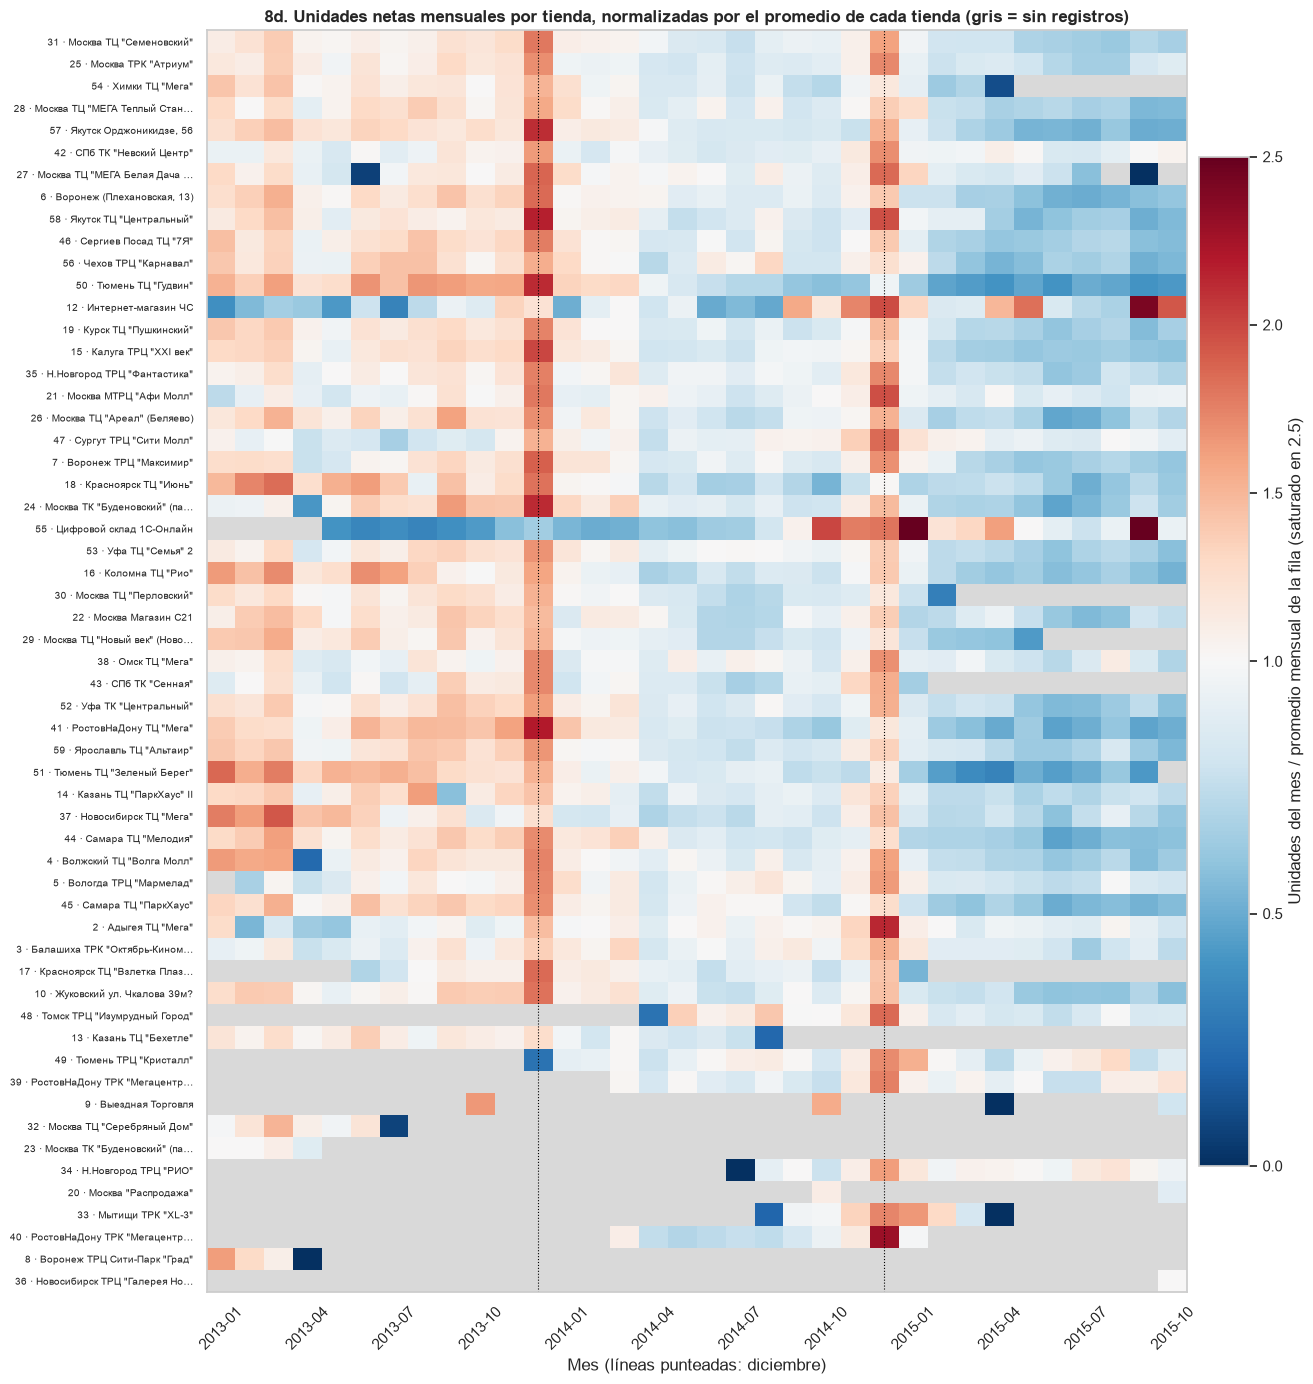

Tiendas activas en ambos diciembres: 45 | de ellas, con valor > 1 en ambos: 42
Mediana del índice normalizado en diciembre 2013: 1.70 | diciembre 2014: 1.52
Mediana del índice en los meses 30-33 (jul-oct 2015): 0.68


In [71]:
def matriz_normalizada(clave: str) -> pd.DataFrame:
    m = ventas.groupby([clave, "date_block_num"])["item_cnt_day"].sum().unstack()  # NaN = mes sin registros
    m = m.reindex(columns=range(34))
    return m.div(m.mean(axis=1), axis=0)


def dibujar_heatmap(matriz: pd.DataFrame, etiquetas, titulo: str, alto: float):
    fig, eje = plt.subplots(figsize=(14, alto))
    eje.set_facecolor("#D9D9D9")  # meses sin registros
    norma = TwoSlopeNorm(vmin=0, vcenter=1, vmax=2.5)
    im = eje.imshow(matriz.clip(upper=2.5).to_numpy(dtype=float), aspect="auto", cmap="RdBu_r", norm=norma,
                    interpolation="nearest")
    eje.set_yticks(range(len(etiquetas)), etiquetas, fontsize=7.5)
    eje.set_xticks(range(0, 34, 3), [f"{2013 + b // 12}-{b % 12 + 1:02d}" for b in range(0, 34, 3)], rotation=45)
    eje.set_xticks(np.arange(-0.5, 34, 1), minor=True)
    eje.grid(False)
    for b in (11, 23):
        eje.axvline(b, color="black", lw=0.8, ls=":")
    barra = fig.colorbar(im, ax=eje, pad=0.01, shrink=0.8)
    barra.set_label("Unidades del mes / promedio mensual de la fila (saturado en 2.5)")
    eje.set_title(titulo)
    eje.set_xlabel("Mes (líneas punteadas: diciembre)")
    plt.tight_layout()
    plt.show()


mat_t = matriz_normalizada("shop_id").loc[desempeno.sort_values("unidades", ascending=False).index]
dibujar_heatmap(mat_t, [f"{i} · {recortar(nombre_tienda_u[i], 28)}" for i in mat_t.index],
                "8d. Unidades netas mensuales por tienda, normalizadas por el promedio de cada tienda "
                "(gris = sin registros)", 14)

dic_cols = [11, 23]
print(f"Tiendas activas en ambos diciembres: {mat_t[dic_cols].notna().all(axis=1).sum()} | "
      f"de ellas, con valor > 1 en ambos: {(mat_t[dic_cols] > 1).all(axis=1).sum()}")
print(f"Mediana del índice normalizado en diciembre 2013: {mat_t[11].median():.2f} | diciembre 2014: {mat_t[23].median():.2f}")
print(f"Mediana del índice en los meses 30-33 (jul-oct 2015): {mat_t[[30, 31, 32, 33]].stack().median():.2f}")

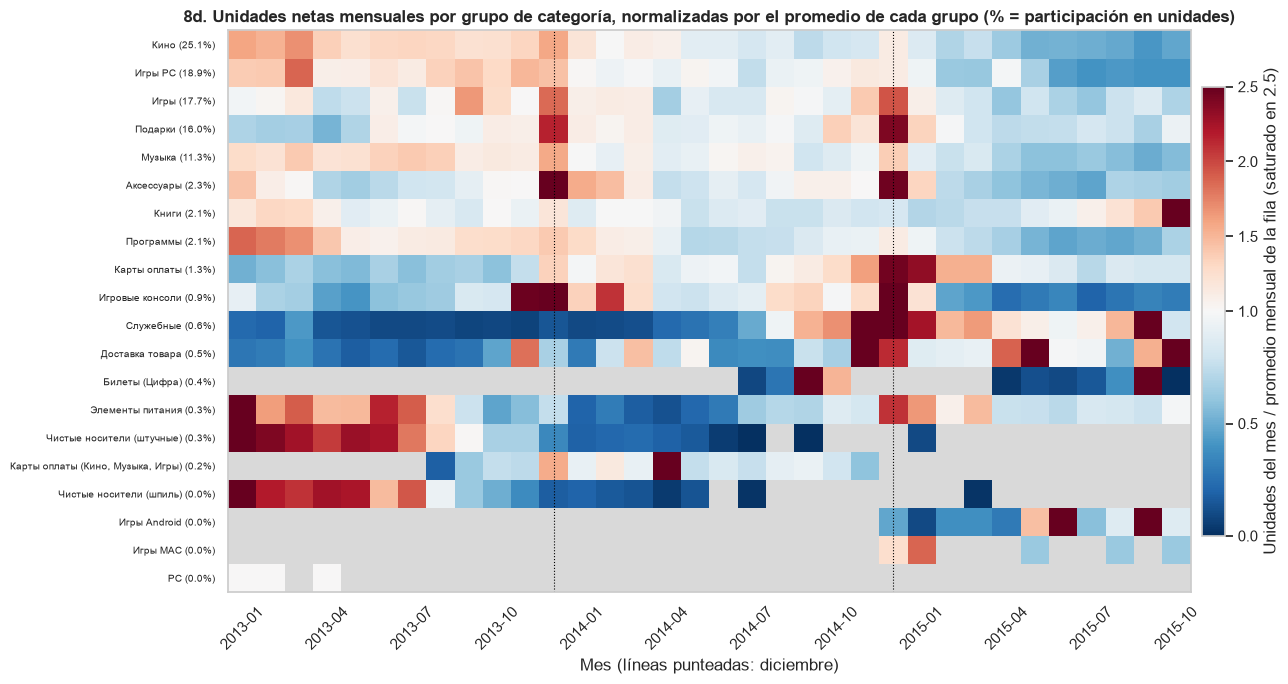

,índice_2013 (meses 0-11),índice_2015 (meses 24-33),meses_con_registros,cambio_relativo,%_unidades
grupo_categoria,,,,,
Кино,1.39,0.59,34,-58%,25.13%
Игры PC,1.35,0.60,34,-56%,18.89%
Игры,1.11,0.78,34,-30%,17.73%
Подарки,0.97,0.86,34,-11%,16.02%
Музыка,1.28,0.67,34,-48%,11.27%
Аксессуары,1.09,0.69,34,-37%,2.33%
Книги,1.05,1.10,34,+5%,2.09%
Программы,1.37,0.63,34,-54%,2.05%
Карты оплаты,0.68,1.13,34,+65%,1.27%


In [72]:
mat_g = matriz_normalizada("grupo_categoria").loc[por_grupo.sort_values("unidades", ascending=False).index]
dibujar_heatmap(mat_g, [f"{g} ({por_grupo.loc[g, '%_unidades']:.1f}%)" for g in mat_g.index],
                "8d. Unidades netas mensuales por grupo de categoría, normalizadas por el promedio de cada grupo "
                "(% = participación en unidades)", 7)

tendencia_grupo = pd.DataFrame(
    {
        "índice_2013 (meses 0-11)": mat_g[list(range(12))].mean(axis=1),
        "índice_2015 (meses 24-33)": mat_g[list(range(24, 34))].mean(axis=1),
        "meses_con_registros": mat_g.notna().sum(axis=1),
    }
)
tendencia_grupo["cambio_relativo"] = tendencia_grupo["índice_2015 (meses 24-33)"] / tendencia_grupo["índice_2013 (meses 0-11)"] - 1
tendencia_grupo.join(por_grupo["%_unidades"]).sort_values("%_unidades", ascending=False).style.format(
    {"índice_2013 (meses 0-11)": "{:.2f}", "índice_2015 (meses 24-33)": "{:.2f}", "cambio_relativo": "{:+.0%}",
     "%_unidades": "{:.2f}%"}, na_rep="—"
)

**Interpretación del heatmap por tienda.**
- **Diciembre es la señal más consistente:** de las 45 tiendas activas en ambos diciembres, **42** venden por encima de su propio promedio en los dos. La mediana del índice es **1.70 en diciembre de 2013** y **1.52 en diciembre de 2014** (columnas rojas sobre las líneas punteadas).
- **La tendencia descendente afecta a casi todas las tiendas:** en 2013 predominan los tonos claros y rojos, y en 2015 los azules. La mediana del índice entre julio y octubre de 2015 es **0.68**: la tienda típica vende un 32 % menos que su propio promedio histórico. La caída es generalizada, no es efecto de unas pocas tiendas.
- **Excepciones:** la tienda online (12) y el almacén digital (55) siguen el patrón opuesto. Están por debajo de su promedio en 2013 y por encima desde finales de 2014, con meses saturados en 2015.
- **Aperturas y cierres:** los bloques grises muestran el ciclo de vida de cada tienda. Por ejemplo, la 54 deja de vender tras abril de 2015, la 36 solo opera en octubre de 2015 y las tiendas 9 y 20 solo operan meses aislados.

**Interpretación del heatmap por grupo de categoría.**
- **Soportes físicos y software tradicional en caída:** su índice medio pasa de 2013 a 2015 así:
  - `Кино` (películas): de 1.39 a 0.59 (−58 %);
  - `Игры PC` (juegos de PC): −56 %;
  - `Программы` (programas): −54 %;
  - `Музыка` (música): −48 %;
  - `Игровые консоли` (consolas): −63 %. Este grupo tiene además un pico saturado en noviembre–diciembre de 2013.
- **Grupos en aumento:** `Карты оплаты` (tarjetas de pago, +65 %), `Служебные` (servicios, de 0.15 a 2.07) y `Доставка товара` (envíos, +288 %), además de `Книги` (libros, +5 %).
- **Lectura:** el patrón es coherente con un desplazamiento hacia productos digitales y el canal online. Los datos muestran la coincidencia temporal, pero no permiten afirmar que una cosa cause la otra.
- **Grupos pequeños (menos del 0.4 % de las unidades):** sus índices son volátiles y tienen muchos meses sin registros, así que se interpretan con cautela.

## 9. Autocorrelación (ACF) y autocorrelación parcial (PACF)

**Metodología común**
- **Frecuencia:** mensual (34 observaciones, ene-2013 a oct-2015) para todas las series, como recomienda el enunciado. Para la serie total también se usa la frecuencia diaria (1,034 observaciones).
- **Rezagos máximos:** 16 en las series mensuales, porque la PACF requiere menos rezagos que la mitad de la muestra (34 / 2 = 17), y 56 en la diaria (8 semanas).
- **Significancia:** bandas de confianza al 95 %. En la ACF se usa la fórmula de Bartlett, que se ensancha con el rezago; en la PACF, ±1.96/√n. Un rezago es "relevante" si su intervalo no contiene el 0. Con 16 rezagos y α = 5 % cabe esperar alrededor de un falso positivo por gráfico, así que **un único rezago aislado apenas por fuera de la banda no se interpreta como patrón**.
- **Tendencia vs. estacionalidad:** una serie con tendencia produce una ACF que decae lentamente y "contamina" todos los rezagos. Por eso, en las series mensuales se calculan también la ACF y la PACF de la **primera diferencia** (cambio mes a mes), que elimina la tendencia lineal. Un rezago 12 significativo en la serie diferenciada es una evidencia más limpia de estacionalidad anual.
- **PACF:** se estima con Yule-Walker (`ywm`), que garantiza valores en [−1, 1] con muestras cortas.
- **Limitación estructural:** con 34 meses solo hay dos ciclos anuales completos y unos 22 pares de observaciones separadas 12 meses. La potencia para detectar estacionalidad anual es baja, y la ausencia de significancia **no** prueba que no exista estacionalidad.

In [73]:
from statsmodels.tsa.stattools import acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

REZAGOS_MES, REZAGOS_DIA = 16, 56


def rezagos_relevantes(x: np.ndarray, nlags: int) -> dict:
    """Rezagos cuyo intervalo de confianza al 95% excluye el 0 (ACF con Bartlett, PACF Yule-Walker)."""
    _, ic_acf = acf(x, nlags=nlags, alpha=0.05, result_object=False)
    _, ic_pacf = pacf(x, nlags=nlags, alpha=0.05, method="ywm")
    sig = lambda ic: [k for k in range(1, nlags + 1) if ic[k, 0] > 0 or ic[k, 1] < 0]
    return {"ACF": sig(ic_acf), "PACF": sig(ic_pacf)}


def resumen_rezagos(nombre: str, serie: pd.Series, nlags: int, diferenciar: bool = True) -> list:
    filas = []
    versiones = [("nivel", serie)] + ([("1ª diferencia", serie.diff().dropna())] if diferenciar else [])
    for version, s in versiones:
        x = s.to_numpy(dtype=float)
        r = rezagos_relevantes(x, nlags)
        valores_acf = acf(x, nlags=nlags, result_object=False)
        filas.append(
            {
                "serie": nombre,
                "versión": version,
                "n": len(x),
                "rezagos": nlags,
                "ACF rezago 1": round(valores_acf[1], 2),
                "ACF rezago 12": round(valores_acf[12], 2) if nlags >= 12 else np.nan,
                "ACF significativos": r["ACF"],
                "PACF significativos": r["PACF"],
            }
        )
    return filas


def graficar_acf_pacf(ejes, x, nlags, titulo):
    plot_acf(x, lags=nlags, ax=ejes[0], title=f"ACF · {titulo}", zero=False, auto_ylims=True)
    plot_pacf(x, lags=nlags, ax=ejes[1], title=f"PACF · {titulo}", zero=False, method="ywm", auto_ylims=True)
    ejes[0].set_ylabel("Autocorrelación")
    ejes[1].set_ylabel("Autocorrelación parcial")
    for e in ejes:
        e.set_xlabel("Rezago (meses o días según la serie)")
        e.title.set_fontsize(10)


resumen_acf = []

### 9a. Aplicación de ACF y PACF
Para cada serie se aplican:
- **i. ACF:** muestra la dependencia entre la serie y sus rezagos.
- **ii. PACF:** ayuda a identificar cuántos términos autorregresivos (AR) incluir.

El orden es: serie total mensual, serie total diaria, sucursales, productos y pares sucursal-producto. Cada bloque incluye su interpretación; la síntesis que responde a las preguntas del inciso 9b está al final de la sección.

#### Serie total mensual (nivel y primera diferencia)

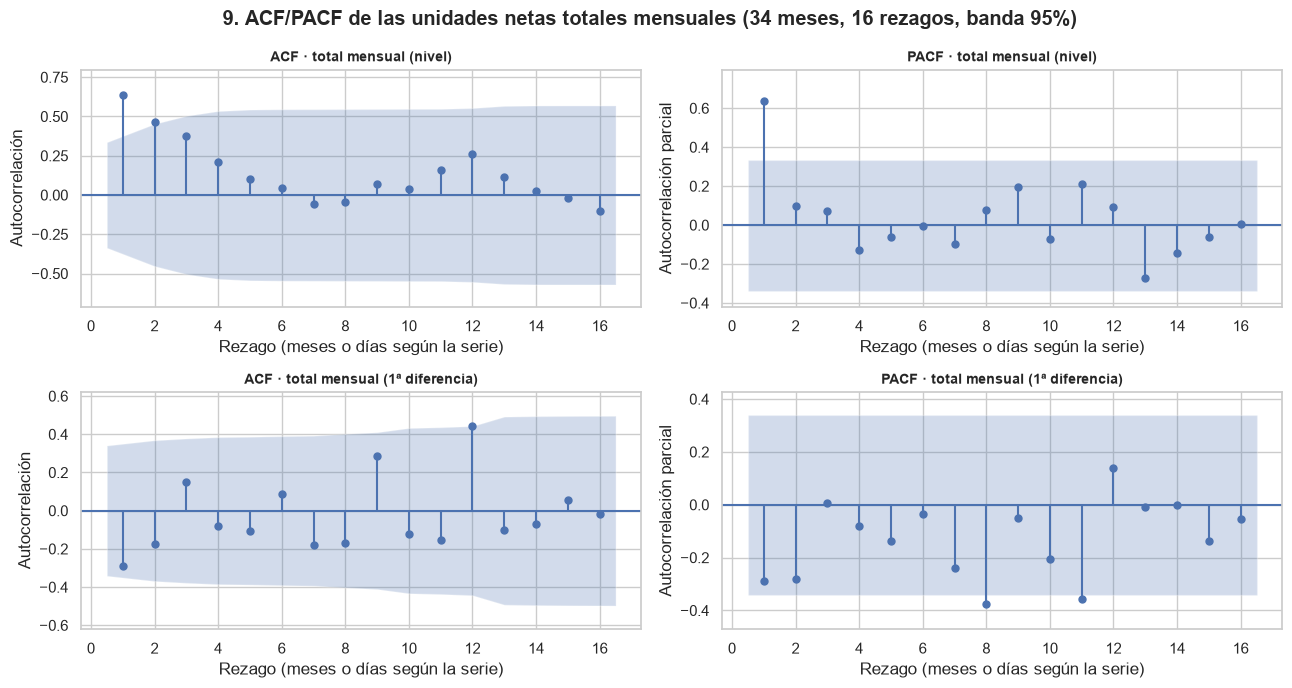

,serie,versión,n,rezagos,ACF rezago 1,ACF rezago 12,ACF significativos,PACF significativos
0,Total mensual,nivel,34,16,0.64,0.26,"[1, 2]",[1]
1,Total mensual,1ª diferencia,33,16,-0.29,0.45,[12],"[8, 11]"


In [74]:
total_mensual = mensual["unidades"].astype(float).set_axis(pd.to_datetime(mensual["mes"]))
fig, ejes = plt.subplots(2, 2, figsize=(13, 7))
graficar_acf_pacf(ejes[0], total_mensual.to_numpy(), REZAGOS_MES, "total mensual (nivel)")
graficar_acf_pacf(ejes[1], total_mensual.diff().dropna().to_numpy(), REZAGOS_MES, "total mensual (1ª diferencia)")
fig.suptitle("9. ACF/PACF de las unidades netas totales mensuales (34 meses, 16 rezagos, banda 95%)", fontweight="bold")
plt.tight_layout()
plt.show()

resumen_acf += resumen_rezagos("Total mensual", total_mensual, REZAGOS_MES)
pd.DataFrame(resumen_acf)

**Interpretación (serie total mensual).**
- **En nivel:** la ACF es alta en el rezago 1 (0.64) y significativa en los rezagos 1 y 2, y luego decae gradualmente. Ese decaimiento lento es el patrón típico de una serie con **tendencia** (la caída sostenida vista en 6 y 8a). La PACF solo es significativa en el rezago 1, una estructura compatible con un proceso autorregresivo de orden 1 sobre el nivel. El rezago 12 en nivel (0.26) **no** es significativo: la tendencia y la amplitud de la banda (unos ±0.55 en rezagos altos) lo ocultan.
- **En primera diferencia:** al quitar la tendencia, el único rezago significativo de la ACF es el **12 (0.45)**. Es la evidencia más clara de **estacionalidad anual**: el cambio mes a mes de un mes se parece al del mismo mes del año anterior (diciembre sube y enero cae en ambos años).
- **PACF de la diferencia:** marca los rezagos 8 y 11, apenas fuera de la banda. Con 16 rezagos evaluados se esperaría alrededor de un falso positivo, y no hay un mecanismo evidente para el rezago 8, así que **no se interpretan como patrón**.
- **Limitación:** la estacionalidad anual se apoya en solo dos ciclos completos (unos 21 pares de meses separados 12 meses en la serie diferenciada).

#### Serie total diaria

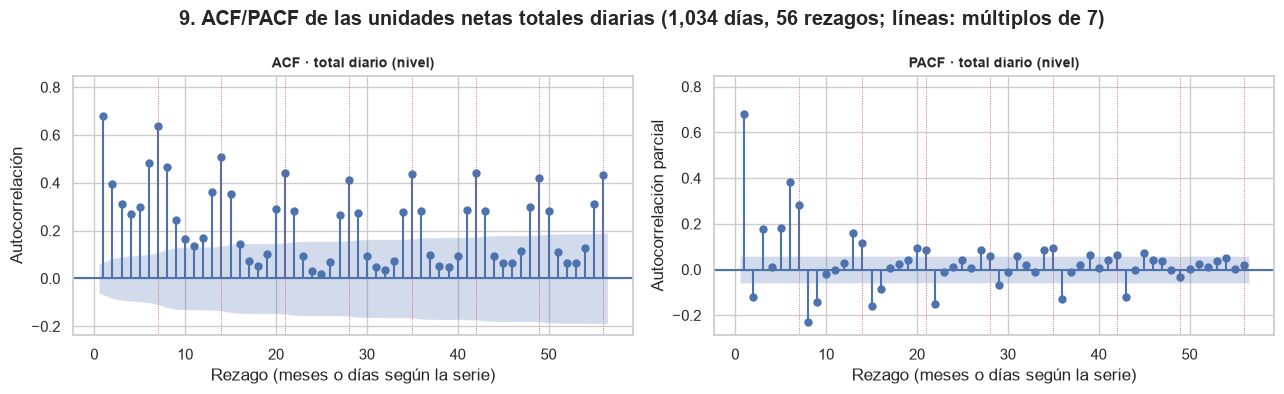

ACF del nivel diario en rezagos 1-14: 1:0.68, 2:0.39, 3:0.31, 4:0.27, 5:0.30, 6:0.48, 7:0.64, 8:0.47, 9:0.25, 10:0.16, 11:0.13, 12:0.17, 13:0.36, 14:0.51
ACF del nivel diario en múltiplos de 7: 7:0.64, 14:0.51, 21:0.44, 28:0.41, 35:0.44, 42:0.44, 49:0.42, 56:0.43
ACF de la 1ª diferencia diaria en múltiplos de 7: 7:0.50, 14:0.47, 21:0.47, 28:0.45, 35:0.50, 42:0.50, 49:0.40, 56:0.43


,n,ACF: rezagos significativos (de 56),ACF: múltiplos de 7 significativos,PACF: rezagos significativos (de 56),PACF: primeros 8 significativos
versión,,,,,
nivel,1034,32,"[7, 14, 21, 28, 35, 42, 49, 56]",25,"[1, 2, 3, 5, 6, 7, 8, 9]"
1ª diferencia,1033,28,"[7, 14, 21, 28, 35, 42, 49, 56]",23,"[2, 3, 4, 5, 6, 7, 8, 12]"


In [75]:
total_diario = diario["unidades"].astype(float)
assert total_diario.index.equals(pd.date_range(total_diario.index.min(), total_diario.index.max(), freq="D"))

fig, ejes = plt.subplots(1, 2, figsize=(13, 4))
graficar_acf_pacf(ejes, total_diario.to_numpy(), REZAGOS_DIA, "total diario (nivel)")
for e in ejes:
    for k in range(7, REZAGOS_DIA + 1, 7):
        e.axvline(k, color="#C44E52", lw=0.6, ls=":")
fig.suptitle("9. ACF/PACF de las unidades netas totales diarias (1,034 días, 56 rezagos; líneas: múltiplos de 7)",
             fontweight="bold")
plt.tight_layout()
plt.show()

filas_d = resumen_rezagos("Total diario", total_diario, REZAGOS_DIA)
valores_d = acf(total_diario.to_numpy(), nlags=REZAGOS_DIA, result_object=False)
print("ACF del nivel diario en rezagos 1-14: " + ", ".join(f"{k}:{valores_d[k]:.2f}" for k in range(1, 15)))
print("ACF del nivel diario en múltiplos de 7: " + ", ".join(f"{k}:{valores_d[k]:.2f}" for k in range(7, 57, 7)))
valores_dd = acf(total_diario.diff().dropna().to_numpy(), nlags=REZAGOS_DIA, result_object=False)
print("ACF de la 1ª diferencia diaria en múltiplos de 7: " + ", ".join(f"{k}:{valores_dd[k]:.2f}" for k in range(7, 57, 7)))
resumen_acf += filas_d

multiplos_7 = list(range(7, REZAGOS_DIA + 1, 7))
pd.DataFrame(
    [
        {
            "versión": f["versión"],
            "n": f["n"],
            "ACF: rezagos significativos (de 56)": len(f["ACF significativos"]),
            "ACF: múltiplos de 7 significativos": [k for k in multiplos_7 if k in f["ACF significativos"]],
            "PACF: rezagos significativos (de 56)": len(f["PACF significativos"]),
            "PACF: primeros 8 significativos": f["PACF significativos"][:8],
        }
        for f in filas_d
    ]
).set_index("versión")

**Interpretación (serie total diaria).**
- **Estacionalidad semanal muy marcada:** la ACF muestra picos en todos los múltiplos de 7 (rezagos 7, 14, …, 56, con valores entre 0.41 y 0.64), y los ocho son significativos. Entre esos picos, los valores bajan (por ejemplo, 0.13–0.17 en los rezagos 10–12).
- **La estacionalidad semanal no es efecto de la tendencia:** después de diferenciar, los ocho múltiplos de 7 siguen siendo significativos (ACF entre 0.40 y 0.50), mientras que el rezago 1 pasa de 0.68 a −0.05. La tendencia explica la persistencia de corto plazo; el ciclo semanal es independiente de ella.
- **PACF:** dominan el rezago 1 (0.68) y los rezagos 6–7, coherente con un componente autorregresivo más un componente estacional semanal.
- **Significancia frente a relevancia práctica:** con n = 1,034 la banda es estrecha (unos ±0.06). Por eso hay 32 rezagos significativos en la ACF y 25 en la PACF, varios con valores pequeños. Solo los rezagos 1 y los múltiplos de 7 tienen una magnitud relevante.

#### Criterios de selección de series individuales

Con 57 tiendas, más de 21,000 productos y más de 400,000 pares tienda-producto, se trabaja con una selección representativa de **3 series por nivel**. Criterios, en orden:

1. **Relevancia para el forecasting:** la serie debe estar en `test.csv` (tienda, producto o par a predecir).
2. **Continuidad del historial:** registros en **los 34 meses**. Así cada serie tiene el máximo de observaciones posible (34) y **no requiere imputar ningún mes**. Esto resuelve el problema de las series dispersas: no se completan datos artificialmente.
3. **Mercancía:** se excluyen los artículos no comerciales de 8c, porque su dinámica (bolsas, envíos, pagos) no representa la demanda de productos.
4. **Representatividad por volumen:** entre los candidatos, ordenados por unidades netas, se toma el de **mayor volumen**, el de **volumen mediano** y el de **menor volumen**, para cubrir series grandes, típicas y pequeñas.

**Meses sin registros vs. meses con ventas cero.** Al construir cada serie se reindexa a los 34 meses y se cuenta cuántos meses **no tienen registros** (que tendrían que imputarse como 0) y cuántos tienen registros pero **ventas netas ≤ 0** (ventas compensadas con devoluciones). Por el criterio 2, el número de meses imputados debe ser 0; se verifica explícitamente.

In [76]:
ids_test_tiendas = set(test["shop_id"])
ids_test_items = set(test["item_id"])
pares_test = set(zip(test["shop_id"], test["item_id"]))
items_no_comerciales = set(ventas.loc[ventas["no_comercial"], "item_id"])

m_tienda = ventas.groupby(["shop_id", "date_block_num"])["item_cnt_day"].sum()
m_item = ventas.groupby(["item_id", "date_block_num"])["item_cnt_day"].sum()
m_par = ventas.groupby(["shop_id", "item_id", "date_block_num"])["item_cnt_day"].sum()


def candidatos(mensual_por_clave: pd.Series, niveles, en_test, excluir=lambda k: False) -> pd.Series:
    meses = mensual_por_clave.groupby(level=niveles).size()
    total = mensual_por_clave.groupby(level=niveles).sum()
    ok = [k for k in meses.index if meses[k] == 34 and en_test(k) and not excluir(k)]
    return total.loc[ok].sort_values(ascending=False)


def elegir(c: pd.Series) -> dict:
    return {"alto": c.index[0], "mediano": c.index[len(c) // 2], "bajo": c.index[-1]}


cand_t = candidatos(m_tienda, "shop_id", lambda k: k in ids_test_tiendas)
cand_i = candidatos(m_item, "item_id", lambda k: k in ids_test_items, lambda k: k in items_no_comerciales)
cand_p = candidatos(m_par, ["shop_id", "item_id"], lambda k: k in pares_test, lambda k: k[1] in items_no_comerciales)

sel_t, sel_i, sel_p = elegir(cand_t), elegir(cand_i), elegir(cand_p)
pd.DataFrame(
    {
        "candidatos (34 meses, en test, mercancía)": [len(cand_t), len(cand_i), len(cand_p)],
        "alto": [sel_t["alto"], sel_i["alto"], sel_p["alto"]],
        "mediano": [sel_t["mediano"], sel_i["mediano"], sel_p["mediano"]],
        "bajo": [sel_t["bajo"], sel_i["bajo"], sel_p["bajo"]],
    },
    index=["tiendas", "productos", "pares tienda-producto"],
)

,"candidatos (34 meses, en test, mercancía)",alto,mediano,bajo
tiendas,35,31,7,10
productos,479,2808,1247,8436
pares tienda-producto,106,"(31, 5822)","(25, 2574)","(31, 1201)"


In [77]:
def construir_serie(mensual_por_clave: pd.Series, clave) -> tuple[pd.Series, dict]:
    s = mensual_por_clave.loc[clave] if not isinstance(clave, tuple) else mensual_por_clave.loc[clave[0], clave[1]]
    meses_sin_registro = 34 - len(s)
    s = s.reindex(range(34), fill_value=0).astype(float)  # 0 solo donde no hay registros (documentado)
    return s, {"meses_sin_registro_imputados_0": meses_sin_registro, "meses_con_ventas_netas_<=0": int((s <= 0).sum())}


def nombre_item(i):
    return recortar(items.set_index("item_id").loc[i, "item_name"], 38)


series_sel = {}
filas_sel = []
for nivel, sel, mpc, etiqueta in [
    ("Tienda", sel_t, m_tienda, lambda k: f"shop {k} · {recortar(nombre_tienda_u[k], 30)}"),
    ("Producto", sel_i, m_item, lambda k: f"item {k} · {nombre_item(k)}"),
    ("Par", sel_p, m_par, lambda k: f"shop {k[0]} × item {k[1]} · {nombre_item(k[1])}"),
]:
    for vol, clave in sel.items():
        s, info = construir_serie(mpc, clave)
        nombre = f"{nivel} ({vol}): {etiqueta(clave)}"
        series_sel[nombre] = s
        filas_sel.append({"serie": nombre, "unidades_totales": s.sum(), "media_mensual": s.mean(),
                          "mín_mensual": s.min(), "máx_mensual": s.max(), **info})

tabla_sel = pd.DataFrame(filas_sel).set_index("serie")
assert (tabla_sel["meses_sin_registro_imputados_0"] == 0).all()
tabla_sel.style.format({"unidades_totales": "{:,.0f}", "media_mensual": "{:,.1f}", "mín_mensual": "{:,.0f}",
                        "máx_mensual": "{:,.0f}"})

,unidades_totales,media_mensual,mín_mensual,máx_mensual,meses_sin_registro_imputados_0,meses_con_ventas_netas_<=0
serie,,,,,,
"Tienda (alto): shop 31 · Москва ТЦ ""Семеновский""","310,777","9,140.5","5,714","16,318",0,0
"Tienda (mediano): shop 7 · Воронеж ТРЦ ""Максимир""","67,058","1,972.3","1,212","3,731",0,0
Tienda (bajo): shop 10 · Жуковский ул. Чкалова 39м?,"25,095",738.1,428,"1,340",0,0
"Producto (alto): item 2808 · Diablo III [PC, Jewel, русская версия]","17,245",507.2,32,"2,727",0,0
Producto (mediano): item 1247 · ADELE 19,427,12.6,4,43,0,0
Producto (bajo): item 8436 · Автоматизация бюджетирования и управл…,128,3.8,1,8,0,0
Par (alto): shop 31 × item 5822 · Playstation Store пополнение бумажник…,"1,293",38.0,14,77,0,0
Par (mediano): shop 25 × item 2574 · DEL REY LANA Born To Die The Paradi…,242,7.1,2,23,0,0
Par (bajo): shop 31 × item 1201 · AC/DC Back In Black,84,2.5,1,5,0,0


#### ACF/PACF por sucursales
Para cada serie: la serie mensual (con diciembres marcados), su ACF y su PACF en nivel. Los rezagos relevantes en nivel y en primera diferencia se resumen en la tabla.

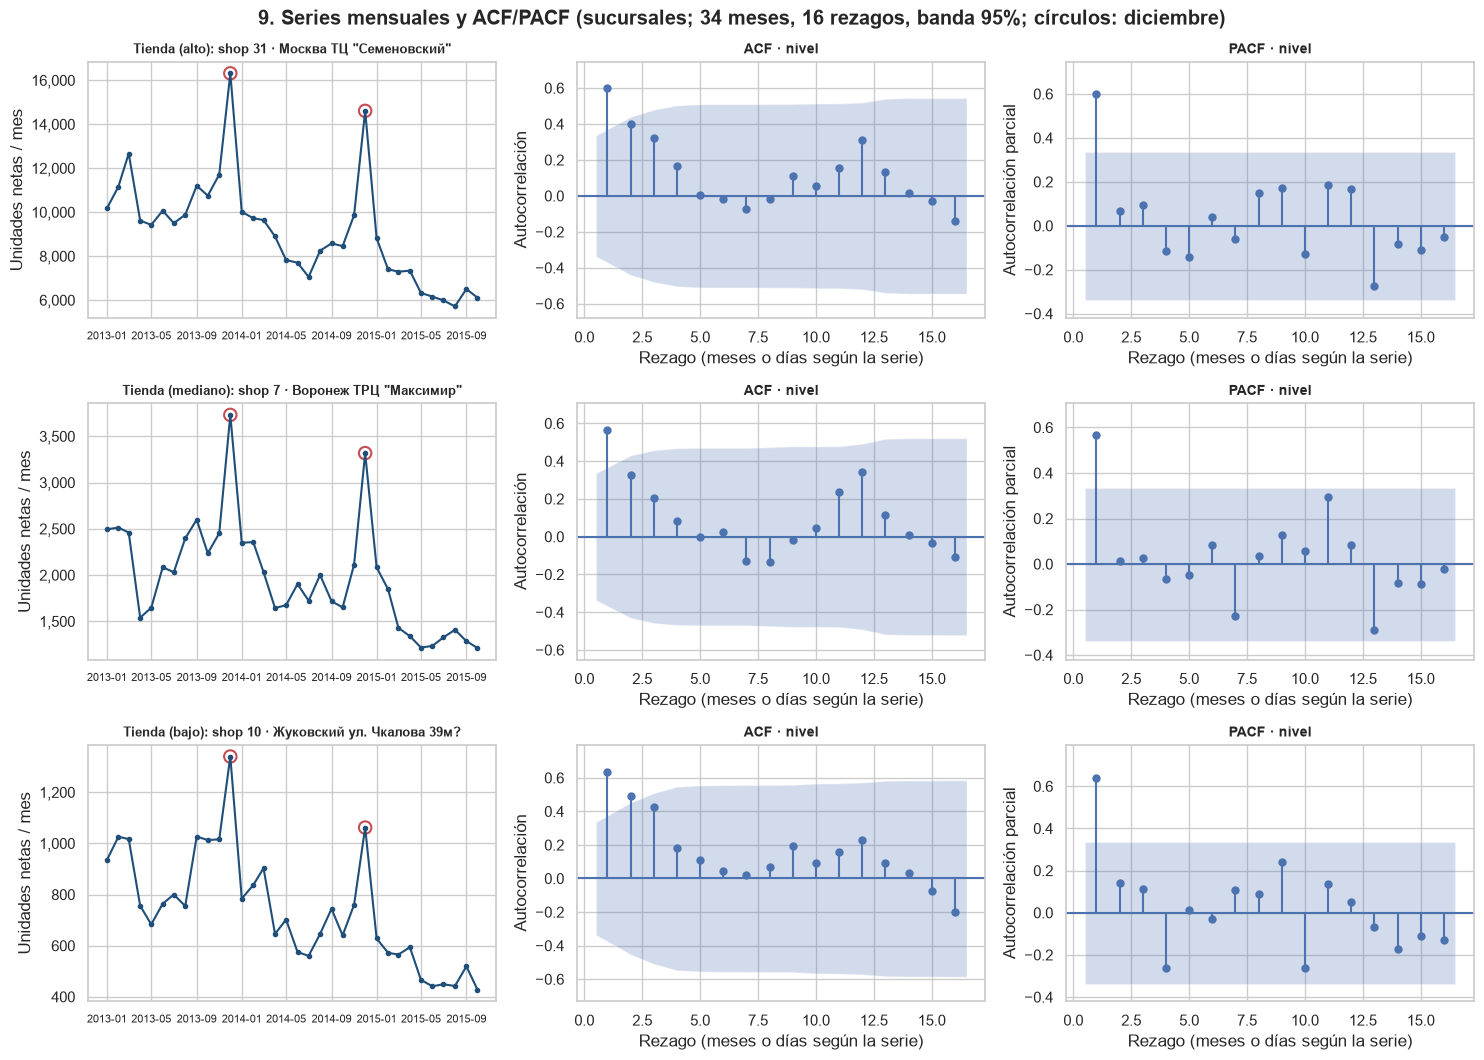

n  rezagos  ACF rezago 1  ACF rezago 12 ACF significativos PACF significativos
serie                                               versión                                                                                       
Tienda (alto): shop 31 · Москва ТЦ "Семеновский"    nivel          34       16          0.60           0.31                [1]                 [1]
                                                    1ª diferencia  33       16         -0.28           0.45               [12]                  []
Tienda (mediano): shop 7 · Воронеж ТРЦ "Максимир"   nivel          34       16          0.57           0.34                [1]                 [1]
                                                    1ª diferencia  33       16         -0.25           0.46               [12]                  []
Tienda (bajo): shop 10 · Жуковский ул. Чкалова 39м? nivel          34       16          0.64           0.23             [1, 2]                 [1]
                                                    1ª diferencia  33       16         -0.34           0.41                 []                 [8]

In [78]:
nombres = [n for n in series_sel if n.startswith("Tienda ")]
fig, ejes = plt.subplots(len(nombres), 3, figsize=(15, 3.6 * len(nombres)))
fechas_34 = pd.period_range("2013-01", periods=34, freq="M").to_timestamp()
filas_nivel = []
for fila, nombre in zip(ejes, nombres):
    s = series_sel[nombre]
    fila[0].plot(fechas_34, s.values, marker="o", ms=3, color="#1F4E79")
    fila[0].scatter(fechas_34[11::12], s.values[11::12], s=80, facecolors="none", edgecolors="#C44E52", lw=1.5)
    fila[0].set_title(recortar(nombre, 60), fontsize=9.5)
    fila[0].set_ylabel("Unidades netas / mes")
    fila[0].yaxis.set_major_formatter(miles)
    fila[0].tick_params(axis="x", labelsize=8)
    graficar_acf_pacf(fila[1:], s.to_numpy(), REZAGOS_MES, "nivel")
    filas_nivel += resumen_rezagos(nombre, s, REZAGOS_MES)
fig.suptitle("9. Series mensuales y ACF/PACF (sucursales; 34 meses, 16 rezagos, banda 95%; círculos: diciembre)",
             fontweight="bold")
plt.tight_layout()
plt.show()
resumen_acf += filas_nivel
pd.DataFrame(filas_nivel).set_index(["serie", "versión"])

**Interpretación (sucursales: alta 31, mediana 7 y baja 10).**
- **Las tres series reproducen el patrón de la serie total:** tendencia descendente y picos en ambos diciembres (círculos rojos), con independencia del tamaño de la tienda.
- **En nivel:** la ACF del rezago 1 es significativa en las tres (0.60, 0.57 y 0.64; en la tienda 10 también el rezago 2), con decaimiento gradual por la tendencia. La PACF solo es significativa en el rezago 1.
- **En primera diferencia:** el **rezago 12 es significativo en las tiendas 31 (0.45) y 7 (0.46)**, la misma estacionalidad anual que en la serie total. En la tienda 10 el rezago 12 de la diferencia (0.41) queda dentro de la banda. Su serie es más ruidosa (menor volumen), lo que reduce la potencia de la prueba, pero la serie muestra visualmente los mismos picos de diciembre. Un resultado no significativo **no** prueba que no haya estacionalidad. La PACF de su diferencia marca un rezago 8 aislado, que no se interpreta.
- **Continuidad:** las tres tiendas tienen registros en los 34 meses, así que no hubo imputación. En la tienda 10 la continuidad depende de la unificación 11→10 aprobada en la sección 4.

#### ACF/PACF por productos
Para cada serie: la serie mensual (con diciembres marcados), su ACF y su PACF en nivel. Los rezagos relevantes en nivel y en primera diferencia se resumen en la tabla.

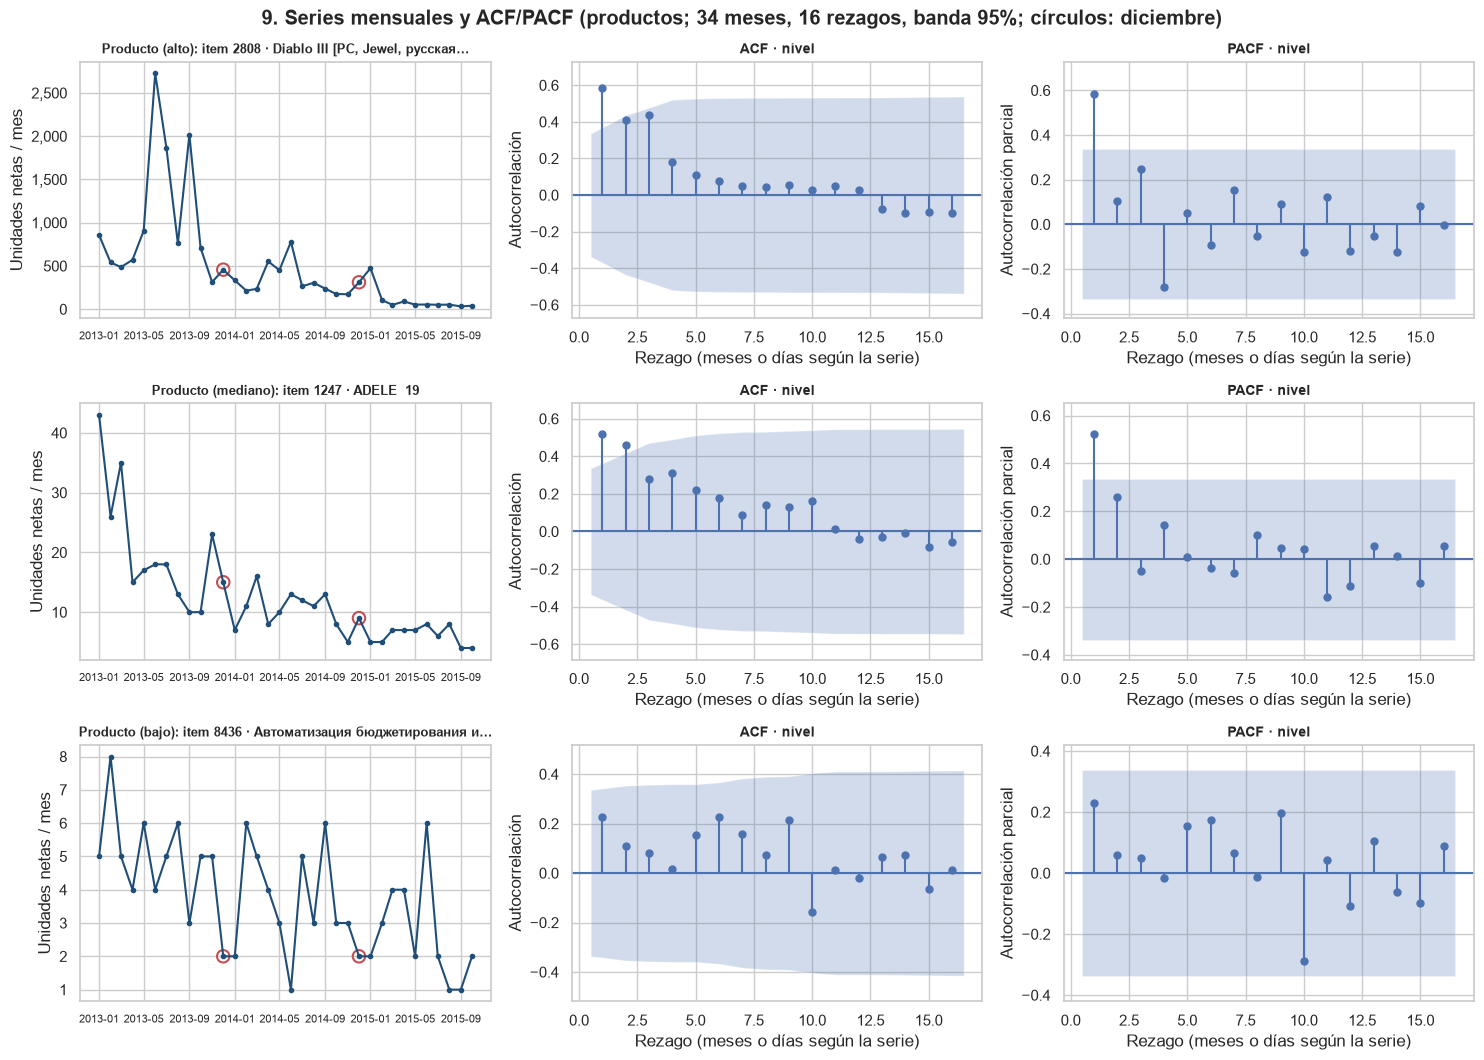

n  rezagos  ACF rezago 1  ACF rezago 12 ACF significativos PACF significativos
serie                                                               versión                                                                                       
Producto (alto): item 2808 · Diablo III [PC, Jewel, русская версия] nivel          34       16          0.58           0.03                [1]                 [1]
                                                                    1ª diferencia  33       16         -0.29           0.11                 []                 [2]
Producto (mediano): item 1247 · ADELE  19                           nivel          34       16          0.52          -0.04             [1, 2]                 [1]
                                                                    1ª diferencia  33       16         -0.41           0.07                [1]                 [1]
Producto (bajo): item 8436 · Автоматизация бюджетирования и управл… nivel          34       16          0.23          -0.02                 []                  []
                                                                    1ª diferencia  33       16         -0.48          -0.08                [1]           [1, 2, 5]

In [79]:
nombres = [n for n in series_sel if n.startswith("Producto ")]
fig, ejes = plt.subplots(len(nombres), 3, figsize=(15, 3.6 * len(nombres)))
fechas_34 = pd.period_range("2013-01", periods=34, freq="M").to_timestamp()
filas_nivel = []
for fila, nombre in zip(ejes, nombres):
    s = series_sel[nombre]
    fila[0].plot(fechas_34, s.values, marker="o", ms=3, color="#1F4E79")
    fila[0].scatter(fechas_34[11::12], s.values[11::12], s=80, facecolors="none", edgecolors="#C44E52", lw=1.5)
    fila[0].set_title(recortar(nombre, 60), fontsize=9.5)
    fila[0].set_ylabel("Unidades netas / mes")
    fila[0].yaxis.set_major_formatter(miles)
    fila[0].tick_params(axis="x", labelsize=8)
    graficar_acf_pacf(fila[1:], s.to_numpy(), REZAGOS_MES, "nivel")
    filas_nivel += resumen_rezagos(nombre, s, REZAGOS_MES)
fig.suptitle("9. Series mensuales y ACF/PACF (productos; 34 meses, 16 rezagos, banda 95%; círculos: diciembre)",
             fontweight="bold")
plt.tight_layout()
plt.show()
resumen_acf += filas_nivel
pd.DataFrame(filas_nivel).set_index(["serie", "versión"])

**Interpretación (productos: alto Diablo III [PC], mediano ADELE `19` y bajo un manual de 1C).**
- **Diablo III (17,245 unidades):** tiene un pico de 2,727 unidades a mitad de 2013 y luego decae hasta unas decenas al mes en 2015. Es un **ciclo de vida de producto**: lanzamiento o auge seguido de agotamiento. En nivel, la ACF del rezago 1 (0.58) es significativa y luego decae; la PACF solo marca el rezago 1. **No hay estacionalidad anual** (ACF del rezago 12 = 0.03), y el diciembre de cada año no destaca: la dinámica del ciclo de vida domina sobre la estacionalidad de la cadena.
- **ADELE `19` (427 unidades, 4–43 al mes):** desciende de forma gradual. La ACF es significativa en los rezagos 1 y 2 y la PACF en el 1; no hay señal en el rezago 12 (−0.04).
- **Manual de 1C (128 unidades, 1–8 al mes):** **ningún rezago es significativo en nivel**. La serie se comporta como ruido alrededor de una media baja.
- **Cautela con las diferencias de series ruidosas:** en las dos series de menor volumen, la ACF del rezago 1 de la primera diferencia es significativa y negativa (−0.41 y −0.48). Diferenciar una serie sin tendencia produce de forma mecánica una autocorrelación cercana a −0.5 en el rezago 1. Es un **efecto de la transformación**, no un patrón de la demanda.

#### ACF/PACF por pares sucursal-producto
Para cada serie: la serie mensual (con diciembres marcados), su ACF y su PACF en nivel. Los rezagos relevantes en nivel y en primera diferencia se resumen en la tabla.

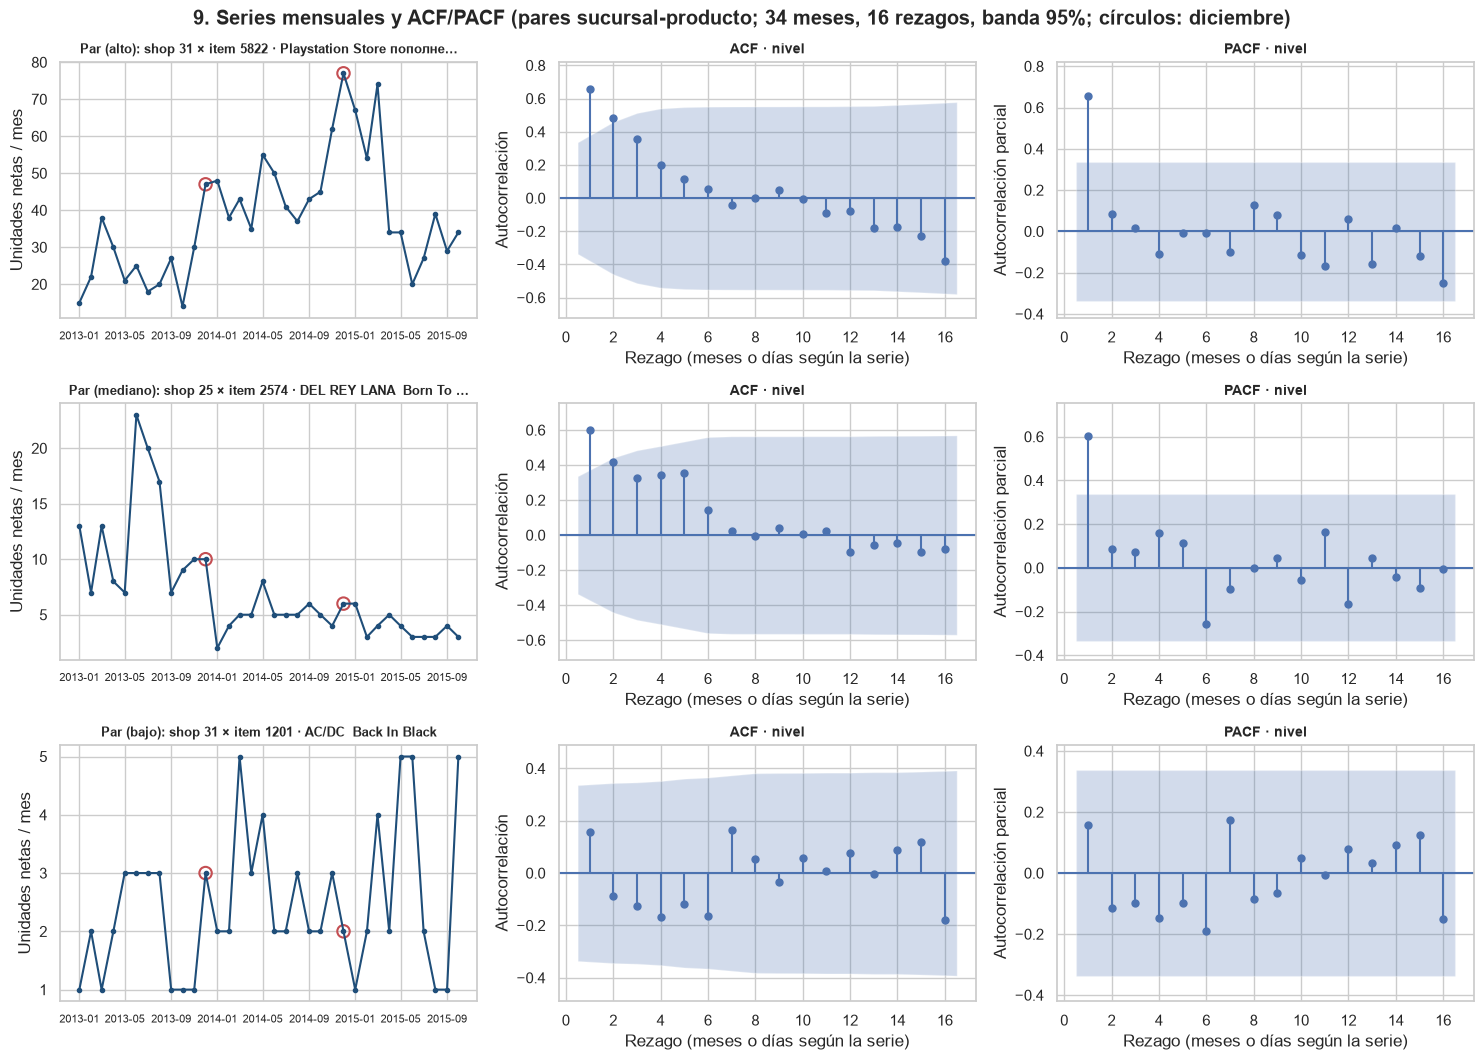

n  rezagos  ACF rezago 1  ACF rezago 12 ACF significativos PACF significativos
serie                                                                       versión                                                                                       
Par (alto): shop 31 × item 5822 · Playstation Store пополнение бумажник…    nivel          34       16          0.66          -0.08             [1, 2]                 [1]
                                                                            1ª diferencia  33       16         -0.24           0.17                 []                  []
Par (mediano): shop 25 × item 2574 · DEL REY LANA  Born To Die  The Paradi… nivel          34       16          0.60          -0.10                [1]                 [1]
                                                                            1ª diferencia  33       16         -0.23          -0.13                 []                  []
Par (bajo): shop 31 × item 1201 · AC/DC  Back In Black                      nivel          34       16          0.16           0.08                 []                  []
                                                                            1ª diferencia  33       16         -0.25           0.11                 []                  []

In [80]:
nombres = [n for n in series_sel if n.startswith("Par ")]
fig, ejes = plt.subplots(len(nombres), 3, figsize=(15, 3.6 * len(nombres)))
fechas_34 = pd.period_range("2013-01", periods=34, freq="M").to_timestamp()
filas_nivel = []
for fila, nombre in zip(ejes, nombres):
    s = series_sel[nombre]
    fila[0].plot(fechas_34, s.values, marker="o", ms=3, color="#1F4E79")
    fila[0].scatter(fechas_34[11::12], s.values[11::12], s=80, facecolors="none", edgecolors="#C44E52", lw=1.5)
    fila[0].set_title(recortar(nombre, 60), fontsize=9.5)
    fila[0].set_ylabel("Unidades netas / mes")
    fila[0].yaxis.set_major_formatter(miles)
    fila[0].tick_params(axis="x", labelsize=8)
    graficar_acf_pacf(fila[1:], s.to_numpy(), REZAGOS_MES, "nivel")
    filas_nivel += resumen_rezagos(nombre, s, REZAGOS_MES)
fig.suptitle("9. Series mensuales y ACF/PACF (pares sucursal-producto; 34 meses, 16 rezagos, banda 95%; círculos: diciembre)",
             fontweight="bold")
plt.tight_layout()
plt.show()
resumen_acf += filas_nivel
pd.DataFrame(filas_nivel).set_index(["serie", "versión"])

**Interpretación (pares: alto shop 31 × tarjeta PSN, mediano shop 25 × Lana Del Rey y bajo shop 31 × AC/DC).**
- **Shop 31 × tarjeta PSN (1,293 unidades, 14–77 al mes):** crece hasta un máximo en diciembre de 2014 y luego baja. La ACF es significativa en los rezagos 1 y 2 y la PACF en el 1; no hay estacionalidad (rezago 12 = −0.08). El pico de diciembre aparece en 2014 pero no en 2013, así que no se repite.
- **Shop 25 × Lana Del Rey (242 unidades, 2–23 al mes):** tiene un pico a mitad de 2013 y después un nivel bajo y estable. Solo el rezago 1 es significativo, tanto en ACF como en PACF; no hay estacionalidad.
- **Shop 31 × AC/DC (84 unidades, 1–5 al mes):** **ningún rezago es significativo**, ni en nivel ni en diferencia. Con conteos tan bajos, la serie es indistinguible del ruido.
- **Diferencias:** en ninguno de los tres pares la primera diferencia muestra rezagos significativos.
- **Conclusión del nivel tienda-producto:** la autocorrelación se limita a la persistencia de corto plazo (rezago 1) en las series de mayor volumen. La estacionalidad anual de la cadena **no es detectable** a este nivel con 34 meses.

#### Resumen de rezagos relevantes (todas las series)

In [81]:
resumen_9 = pd.DataFrame(resumen_acf)
resumen_9["rezago_12_en_ACF"] = resumen_9["ACF significativos"].apply(lambda l: 12 in l)
resumen_9["rezago_1_en_PACF"] = resumen_9["PACF significativos"].apply(lambda l: 1 in l)
resumen_9.set_index(["serie", "versión"])

n  rezagos  ACF rezago 1  ACF rezago 12  \
serie                                                                       versión                                                     
Total mensual                                                               nivel            34       16          0.64           0.26   
                                                                            1ª diferencia    33       16         -0.29           0.45   
Total diario                                                                nivel          1034       56          0.68           0.17   
                                                                            1ª diferencia  1033       56         -0.05          -0.24   
Tienda (alto): shop 31 · Москва ТЦ "Семеновский"                            nivel            34       16          0.60           0.31   
                                                                            1ª diferencia    33       16         -0.28           0.45   
Tienda (mediano): shop 7 · Воронеж ТРЦ "Максимир"                           nivel            34       16          0.57           0.34   
                                                                            1ª diferencia    33       16         -0.25           0.46   
Tienda (bajo): shop 10 · Жуковский ул. Чкалова 39м?                         nivel            34       16          0.64           0.23   
                                                                            1ª diferencia    33       16         -0.34           0.41   
Producto (alto): item 2808 · Diablo III [PC, Jewel, русская версия]         nivel            34       16          0.58           0.03   
                                                                            1ª diferencia    33       16         -0.29           0.11   
Producto (mediano): item 1247 · ADELE  19                                   nivel            34       16          0.52          -0.04   
                                                                            1ª diferencia    33       16         -0.41           0.07   
Producto (bajo): item 8436 · Автоматизация бюджетирования и управл…         nivel            34       16          0.23          -0.02   
                                                                            1ª diferencia    33       16         -0.48          -0.08   
Par (alto): shop 31 × item 5822 · Playstation Store пополнение бумажник…    nivel            34       16          0.66          -0.08   
                                                                            1ª diferencia    33       16         -0.24           0.17   
Par (mediano): shop 25 × item 2574 · DEL REY LANA  Born To Die  The Paradi… nivel            34       16          0.60          -0.10   
                                                                            1ª diferencia    33       16         -0.23          -0.13   
Par (bajo): shop 31 × item 1201 · AC/DC  Back In Black                      nivel            34       16          0.16           0.08   
                                                                            1ª diferencia    33       16         -0.25           0.11   

                                                                                                                                                        ACF significativos  \
serie                                                                       versión                                                                                          
Total mensual                                                               nivel                                                                                   [1, 2]   
                                                                            1ª diferencia                                                                             [12]   
Total diario                                                                nivel          [1, 2, 3, 4, 5, 6,

### 9b. Interpretación general

**i. ¿Existen correlaciones significativas a diferentes rezagos?**
- **Rezago 1 (persistencia de corto plazo):** es significativo en nivel en **9 de las 11 series** analizadas. Las dos excepciones son las de menor volumen (el manual de 1C y el par AC/DC), que se comportan como ruido. En la PACF, el corte tras el rezago 1 es el patrón dominante, compatible con una dinámica autorregresiva de orden 1.
- **Origen de esa persistencia:** en las series agregadas (total y tiendas) se debe en buena parte a la **tendencia descendente**. Al diferenciar, el rezago 1 deja de ser significativo.
- **Serie diaria:** son significativos el rezago 1 y todos los **múltiplos de 7**.

**ii. ¿Se observa estacionalidad reflejada en patrones repetitivos?**
- **Semanal:** sí, de forma muy clara en la serie diaria (múltiplos de 7 significativos con y sin diferenciar).
- **Anual (rezago 12):** se detecta **solo después de quitar la tendencia** y solo en las series agregadas: el total (0.45) y las tiendas 31 y 7 (0.45 y 0.46). En la tienda pequeña no alcanza significancia, aunque los picos de diciembre se ven en la serie.
- **Productos y pares:** **no se detecta estacionalidad anual**. En los productos domina el ciclo de vida (lanzamiento y declive), y en los pares los conteos son bajos y ruidosos.

**Implicación descriptiva para el forecasting** (las conclusiones finales quedan para la sección 10):
- En niveles agregados son informativos el rezago 1 y el 12, siempre que se controle la tendencia.
- En el nivel tienda-producto, que es el que pide `test.csv`, la información útil está sobre todo en el historial reciente.

**Limitaciones**
1. **Solo 34 meses:** hay dos ciclos anuales completos, las bandas de confianza son anchas (PACF ±0.34; ACF con Bartlett de hasta ±0.55) y la potencia para detectar el rezago 12 es baja.
2. **Comparaciones múltiples:** con 16 rezagos por gráfico, un rezago aislado apenas fuera de la banda puede ser un falso positivo. Por eso no se interpretaron los rezagos 8 y 11 de la serie total diferenciada ni el rezago 8 de la tienda 10.
3. **No estacionariedad:** las series en nivel tienen tendencia, lo que infla la ACF. Por eso se presentan también diferenciadas. A su vez, diferenciar series sin tendencia induce un rezago 1 negativo artificial.
4. **Sesgo de selección:** solo se eligieron series con los 34 meses completos para evitar imputaciones. Ese criterio favorece productos y pares **de vida larga** (solo 479 de 21,807 productos y 106 pares de `test` lo cumplen). Los productos nuevos o de vida corta, que son la mayoría, pueden comportarse de forma distinta.
5. **Representatividad limitada:** 3 series por nivel ilustran patrones típicos, pero no representan estadísticamente a los más de 400,000 pares.
6. **Sin causalidad:** la autocorrelación describe dependencia temporal; no explica por qué ocurre.

## 10. Insights y conclusiones del EDA

Esta sección sintetiza los resultados de las secciones 2 a 9. Las cifras citadas provienen de las salidas ejecutadas de este notebook. El único cálculo nuevo es la cobertura de `test.csv` (10b), que pide expresamente el enunciado.

### 10a. Variables que afectan directamente las ventas

El EDA es descriptivo: identifica **variables asociadas** al volumen de ventas, no efectos causales. La columna "Tipo de evidencia" distingue lo que se observa directamente en los datos de lo que solo puede plantearse como hipótesis.

| Variable | Evidencia cuantitativa (sección) | Tipo de evidencia |
|---|---|---|
| **Producto (`item_id`)** | Es la dimensión más concentrada: el 1 % de los productos genera el 28.15 % de las unidades y el 44.83 % de los ingresos, mientras que el producto mediano vende solo 33 unidades en todo el histórico (5b-i). 2,319 productos vendieron 1 unidad y 2,999 solo se vendieron en un mes (5b-i). | Observada. El producto determina el volumen, pero los datos no explican por qué un producto vende más que otro. |
| **Ciclo de vida del producto** | Diablo III pasa de 2,727 unidades en su mejor mes a unas decenas por mes en 2015 (9). Los productos activos por mes bajan de 7,876–8,478 en 2013 a 5,085–5,476 en abril–octubre de 2015 (5b-iii). Los picos diarios del 14.04.2015 y el 19.05.2015 se concentran en un solo título nuevo (53.4 % y 23.6 % de las unidades del día) (6b-iii). | Observada. Que los picos correspondan a lanzamientos es una hipótesis: el dataset no trae fechas de lanzamiento. |
| **Categoría** | Las 4 categorías principales suman el 46.4 % de las unidades (5b-i). Unidades e ingresos divergen por categoría: `Кино` (películas) aporta el 25.13 % de las unidades y el 9.86 % de los ingresos; las consolas, el 0.88 % y el 15.54 % (5b-i). Entre 2013 y 2015 cambian de forma opuesta: películas −58 %, juegos de PC −56 % y tarjetas de pago +65 % (8d). | Observada. La sustitución entre canales físicos y digitales es una hipótesis compatible con los datos, no demostrada. |
| **Tienda (`shop_id`)** | La tienda con más unidades por mes activo vende 28 veces más que la de menos (7b), y 13 de 57 tiendas suman el 50 % de las unidades (8b). La tendencia descendente afecta a casi todas las tiendas (índice mediano de 0.68 en jul–oct 2015), con la excepción de la tienda online (12) y el almacén digital (55) (8d). | Observada. Las diferencias entre tiendas pueden reflejar ubicación, tamaño o canal, que el dataset no describe. |
| **Precio (`item_price`)** | El ingreso medio por unidad sube de 779.10 (2013) a 1,091.60 (2015) mientras las unidades caen, y los ingresos no muestran una tendencia significativa (p = 0.90) (5b-iii, 6b-i). Entre tiendas, la relación entre volumen e ingreso por unidad es débil (Spearman = −0.18) (7b). Las categorías de mayor precio (consolas, 16,421 por unidad) venden pocas unidades (5b-i). El mismo producto se vende a precios muy distintos: 13,571 registros (3,921 + 9,650) a más de 5 veces o menos de 0.2 veces su mediana, y 4,657 a menos de 1 rublo (7c). | Asociación. No se estimó elasticidad ni se controló por producto, así que el EDA **no** permite afirmar que el precio cause cambios en las unidades. Los precios simbólicos sugieren promociones, sin confirmación. |
| **Tiempo: tendencia** | −1,943.52 unidades por mes (p < 0.01, R² = 0.46). La tendencia baja un −31.3 % y la variación interanual de enero–octubre es de −17.22 % y −26.08 % (6b-i, 5b-iii). | Observada. La causa de la caída no puede identificarse con este dataset. |
| **Tiempo: estacionalidad anual** | Diciembre es el pico en ambos años (índices 140.8 y 153.3), y 42 de 45 tiendas superan su promedio en ambos diciembres (6b-ii, 8d). Hay un rezago 12 significativo en la serie total diferenciada (0.45) (9). | Observada en dos ciclos. Su magnitud futura es incierta. |
| **Tiempo: día de la semana** | Sábado con índice 140.7 y lunes con 77.4 (6b-iv). La ACF diaria es significativa en todos los múltiplos de 7, incluso después de diferenciar (9). | Observada y robusta (1,034 días). |
| **Canal (online / digital)** | En la tienda online (12) el 30.75 % de sus unidades proviene de registros de cantidad extrema, y en el almacén digital (55) el 18.84 %, frente a un 3.6–5.9 % en las tiendas físicas con más casos (7c). | Observada. El canal no es una variable del dataset: se infiere del nombre de la tienda. |

### 10b. Patrones útiles para el modelo de forecasting

#### Cobertura de `test.csv`: pares tienda-producto con historial en el train
**Procedimiento:**
- Se toman las combinaciones **únicas** de `shop_id` e `item_id` de `test.csv` (sin modificarlo) y de los datos de venta.
- Se cruzan con un `merge` validado como **uno a uno** (`validate="one_to_one"`), y se comprueba que el número de filas no cambia, para descartar duplicaciones.
- Se calculan dos escenarios:
  - **Historial original:** `sales`, con los `shop_id` tal como vienen en `sales_train.csv`.
  - **Historial con tiendas unificadas:** `sales_clean`, con 0→57, 1→58 y 11→10. Es el **resultado principal**.

In [82]:
test_original = pd.read_csv(RAW_DIR / "test.csv")
assert test.equals(test_original), "test.csv fue modificado en memoria"

pares_test_u = test[["shop_id", "item_id"]].drop_duplicates()
print(f"Filas de test.csv: {len(test):,} | pares únicos tienda-producto: {len(pares_test_u):,}")


def cobertura(historial: pd.DataFrame, nombre: str) -> dict:
    pares_hist = historial[["shop_id", "item_id"]].drop_duplicates()
    cruce = pares_test_u.merge(pares_hist, on=["shop_id", "item_id"], how="left", indicator=True,
                               validate="one_to_one")
    assert len(cruce) == len(pares_test_u), "El cruce duplicó filas"
    con_historial = int((cruce["_merge"] == "both").sum())
    return {
        "escenario": nombre,
        "pares de test con historial (numerador)": con_historial,
        "pares únicos de test (denominador)": len(pares_test_u),
        "% con historial": 100 * con_historial / len(pares_test_u),
    }


tabla_cobertura = pd.DataFrame(
    [
        cobertura(sales, "Historial original (shop_id sin unificar)"),
        cobertura(sales_clean, "Historial con tiendas unificadas (principal)"),
    ]
).set_index("escenario")
tabla_cobertura.style.format({"pares de test con historial (numerador)": "{:,}",
                              "pares únicos de test (denominador)": "{:,}", "% con historial": "{:.2f}%"})

Filas de test.csv: 214,200 | pares únicos tienda-producto: 214,200


,pares de test con historial (numerador),pares únicos de test (denominador),% con historial
escenario,,,
Historial original (shop_id sin unificar),"111,404","214,200",52.01%
Historial con tiendas unificadas (principal),"111,471","214,200",52.04%


In [83]:
# Desglose del escenario principal: ¿por qué un par no tiene historial?
items_vendidos = set(sales_clean["item_id"])
pares_hist_u = set(zip(sales_clean["shop_id"], sales_clean["item_id"]))
ultimo_mes_par = sales_clean.groupby(["shop_id", "item_id"])["date_block_num"].max()

clasif = pares_test_u.assign(
    tiene_par=[p in pares_hist_u for p in zip(pares_test_u["shop_id"], pares_test_u["item_id"])],
    item_conocido=pares_test_u["item_id"].isin(items_vendidos),
)
clasif["grupo"] = np.select(
    [clasif["tiene_par"], clasif["item_conocido"]],
    ["1. Par con historial", "2. Producto vendido en otras tiendas, nunca en esta"],
    default="3. Producto sin ninguna venta en el histórico (nuevo)",
)
desglose = clasif["grupo"].value_counts().sort_index().rename("pares").to_frame()
desglose["%"] = 100 * desglose["pares"] / len(clasif)
display(desglose.style.format({"pares": "{:,}", "%": "{:.2f}%"}))

# Diseño de test y actualidad del historial
n_tiendas_t, n_items_t = test["shop_id"].nunique(), test["item_id"].nunique()
items_nuevos = set(test["item_id"]) - items_vendidos
ult = ultimo_mes_par.reindex(pd.MultiIndex.from_frame(pares_test_u[clasif["tiene_par"].to_numpy()]))
print(f"Tiendas en test: {n_tiendas_t} | productos en test: {n_items_t:,} | "
      f"{n_tiendas_t} × {n_items_t:,} = {n_tiendas_t * n_items_t:,} "
      f"(¿test es la combinación completa tienda × producto? {n_tiendas_t * n_items_t == len(pares_test_u)})")
print(f"Productos de test sin ninguna venta histórica: {len(items_nuevos):,} de {n_items_t:,} "
      f"({100 * len(items_nuevos) / n_items_t:.2f}%)")
print(f"Pares con historial cuya última venta fue en el mes 33 (oct-2015): {(ult == 33).sum():,} "
      f"({100 * (ult == 33).mean():.2f}% de los pares con historial)")
print(f"Pares con historial sin ventas en los últimos 12 meses (última venta <= mes 21): {(ult <= 21).sum():,} "
      f"({100 * (ult <= 21).mean():.2f}%)")
print(f"Pares de test de la shop 36 (1 solo mes de historia): {(test['shop_id'] == 36).sum():,}")

,pares,%
grupo,,
1. Par con historial,"111,471",52.04%
"2. Producto vendido en otras tiendas, nunca en esta","87,483",40.84%
3. Producto sin ninguna venta en el histórico (nuevo),"15,246",7.12%


Tiendas en test: 42 | productos en test: 5,100 | 42 × 5,100 = 214,200 (¿test es la combinación completa tienda × producto? True)
Productos de test sin ninguna venta histórica: 363 de 5,100 (7.12%)
Pares con historial cuya última venta fue en el mes 33 (oct-2015): 28,680 (25.73% de los pares con historial)
Pares con historial sin ventas en los últimos 12 meses (última venta <= mes 21): 16,701 (14.98%)
Pares de test de la shop 36 (1 solo mes de historia): 5,100


**Resultado de cobertura.**
- **Resultado principal (tiendas unificadas):** **111,471 de 214,200 pares de `test.csv` (52.04 %)** tienen al menos una venta histórica.
- **Con los `shop_id` originales:** 111,404 pares (52.01 %). La unificación aporta **67 pares adicionales**, que corresponden a historial de las tiendas 0, 1 y 11 que ahora se atribuye a 57, 58 y 10.
- **Integridad del cálculo:** el cruce se validó como uno a uno y `test.csv` no se modificó. No hizo falta transformar `test`, porque ya usa los IDs destino (57, 58 y 10) y no contiene 0, 1 ni 11 (sección 4).

**Pares sin historial (47.96 %).**
- **87,483 pares (40.84 %):** el producto **sí** se vendió en otras tiendas pero nunca en esa. Para ellos hay información del producto, pero no del par.
- **15,246 pares (7.12 %):** corresponden a **363 productos que nunca se vendieron** en el histórico, es decir, productos nuevos. Para estos no hay ninguna serie propia; solo se conocen su categoría y su nombre.
- **Diseño de `test`:** es la **combinación completa** de 42 tiendas × 5,100 productos. Incluye por construcción muchos pares que quizá nunca coincidieron en la realidad.

**Actualidad del historial.**
- **Ventas recientes:** de los pares con historial, solo el 25.73 % vendió en el último mes (octubre 2015).
- **Pares inactivos:** el 14.98 % no vende hace más de 12 meses.
- **Tienda 36:** aporta 5,100 pares de `test` con un solo mes de historia.

#### Patrones útiles para el forecasting
1. **Tendencia descendente generalizada:** las unidades caen alrededor de un 1.8 % de la media mensual por mes (6b-i), y la caída afecta a la mayoría de las tiendas (8d). Un modelo que proyecte el nivel histórico medio sobrestimaría las ventas. El nivel reciente (2015) es la referencia más relevante.
2. **Estacionalidad anual:** noviembre está por encima de la tendencia (+10,271 unidades en el componente estacional) y antecede al pico de diciembre (6b-ii). En los dos años observados, noviembre superó a octubre: +1.94 % en 2013 (130,009 frente a 127,541) y +9.70 % en 2014 (117,845 frente a 107,422). Es un indicio de aumento estacional para noviembre de 2015 en las series agregadas, pero con solo dos observaciones de distinta magnitud no es posible precisar cuánto.
3. **Estacionalidad semanal:** el fin de semana concentra las ventas (sábado 140.7). En una predicción mensual, el número de sábados y domingos del mes puede ser una variable de calendario útil. Noviembre de 2015 tiene 4 sábados y 5 domingos (dato de calendario, no del dataset).
4. **Lo agregado y lo individual se comportan distinto:** el rezago 12 solo es detectable en series agregadas (total y tiendas grandes); en productos y pares domina el ciclo de vida o el ruido (9). Para la predicción tienda-producto, los rezagos recientes (sobre todo el 1, significativo en 9 de 11 series) serán más informativos que el estacional, y la estacionalidad puede incorporarse desde niveles agregados (tienda, categoría o total).
5. **Ciclo de vida de los productos:** las ventas de un producto suelen concentrarse en sus primeros meses y luego decaer (Diablo III). Además, 2,999 productos solo se vendieron en un mes. La antigüedad del producto (meses desde su primera venta) es un patrón relevante.
6. **Dispersión y ceros:** solo el 11.16 % de las combinaciones tienda-producto-mes tienen ventas (3c), y `test` es una combinación completa. Es de esperar que una gran parte de los pares tenga ventas mensuales nulas o muy bajas. La forma exacta de esa distribución en noviembre de 2015 no puede verificarse.
7. **Pares sin historial:** para el 47.96 % de `test` no hay serie propia. La predicción tendrá que apoyarse en información del producto en otras tiendas (40.84 %) o, para los productos nuevos (7.12 %), en su categoría y en la tienda. Es un problema de **arranque en frío** (*cold start*) que el EDA identifica pero no resuelve.
8. **Valores extremos del canal online:** casos como las 2,169 unidades del envío Boxberry o la bolsa de la tienda pueden dominar cualquier métrica de error. Antes de modelar conviene definir cómo tratarlos (7c).

#### Limitaciones de las series con poco historial
- Con 34 meses solo hay dos ciclos anuales: la estacionalidad anual está identificada, pero con poca precisión (bandas de la ACF de hasta ±0.55).
- Las series seleccionadas en la sección 9 tienen los 34 meses completos. Ese criterio favorece productos de vida larga (479 de 21,807), así que sus patrones no representan a la mayoría de los productos, que tienen historias cortas.
- Las tiendas nuevas (36) o con historia parcial y los productos recientes no permiten estimar patrones propios.

### 10c. Calidad y preparación del dataset para las etapas siguientes
Verificación final de integridad referencial (todos los identificadores existen en sus catálogos) y estado de la base de trabajo.

In [84]:
integridad = pd.Series(
    {
        "sales_clean: item_id sin ficha en items.csv": int((~sales_clean["item_id"].isin(items["item_id"])).sum()),
        "sales_clean: shop_id sin ficha en shops.csv": int((~sales_clean["shop_id"].isin(shops["shop_id"])).sum()),
        "items: item_category_id sin ficha en item_categories.csv": int(
            (~items["item_category_id"].isin(item_categories["item_category_id"])).sum()),
        "test: item_id sin ficha en items.csv": int((~test["item_id"].isin(items["item_id"])).sum()),
        "test: shop_id sin historial en sales_clean": int((~test["shop_id"].isin(sales_clean["shop_id"])).sum()),
    },
    name="casos",
)
display(integridad.to_frame())
print(f"Base de trabajo sales_clean: {len(sales_clean):,} registros | {sales_clean['item_cnt_day'].sum():,.0f} unidades netas "
      f"| devoluciones conservadas: {(sales_clean['item_cnt_day'] < 0).sum():,} | tiendas: {sales_clean['shop_id'].nunique()}")
pd.DataFrame(registro_limpieza)[["decision", "registros_afectados", "delta_registros", "delta_unidades", "delta_ingresos"]]

,casos
sales_clean: item_id sin ficha en items.csv,0
sales_clean: shop_id sin ficha en shops.csv,0
items: item_category_id sin ficha en item_categories.csv,0
test: item_id sin ficha en items.csv,0
test: shop_id sin historial en sales_clean,0


Base de trabajo sales_clean: 2,935,843 registros | 3,648,200 unidades netas | devoluciones conservadas: 7,356 | tiendas: 57


,decision,registros_afectados,delta_registros,delta_unidades,delta_ingresos
0,4. Excluir duplicados exactos,6,-6,-6.00,"-4,644.00"
1,6. Imputar precio negativo (mediana producto-tienda-mes),1,0,0.00,"1,875.00"
2,8. Conservar devoluciones,0,0,0.00,0.00
3,"9. Unificar tiendas 0→57, 1→58, 11→10",16034,0,0.00,0.00


**Calidad general.** El dataset tiene una **calidad estructural alta**:
- 0 valores nulos y 0 textos vacíos (4a);
- fechas con formato consistente, convertidas sin errores (3b);
- `date_block_num` coherente con la fecha en el 100 % de los registros, y 34 meses completos (3c);
- integridad referencial completa: todos los productos, categorías y tiendas de `sales_train` y `test` existen en sus catálogos (tabla anterior).

Los problemas detectados son puntuales y de impacto cuantitativo pequeño, aunque algunos son relevantes para el modelado.

| Problema detectado | Magnitud | Decisión aplicada (sobre `sales_clean`) |
|---|---|---|
| Duplicados exactos | 6 copias | Excluidas (−6 unidades; −4,644.00 en ingresos) |
| Precio negativo | 1 registro (−1) | Imputado con la mediana del mismo producto, tienda y mes (1,874); cantidad conservada |
| Devoluciones | 7,356 registros; −7,541 unidades | Conservadas en las ventas netas |
| Tiendas duplicadas | 3 pares (0→57, 1→58, 11→10) | Unificadas, conservando `shop_id_original` (16,034 registros reasignados; totales sin cambio) |
| Precios simbólicos (< 1 rublo) | 4,657 registros | Conservados y señalados (7c) |
| Cantidades extremas (> p99.9 = 22) | 2,882 registros | Conservados y señalados (7c) |
| Artículos no comerciales | 14 productos; 6.07 % de las unidades | Conservados y señalados (8c) |

En todos los casos los CSV originales permanecen intactos, y cada transformación queda registrada en `registro_limpieza`, con totales conciliados.

**Limitaciones que permanecen**
- **Casos extremos sin decisión final:** por ejemplo, las 2,169 unidades a 0.91 del envío Boxberry, probable error, y los precios simbólicos. Se documentaron, pero no se corrigieron, porque la decisión depende del objetivo del modelo.
- **Artículos no comerciales:** se mezclan con la mercancía; la bolsa de la tienda es por sí sola el 5.14 % de las unidades.
- **Sin variables explicativas externas:** no hay fechas de lanzamiento, promociones, inventario, precios de competencia ni contexto macroeconómico. Los ingresos están en rublos nominales.
- **Historial corto:** 34 meses, con muchas series de vida breve y un 47.96 % de pares de `test` sin historial propio.
- **Nombres en ruso:** el de la tienda 10 tiene además un carácter dañado (`?`), lo que limita el uso directo de los textos.

**Preparación adicional recomendada para la etapa de modelado** (no se implementa ningún modelo en este EDA):
1. **Construir la variable objetivo mensual** `item_cnt_month` sumando `item_cnt_day` sobre `sales_clean`, en una grilla tienda × producto × mes completada con 0 donde no hay registros. Es el tratamiento justificado en 3c y 4a.
2. **Decidir el tratamiento de los extremos:** por ejemplo, acotar la variable objetivo y separar o marcar los artículos no comerciales.
3. **Derivar variables:**
   - rezagos (sobre todo 1 y 12, este último en niveles agregados);
   - antigüedad del producto;
   - mes calendario y número de fines de semana;
   - estadísticas de precio por producto (excluyendo los precios simbólicos);
   - medias por tienda y por categoría como respaldo para los pares sin historial;
   - grupo de categoría y, opcionalmente, ciudad o canal a partir del nombre de la tienda.
4. **Validación temporal:** usar los últimos meses (por ejemplo, octubre de 2015) como validación, para evaluar el desempeño en un escenario análogo al de noviembre.
5. **Tratamiento explícito del arranque en frío** para los pares y productos sin historial.

**Conclusión sobre la preparación.** El dataset está **limpio y es consistente** para construir la variable objetivo mensual, y las decisiones de limpieza aprobadas están aplicadas y conciliadas. **No está listo todavía para entrenar directamente:** antes hay que construir la grilla mensual, definir el tratamiento de los extremos y resolver los pares sin historial.

### Conclusión general

El análisis exploratorio del dataset *Predict Future Sales* muestra datos estructuralmente confiables, sin valores faltantes, con fechas coherentes y con integridad referencial completa. Los problemas de calidad encontrados fueron puntuales: seis duplicados exactos, un precio negativo y tres tiendas registradas con dos identificadores. Se corrigieron sobre una copia de trabajo trazable, sin alterar los archivos originales y sin modificar los totales más allá del efecto esperado de cada decisión.

En cuanto al comportamiento de las ventas, el hallazgo central es una **caída sostenida del volumen**: las unidades netas bajan un 17.22 % de 2013 a 2014 y un 26.08 % de 2014 a 2015 (enero–octubre). La caída afecta a casi todas las tiendas y a las categorías de soportes físicos. Los ingresos, en cambio, no muestran una tendencia significativa, porque el ingreso medio por unidad aumentó. Sobre esa tendencia se superponen dos patrones estacionales claros: un **ciclo semanal** con máximo en sábado y un **pico anual en diciembre**, precedido por un noviembre superior a la tendencia. Este último es relevante porque noviembre es el mes que debe predecirse, aunque su magnitud se estima con solo dos ciclos observados.

El análisis también muestra que las ventas agregadas y las ventas individuales se comportan de forma distinta. La estacionalidad anual es detectable en el total y en las tiendas grandes, pero no en productos ni en pares tienda-producto, donde dominan el ciclo de vida del producto y la escasez de datos: solo el 11.16 % de las combinaciones tienda-producto-mes tienen ventas. Además, solo el 52.04 % de los pares de `test.csv` tiene historial propio, y el 7.12 % corresponde a productos que nunca se vendieron.

En consecuencia, este EDA no constituye un modelo de pronóstico, pero deja establecidas sus bases:
- **Variable objetivo:** la variable mensual que hay que construir, con su tratamiento de ceros.
- **Patrones a incorporar:** tendencia, estacionalidad, persistencia de corto plazo y ciclo de vida.
- **Retos a resolver:** valores extremos del canal online, artículos no comerciales y una proporción alta de pares sin historial.